#### Inferência Causal

##### Hipótese central

Após a implantação do PSI, municípios com maior exposição prévia ao crédito do Finame apresentaram crescimento relativamente maior do emprego formal e da massa salarial real. O mecanismo proposto é o estímulo ao investimento produtivo por meio do barateamento do crédito para máquinas e equipamentos.

##### Objetivo central

Estimar a variação diferencial do emprego formal e da massa salarial real após o PSI, explorando diferenças predeterminadas na exposição municipal ao Finame antes de 2009.

##### Objetivos específicos

1. Construir um painel município-ano para 2005–2013, combinando desembolsos do BNDES/Finame, indicadores da RAIS e população do IBGE.
2. Construir uma medida de exposição pré-PSI com os desembolsos do Finame de 2002–2004, anteriores à janela de análise.
3. Estimar a mudança diferencial pós-PSI segundo a exposição inicial.
4. Estimar um estudo de eventos para examinar as pré-tendências e a dinâmica das diferenças após o programa.
5. Testar se a mudança diferencial pós-PSI aumenta com o nível de exposição inicial, por meio de uma especificação por faixas de exposição.

#### Pacotes & Imports

Instale as dependências do projeto com `python -m pip install -r requirements.txt` no terminal e selecione o mesmo ambiente Python como kernel. Consulte o README para a ordem de execução e os dados.

In [10]:
# --- Biblioteca padrão ---
from io import BytesIO
from pathlib import Path
from textwrap import wrap
from zipfile import ZIP_DEFLATED, ZipFile

# --- Manipulação de dados ---
import numpy as np
import pandas as pd

# --- Estatística e testes de hipótese ---
from scipy import stats                      # testes t, qui-quadrado, normalidade, etc.

# --- Regressões (MQO, DiD, efeitos fixos via fórmula) ---
import statsmodels.api as sm                 # sm.OLS, sm.Logit, sm.add_constant
import statsmodels.formula.api as smf        # smf.ols('y ~ tratado * pos + C(ano)', data=df)
from statsmodels.stats.diagnostic import het_breuschpagan   # heterocedasticidade
from statsmodels.stats.outliers_influence import variance_inflation_factor  # multicolinearidade
from statsmodels.iolib.summary2 import summary_col           # tabela comparando modelos

# --- Dados em painel (efeitos fixos/aleatórios, TWFE para DiD) ---
from linearmodels.panel import PanelOLS, RandomEffects, PooledOLS
from linearmodels.panel import compare as compare_panel

# --- Pareamento / escore de propensão (opcional, PSM + DiD) ---
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

# --- Gráficos (tendências paralelas, event study) ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Configurações ---
import warnings
warnings.filterwarnings('ignore')
pd.set_option("display.max_columns", None)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid')

## --- outros 
from datetime import datetime

from unidecode import unidecode

# --- Exibição no notebook e exportação ---
from IPython.display import Image, display
from matplotlib.font_manager import FontProperties
from matplotlib.textpath import TextPath
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

# Funciona com o kernel iniciado na raiz ou na pasta do notebook.
diretorio_atual = Path.cwd().resolve()
raiz_projeto = next(
    (pasta for pasta in (diretorio_atual, *diretorio_atual.parents)
     if (pasta / "requirements.txt").is_file() and (pasta / "objetivos").is_dir()),
    None,
)
if raiz_projeto is None:
    raise FileNotFoundError("Inicie o notebook dentro da pasta do projeto.")
pasta_dados = raiz_projeto / "dados_base's"
if not pasta_dados.is_dir():
    raise FileNotFoundError(f"Coloque as bases na pasta {pasta_dados}. Veja o README.")

In [11]:
data_hora = datetime.now().strftime("%d-%m-%Y_%H-%M")

#### Bases para o painel



O objetivo central é estimar esses efeitos explorando diferenças predeterminadas na exposição municipal ao Finame antes de 2009. Os objetivos específicos são: 
1. construir um painel município-ano para 2005-2013, combinando desembolsos do BNDES/Finame, indicadores da RAIS e população do IBGE; 
2. construir uma medida de exposição pré-PSI com os desembolsos do Finame de 2002-2004, anteriores ao período de análise;  
3. estimar a mudança diferencial pós-PSI segundo a exposição inicial; 
4. estimar um estudo de evento para examinar pré-tendências e a dinâmica dos efeitos; 
5. testar se o efeito cresce com o nível de exposição, por meio de uma especificação por faixas de exposição.


##### df_finame

In [12]:
df_finame = pd.read_excel(pasta_dados / "desembolsos-mensais_Finame.xlsx", sheet_name='sheet_1')

In [13]:
df_finame

,ano,mes,forma_de_apoio,produto,instrumento_financeiro,inovacao,porte_de_empresa,regiao,uf,municipio,municipio_codigo,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,desembolsos_reais
0,1995.0000,1.0000,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,CENTRO OESTE,MATO GROSSO,BARRA DO BUGRES,5101704.0000,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,4521720.3700
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1995.0000,1.0000,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,NORTE,AMAZONAS,NOVO AIRAO,1303205.0000,COMﾉRCIO E SERVIﾇOS,TRANSPORTE AQUAVIﾁRIO,INFRAESTRUTURA,OUTROS TRANSPORTES,2099499.9900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
367837,2026.0000,3.0000,INDIRETA,BNDES FINAME,MODERFROTA,NﾃO,PEQUENA,SUL,PARANA,JURANDA,4112959.0000,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203480.0000
367838,2026.0000,3.0000,INDIRETA,BNDES FINAME,MATERIAIS INDUSTRIALIZADOS,NﾃO,MﾉDIA,SUDESTE,ESPIRITO SANTO,SERRA,3205002.0000,COMﾉRCIO E SERVIﾇOS,COMﾉRCIO,COMﾉRCIO E SERVIﾇOS,COMﾉRCIO E SERVIﾇOS,203330.6400
367839,2026.0000,3.0000,INDIRETA,BNDES FINAME,PRONAF INVESTIMENTO,NﾃO,PEQUENA,SUL,SANTA CATARINA,ROMELANDIA,4215208.0000,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203202.0000
367840,2026.0000,3.0000,INDIRETA,BNDES FINAME,PRONAF INVESTIMENTO,NﾃO,PEQUENA,SUDESTE,ESPIRITO SANTO,COLATINA,3201506.0000,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203000.0000


Células vazias e entrega de números inteiros em formato de decimais

Limpar a coluna


contar o que está vazio

In [14]:
df_finame = df_finame.dropna(subset=["municipio_codigo"])

df_finame[["ano", "mes", "municipio_codigo"]].isna().sum()

ano                 0
mes                 0
municipio_codigo    0
dtype: int64

In [15]:
for col in ["ano", "mes", "municipio_codigo"]:
    df_finame[col] = df_finame[col].astype(int)

In [16]:
siglas = {
    "ACRE": "AC", "ALAGOAS": "AL", "AMAPA": "AP",
    "AMAZONAS": "AM", "BAHIA": "BA", "CEARA": "CE",
    "DISTRITO FEDERAL": "DF", "ESPIRITO SANTO": "ES",
    "GOIAS": "GO", "MARANHAO": "MA", "MATO GROSSO": "MT",
    "MATO GROSSO DO SUL": "MS", "MINAS GERAIS": "MG",
    "PARA": "PA", "PARAIBA": "PB", "PARANA": "PR",
    "PERNAMBUCO": "PE", "PIAUI": "PI",
    "RIO DE JANEIRO": "RJ", "RIO GRANDE DO NORTE": "RN",
    "RIO GRANDE DO SUL": "RS", "RONDONIA": "RO",
    "RORAIMA": "RR", "SANTA CATARINA": "SC",
    "SAO PAULO": "SP", "SERGIPE": "SE", "TOCANTINS": "TO"
}

df_finame["uf_sigla"] = (
    df_finame["uf"].map(siglas)
)

In [17]:
df_finame

,ano,mes,forma_de_apoio,produto,instrumento_financeiro,inovacao,porte_de_empresa,regiao,uf,municipio,municipio_codigo,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,desembolsos_reais,uf_sigla
0,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,CENTRO OESTE,MATO GROSSO,BARRA DO BUGRES,5101704,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,4521720.3700,MT
4,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,NORTE,AMAZONAS,NOVO AIRAO,1303205,COMﾉRCIO E SERVIﾇOS,TRANSPORTE AQUAVIﾁRIO,INFRAESTRUTURA,OUTROS TRANSPORTES,2099499.9900,AM
5,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,CENTRO OESTE,MATO GROSSO DO SUL,DOURADOS,5003702,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,2064969.2400,MS
6,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,SUDESTE,SAO PAULO,MOGI DAS CRUZES,3530607,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,2058083.2900,SP
7,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,SUDESTE,SAO PAULO,SAO PAULO,3550308,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,1892247.4100,SP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
367837,2026,3,INDIRETA,BNDES FINAME,MODERFROTA,NﾃO,PEQUENA,SUL,PARANA,JURANDA,4112959,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203480.0000,PR
367838,2026,3,INDIRETA,BNDES FINAME,MATERIAIS INDUSTRIALIZADOS,NﾃO,MﾉDIA,SUDESTE,ESPIRITO SANTO,SERRA,3205002,COMﾉRCIO E SERVIﾇOS,COMﾉRCIO,COMﾉRCIO E SERVIﾇOS,COMﾉRCIO E SERVIﾇOS,203330.6400,ES
367839,2026,3,INDIRETA,BNDES FINAME,PRONAF INVESTIMENTO,NﾃO,PEQUENA,SUL,SANTA CATARINA,ROMELANDIA,4215208,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203202.0000,SC
367840,2026,3,INDIRETA,BNDES FINAME,PRONAF INVESTIMENTO,NﾃO,PEQUENA,SUDESTE,ESPIRITO SANTO,COLATINA,3201506,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203000.0000,ES


##### df_PSI

In [18]:
df_PSI = pd.read_excel(pasta_dados / "desembolsos-mensais_PSI.xlsx", sheet_name='desembolsos-mensais_PSI')

df_PSI = df_PSI[df_PSI['ano'].isin([2009, 2010, 2011, 2012, 2013])]

In [19]:
df_PSI

,ano,mes,forma_de_apoio,produto,instrumento_financeiro,inovacao,porte_de_empresa,regiao,uf,municipio,municipio_codigo,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,desembolsos_reais
0,2009,8,DIRETA,BNDES FINEM,PSI - BK - Demais Itens,N鬃,GRANDE,NORTE,RONDONIA,PORTO VELHO,1100205,IND湒TRIA DE TRANSFORMAO,MINERAL N鬃 MET簇ICO,INDUSTRIA,OUTRAS,17000000.0000
1,2009,8,DIRETA,BNDES FINEM,PSI - BK - Demais Itens,N鬃,GRANDE,CENTRO OESTE,MATO GROSSO,NOBRES,5105903,IND湒TRIA DE TRANSFORMAO,MINERAL N鬃 MET簇ICO,INDUSTRIA,OUTRAS,8000000.0000
2,2009,8,INDIRETA,BNDES FINAME,PSI - BK - Demais Itens,N鬃,GRANDE,SUDESTE,RIO DE JANEIRO,RIO DE JANEIRO,3304557,COM仂CIO E SERVIS,CONSTRUO,COM仂CIO E SERVIS,COM仂CIO E SERVIS,5061388.7500
3,2009,8,INDIRETA,BNDES FINAME,PSI - BK - Demais Itens,N鬃,GRANDE,SUL,PARANA,CURITIBA,4106902,COM仂CIO E SERVIS,CONSTRUO,COM仂CIO E SERVIS,COM仂CIO E SERVIS,2501578.0000
4,2009,8,INDIRETA,BNDES FINAME,PSI - BK - Demais Itens,N鬃,MICRO,CENTRO OESTE,GOIAS,RIO VERDE,5218805,AGROPECU糠IA,AGROPECU糠IA,AGROPECU糠IA,AGROPECU糠IA,2429100.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
189375,2013,9,DIRETA,BNDES FINEM,PSI - Projetos Transformadores,SIM,GRANDE,SUDESTE,MINAS GERAIS,RIBEIRAO DAS NEVES,3154606,IND湒TRIA DE TRANSFORMAO,"EQUIP INFO, ELETRONICO, 紘ICO",INDUSTRIA,MEC齋ICA,20429555.0100
189376,2013,9,INDIRETA,BNDES FINEM,PSI - Projetos Transformadores,SIM,GRANDE,SUDESTE,MINAS GERAIS,RIBEIRAO DAS NEVES,3154606,IND湒TRIA DE TRANSFORMAO,"EQUIP INFO, ELETRONICO, 紘ICO",INDUSTRIA,MEC齋ICA,6566642.6800
189377,2013,10,DIRETA,BNDES FINEM,PSI - Projetos Transformadores,SIM,GRANDE,SUDESTE,MINAS GERAIS,RIBEIRAO DAS NEVES,3154606,IND湒TRIA DE TRANSFORMAO,"EQUIP INFO, ELETRONICO, 紘ICO",INDUSTRIA,MEC齋ICA,6764000.0000
189378,2013,10,INDIRETA,BNDES FINEM,PSI - Projetos Transformadores,SIM,GRANDE,SUDESTE,MINAS GERAIS,RIBEIRAO DAS NEVES,3154606,IND湒TRIA DE TRANSFORMAO,"EQUIP INFO, ELETRONICO, 紘ICO",INDUSTRIA,MEC齋ICA,2174000.0000


##### df_ipca

In [20]:
df_ipca = pd.read_excel(pasta_dados / "IPCA_STP-20261019203512642.xlsx", sheet_name='IPCA')

df_ipca

,Data,IPCA - Var. % mensal
0,2000-01-01,0.6200
1,2000-02-01,0.1300
2,2000-03-01,0.2200
3,2000-04-01,0.4200
4,2000-05-01,0.0100
...,...,...
175,2014-08-01,0.2500
176,2014-09-01,0.5700
177,2014-10-01,0.4200
178,2014-11-01,0.5100


##### PIB municipal (IBGE)

Carregamos a base de PIB municipal. Na montagem do painel de estimação, usar o PIB per capita de 2005 como controle inicial e o de 2008 como alternativa na análise de sensibilidade.

In [21]:
df_pib_munic_2002_2009 = pd.read_excel(pasta_dados / "PIB dos Municípios - base de dados 2002-2009.xlsx", sheet_name='PIB_dos_Municípios')

df_pib_munic_2002_2009

,Ano,Código da Grande Região,Nome da Grande Região,Código da Unidade da Federação,UF,NOME UF,Código do Município,Nome do Município,Código da Região Rural,Nome da Região Rural,Região rural (segundo classificação do núcleo),Amazônia Legal,Semiárido,"Valor adicionado bruto da Agropecuária, \na preços correntes\n(R$ 1.000)","Valor adicionado bruto da Indústria,\na preços correntes\n(R$ 1.000)","Valor adicionado bruto dos Serviços,\na preços correntes \n- exceto Administração, defesa, educação e saúde públicas e seguridade social\n(R$ 1.000)","Valor adicionado bruto da Administração, defesa, educação e saúde públicas e seguridade social, \na preços correntes\n(R$ 1.000)","Valor adicionado bruto total, \na preços correntes\n(R$ 1.000)","Impostos, líquidos de subsídios, sobre produtos, \na preços correntes\n(R$ 1.000)","Produto Interno Bruto, \na preços correntes\n(R$ 1.000)","Produto Interno Bruto per capita, \na preços correntes\n(R$ 1,00)"
0,2002,1,Norte,11,RO,Rondônia,1100015,Alta Floresta D'Oeste,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,27013.2230,9376.8710,24651.1130,42700.5230,103741.7290,7549.2660,111290.9950,4047.8300
1,2002,1,Norte,11,RO,Rondônia,1100023,Ariquemes,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,28590.1780,99922.9360,161851.5490,116562.1820,406926.8450,42665.9720,449592.8160,5667.3700
2,2002,1,Norte,11,RO,Rondônia,1100031,Cabixi,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,10883.8010,1961.9070,5128.8760,11925.0010,29899.5850,1867.9350,31767.5200,4246.9900
3,2002,1,Norte,11,RO,Rondônia,1100049,Cacoal,5105,Região Rural do Centro Sub-regional de Vilhena...,Região Rural de Centro Sub-regional,Sim,Não,32810.3760,98292.7640,175748.7030,117968.3030,424820.1460,49622.9510,474443.0970,6353.2700
4,2002,1,Norte,11,RO,Rondônia,1100056,Cerejeiras,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,11283.7930,6651.4750,25306.0090,27731.3660,70972.6430,8200.9710,79173.6140,4442.4700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44496,2009,5,Centro-oeste,52,GO,Goiás,5222005,Vianópolis,5204,Região Rural da Metrópole Nacional de Brasília,Região Rural de Metrópole Nacional,Não,Não,53529.0850,14813.1680,58617.5850,26216.1580,153175.9960,11160.3410,164336.3370,12807.7600
44497,2009,5,Centro-oeste,52,GO,Goiás,5222054,Vicentinópolis,5206,Região Rural do Centro Sub-regional de Itumbiara,Região Rural de Centro Sub-regional,Não,Não,63465.0400,11101.4180,38070.9060,13974.0180,126611.3820,6819.0300,133430.4130,21898.9700
44498,2009,5,Centro-oeste,52,GO,Goiás,5222203,Vila Boa,5203,Região Rural do Centro de Zona de Campos Belos,Região Rural de Centro de zona,Não,Não,25391.5200,12652.8350,19921.0140,11463.2990,69428.6690,3938.7130,73367.3810,16026.0800
44499,2009,5,Centro-oeste,52,GO,Goiás,5222302,Vila Propício,5202,Região Rural do Centro Sub-regional de Anápolis,Região Rural de Centro Sub-regional,Não,Não,49814.2180,26168.4280,16793.2110,11847.7400,104623.5970,2501.7940,107125.3910,19989.8100


In [22]:
df_pib_munic_2010_2023 = pd.read_excel(pasta_dados / "PIB dos Municípios - base de dados 2010-2023.xlsx", sheet_name='PIB dos Municípios')

df_pib_munic_2010_2023

,Ano,Código da Grande Região,Nome da Grande Região,Código da Unidade da Federação,Sigla da Unidade da Federação,Nome da Unidade da Federação,Código do Município,Nome do Município,Região Metropolitana,Código da Mesorregião,Nome da Mesorregião,Código da Microrregião,Nome da Microrregião,Código da Região Geográfica Imediata,Nome da Região Geográfica Imediata,Município da Região Geográfica Imediata,Código da Região Geográfica Intermediária,Nome da Região Geográfica Intermediária,Município da Região Geográfica Intermediária,Código Concentração Urbana,Nome Concentração Urbana,Tipo Concentração Urbana,Código Arranjo Populacional,Nome Arranjo Populacional,Hierarquia Urbana,Hierarquia Urbana (principais categorias),Código da Região Rural,Nome da Região Rural,Região rural (segundo classificação do núcleo),Amazônia Legal,Semiárido,Cidade-Região de São Paulo,"Valor adicionado bruto da Agropecuária, \na preços correntes\n(R$ 1.000)","Valor adicionado bruto da Indústria,\na preços correntes\n(R$ 1.000)","Valor adicionado bruto dos Serviços,\na preços correntes \n- exceto Administração, defesa, educação e saúde públicas e seguridade social\n(R$ 1.000)","Valor adicionado bruto da Administração, defesa, educação e saúde públicas e seguridade social, \na preços correntes\n(R$ 1.000)","Valor adicionado bruto total, \na preços correntes\n(R$ 1.000)","Impostos, líquidos de subsídios, sobre produtos, \na preços correntes\n(R$ 1.000)","Produto Interno Bruto, \na preços correntes\n(R$ 1.000)","Produto Interno Bruto per capita, \na preços correntes\n(R$ 1,00)",Atividade com maior valor adicionado bruto,Atividade com segundo maior valor adicionado bruto,Atividade com terceiro maior valor adicionado bruto
0,2010,1,Norte,11,RO,Rondônia,1100015,Alta Floresta D'Oeste,NaN,1102,Leste Rondoniense,11006,Cacoal,110005,Cacoal,do Entorno,1102,Ji-Paraná,do Entorno,NaN,NaN,NaN,NaN,NaN,Centro Local,Centro Local,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,Não,69260.3910,16118.5340,62496.1850,93244.6560,241119.7670,20957.1110,262076.8780,10731.1800,"Administração, defesa, educação e saúde públic...","Pecuária, inclusive apoio à pecuária",Demais serviços
1,2010,1,Norte,11,RO,Rondônia,1100023,Ariquemes,NaN,1102,Leste Rondoniense,11003,Ariquemes,110002,Ariquemes,Polo,1101,Porto Velho,do Entorno,NaN,NaN,NaN,NaN,NaN,Centro Sub-Regional A,Centro Sub-Regional,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,Não,73711.6430,287138.5850,494946.2670,343867.7310,1199664.2270,165029.5530,1364693.7800,15103.8600,"Administração, defesa, educação e saúde públic...",Demais serviços,Comércio e reparação de veículos automotores e...
2,2010,1,Norte,11,RO,Rondônia,1100031,Cabixi,NaN,1102,Leste Rondoniense,11008,Colorado do Oeste,110006,Vilhena,do Entorno,1102,Ji-Paraná,do Entorno,NaN,NaN,NaN,NaN,NaN,Centro Local,Centro Local,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,Não,24300.8220,3252.5060,12677.2100,25170.2350,65400.7720,4210.3420,69611.1140,11033.6200,"Administração, defesa, educação e saúde públic...","Pecuária, inclusive apoio à pecuária",Demais serviços
3,2010,1,Norte,11,RO,Rondônia,1100049,Cacoal,NaN,1102,Leste Rondoniense,11006,Cacoal,110005,Cacoal,Polo,1102,Ji-Paraná,do Entorno,NaN,NaN,NaN,NaN,NaN,Capital Regional C,Capital Regional,5105,Região Rural do Centro Sub-regional de Vilhena...,Região Rural de Centro Sub-regional,Sim,Não,Não,95259.2030,182051.5370,465447.3250,298454.3090,1041212.3740,145281.7170,1186494.0910,15095.1500,"Administração, defesa, educação e saúde públic...",Demais serviços,Comércio e reparação de veículos automotores e...
4,2010,1,Norte,11,RO,Rondônia,1100056,Cerejeiras,NaN,1102,Leste Rondoniense,11008,Colorado do Oeste,110006,Vilhena,do Entorno,1102,Ji-Paraná,do Entorno,NaN,NaN,NaN,NaN,NaN,Centro de Zona B,Centro de Zona,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não

##### Emprego e remuneração (RAIS)

- **Emprego formal (`emprego`)** — estoque de vínculos ativos em 31 de dezembro (`estoque_emprego`).
- **Massa salarial real (`massa_salarial`)** — construir a proxy com uma medida de remuneração compatível com o estoque de vínculos e expressá-la em reais de dezembro de 2008. A deflação implementada para o Finame é uma etapa separada.

A especificação principal prevê `ln_emprego` e `ln_massa_salarial` para estimar mudanças proporcionais por desvio-padrão de exposição. Antes de aplicar o log, verificar zeros, valores ausentes e a composição da amostra. Em níveis, a análise mede mudanças absolutas.

Para a análise de sensibilidade, calcular o crescimento do emprego de 2005 a 2008 pela diferença dos logs do estoque. Como essa medida usa o próprio desfecho na janela do teste, incluí-la pode atenuar mecanicamente as pré-tendências observadas.

In [23]:
df_rais = pd.read_excel(pasta_dados / "rais_empr_remuner_2000_2014.xlsx", sheet_name='RAIS')
df_rais

,ano,sigla_uf,id_municipio,subsetor_ibge,emprego_3112,prop_homens,idade_media,prop_mulheres,prop_preta,prop_parda,prop_negra,valor_salario_contratual,valor_remuneracao_media,valor_remuneracao_dezembro
0,2001,IGNORADO,NaN,NaN,39,0.5897,41.2308,0.4103,0.0000,0.0000,0.0000,NaN,807.8531,833.0259
1,2002,IGNORADO,NaN,NaN,54,0.5000,37.8704,0.5000,0.0000,0.0000,0.0000,NaN,802.8307,782.9515
2,2003,IGNORADO,NaN,NaN,2,0.5000,25.5000,0.5000,0.0000,0.0000,0.0000,NaN,451.7350,569.8800
3,2004,IGNORADO,NaN,NaN,1,0.0000,28.0000,1.0000,0.0000,0.0000,0.0000,NaN,403.3200,413.3200
4,2005,IGNORADO,NaN,NaN,5,0.4000,35.4000,0.6000,0.0000,0.0000,0.0000,NaN,1231.6060,652.6220
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83304,2010,DF,5300108.0000,NaN,1099832,0.6369,35.7004,0.3631,0.0242,0.2275,0.2516,NaN,3274.0976,3609.4194
83305,2011,DF,5300108.0000,NaN,1156908,0.6327,35.8587,0.3673,0.0246,0.2364,0.2610,NaN,3417.8013,3695.1621
83306,2012,DF,5300108.0000,NaN,1181649,0.6277,36.1439,0.3723,0.0242,0.2379,0.2621,NaN,3639.5494,3888.0370
83307,2013,DF,5300108.0000,NaN,1302284,0.6339,35.5421,0.3661,0.0223,0.2341,0.2564,NaN,3782.9309,4097.1058


In [24]:
df_rais.columns.tolist()

['ano',
 'sigla_uf',
 'id_municipio',
 'subsetor_ibge',
 'emprego_3112',
 'prop_homens',
 'idade_media',
 'prop_mulheres',
 'prop_preta',
 'prop_parda',
 'prop_negra',
 'valor_salario_contratual',
 'valor_remuneracao_media',
 'valor_remuneracao_dezembro']

In [25]:
df_rais = df_rais.dropna(subset=["id_municipio"])

# rais[["id_municipio", "valor_salario_contratual", "valor_remuneracao_media",  "valor_remuneracao_dezembro"]].isna().sum()

In [26]:
for col in ["id_municipio"]:
    df_rais[col] = df_rais[col].astype(int)

df_rais[col].dtypes


dtype('int64')

In [27]:
# rais = rais[['ano',
#              'sigla_uf',
#              'id_municipio',
#              'emprego_3112',
#              'prop_homens',
#              'idade_media',
#              'prop_mulheres',
#              'prop_preta',
#              'prop_parda',
#              'prop_negra',
#              'valor_remuneracao_media',
#              'valor_remuneracao_dezembro']]

df_rais.reset_index(drop=True, inplace=True)

df_rais

,ano,sigla_uf,id_municipio,subsetor_ibge,emprego_3112,prop_homens,idade_media,prop_mulheres,prop_preta,prop_parda,prop_negra,valor_salario_contratual,valor_remuneracao_media,valor_remuneracao_dezembro
0,2000,RO,1100015,NaN,1196,0.5677,31.1931,0.4323,0.0000,0.0000,0.0000,NaN,287.4081,290.0647
1,2001,RO,1100015,NaN,1185,0.5789,31.6574,0.4211,0.0000,0.0000,0.0000,NaN,330.5743,323.1142
2,2002,RO,1100015,NaN,1440,0.5785,32.2160,0.4215,0.0000,0.0000,0.0000,NaN,438.4699,409.4442
3,2003,RO,1100015,NaN,1629,0.5856,32.4205,0.4144,0.0000,0.0000,0.0000,NaN,473.1530,503.8662
4,2004,RO,1100015,NaN,1610,0.6050,32.2075,0.3950,0.0000,0.0000,0.0000,NaN,520.5894,533.4424
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83297,2010,DF,5300108,NaN,1099832,0.6369,35.7004,0.3631,0.0242,0.2275,0.2516,NaN,3274.0976,3609.4194
83298,2011,DF,5300108,NaN,1156908,0.6327,35.8587,0.3673,0.0246,0.2364,0.2610,NaN,3417.8013,3695.1621
83299,2012,DF,5300108,NaN,1181649,0.6277,36.1439,0.3723,0.0242,0.2379,0.2621,NaN,3639.5494,3888.0370
83300,2013,DF,5300108,NaN,1302284,0.6339,35.5421,0.3661,0.0223,0.2341,0.2564,NaN,3782.9309,4097.1058


In [28]:
# rais["id_municipio"] = rais["id_municipio"].astype(int)

##### População municipal (IBGE)

A tabela de 2002–2004 fornece os denominadores anuais para calcular os desembolsos históricos por habitante. Para usar população inicial como controle na regressão, ainda é preciso vincular a população de 2005.

In [29]:
df_IBGE_pop = pd.read_excel(pasta_dados / "IBGE_pop_municipios.xlsx", sheet_name='IBGE_pop_municipios')

df_IBGE_pop

,ANOS,SIGLA,U.F.,MUNIC,MUNICÍPIOS,POP
0,2002,GO,52,5,Abadia de Goiás,5415
1,2003,GO,52,5,Abadia de Goiás,5621
2,2004,GO,52,5,Abadia de Goiás,6054
3,2002,MG,31,10,Abadia dos Dourados,6436
4,2003,MG,31,10,Abadia dos Dourados,6432
...,...,...,...,...,...,...
16679,2003,MA,21,1400,Zé Doca,48565
16680,2004,MA,21,1400,Zé Doca,50183
16681,2002,SC,42,1985,Zortéa,2703
16682,2003,SC,42,1985,Zortéa,2736


.copy()

Tornando independente e tudo se altera sem mexer na variavél anterior

In [30]:
df_ibge = df_IBGE_pop.copy()

In [31]:
df_ibge.columns.tolist()

['ANOS', 'SIGLA', 'U.F.', 'MUNIC', 'MUNICÍPIOS', 'POP']

In [32]:
# # df_ibge.pd.to_numeric(df_ibge['COD.1'], errors='coerce')

# df_ibge['COD.1'].astype(float)

In [33]:
df_ibge.dtypes

ANOS           int64
SIGLA         object
U.F.           int64
MUNIC          int64
MUNICÍPIOS    object
POP            int64
dtype: object

In [34]:
# df_ibge = df_ibge.reset_index(drop=True)

In [35]:
df_ibge = df_ibge.rename(columns={
    "ANOS": "ano",
    "SIGLA": "uf",
    "POP": "População estimada"
})

In [36]:
df_ibge

,ano,uf,U.F.,MUNIC,MUNICÍPIOS,População estimada
0,2002,GO,52,5,Abadia de Goiás,5415
1,2003,GO,52,5,Abadia de Goiás,5621
2,2004,GO,52,5,Abadia de Goiás,6054
3,2002,MG,31,10,Abadia dos Dourados,6436
4,2003,MG,31,10,Abadia dos Dourados,6432
...,...,...,...,...,...,...
16679,2003,MA,21,1400,Zé Doca,48565
16680,2004,MA,21,1400,Zé Doca,50183
16681,2002,SC,42,1985,Zortéa,2703
16682,2003,SC,42,1985,Zortéa,2736


#### (ii) Construção da exposição pré-PSI

3.1 Estratégia de identificação


"Utiliza-se o método de diferença em diferenças (DiD), que compara a variação do emprego e da massa salarial antes e depois de 2009 entre municípios com diferentes níveis de exposição ao Finame (Gertler et al., 2018; Cunningham, 2021). A mudança observada nos municípios menos expostos indica qual teria sido a mudança dos mais expostos sem a política, e a diferença entre as duas mudanças é atribuída ao programa (Cunningham, 2021; Gertler et al., 2018; Ferraro, 2009; Holland, 1985). Vale frisar que não é possível adotar uma variável dummy neste estudo, pois a intervenção atingiu todos os municípios na mesma data, julho de 2009. Por isso, segue-se Coleman e Feler (2014), que permitem que a intensidade do tratamento varie entre localidades. Assim, os municípios mais expostos são os mais afetados pelo choque, e os menos expostos fazem o papel de comparação.
O método DiD explora três características da intervenção: um choque comum e datado, que é a implantação do PSI em 2009; um painel com anos anteriores ao choque; e uma medida de exposição definida antes do programa, que varia entre municípios. O desenho é, portanto, um DiD com tratamento contínuo, no qual a dose é a exposição pré-determinada 𝑍 (Callaway; Goodman-Bacon; Sant'Anna, 2024)." (pág. 6)

##### df_FINAME_pre_exposicao_2002_2004

In [37]:
df_finame_pre_exposure = df_finame.copy()

In [38]:
df_finame_pre_exposure = df_finame[
    (df_finame["ano"] >= 2002) &
    (df_finame["ano"] <= 2004)
].copy()

df_finame_pre_exposure = df_finame_pre_exposure.rename(
    columns={
        "municipio": "Municipios",
        "municipio_codigo": "id_municipio"
    }
)

print("Total de registros:", len(df_finame_pre_exposure))
print("Duplicações:", df_finame_pre_exposure.duplicated().sum())

df_finame_pre_exposure = df_finame_pre_exposure.reset_index()

Total de registros: 21391
Duplicações: 0


In [39]:
df_finame_pre_exposure

,index,ano,mes,forma_de_apoio,produto,instrumento_financeiro,inovacao,porte_de_empresa,regiao,uf,Municipios,id_municipio,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,desembolsos_reais,uf_sigla
0,23546,2002,1,INDIRETA,BNDES FINAME,OUTROS,NﾃO,GRANDE,SUDESTE,ESPIRITO SANTO,VITORIA,3205309,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,14264832.0000,ES
1,23547,2002,1,INDIRETA,BNDES FINAME,OUTROS,NﾃO,GRANDE,NORTE,PARA,ORIXIMINA,1505304,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,12246392.6700,PA
2,23548,2002,1,INDIRETA,BNDES FINAME,OUTROS,NﾃO,MﾉDIA,SUDESTE,SAO PAULO,SAO PAULO,3550308,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,4843518.3400,SP
3,23549,2002,1,INDIRETA,BNDES FINAME,OUTROS,NﾃO,GRANDE,SUDESTE,MINAS GERAIS,OURO BRANCO,3145901,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,4643467.8700,MG
4,23550,2002,1,INDIRETA,BNDES FINAME,OUTROS,NﾃO,GRANDE,SUDESTE,SAO PAULO,SAO PAULO,3550308,COMﾉRCIO E SERVIﾇOS,ELETRICIDADE E GﾁS,INFRAESTRUTURA,ENERGIA ELﾉTRICA,4093336.4000,SP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21386,48338,2004,12,INDIRETA,BNDES FINAME,OUTROS,NﾃO,GRANDE,SUDESTE,SAO PAULO,SUMARE,3552403,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,360869.7300,SP
21387,48342,2004,12,INDIRETA,BNDES FINAME,OUTROS,NﾃO,MﾉDIA,SUL,RIO GRANDE DO SUL,CANOAS,4304606,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,348600.0000,RS
21388,48365,2004,12,INDIRETA,BNDES FINAME,OUTROS,NﾃO,GRANDE,SUL,SANTA CATARINA,LAGES,4209300,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,299237.5500,SC
21389,48409,2004,12,INDIRETA,BNDES FINAME,OUTROS,NﾃO,GRANDE,SUL,SANTA CATARINA,SAO LUDGERO,4217006,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BORRACHA E PLﾁSTICO,INDUSTRIA,OUTRAS,228000.0000,SC


##### df_finame_pre_expo_popul_ibge

A população do IBGE é vinculada por ano e pelo código municipal de seis dígitos, formado pelos códigos de UF e município. No Finame, o sétimo dígito é o verificador.

In [40]:
df_ibge = df_ibge.copy()

In [41]:
df_ibge["codigo_ibge_6"] = (
    df_ibge["U.F."].astype(int) * 10_000 + df_ibge["MUNIC"].astype(int)
)

In [42]:
df_ibge

,ano,uf,U.F.,MUNIC,MUNICÍPIOS,População estimada,codigo_ibge_6
0,2002,GO,52,5,Abadia de Goiás,5415,520005
1,2003,GO,52,5,Abadia de Goiás,5621,520005
2,2004,GO,52,5,Abadia de Goiás,6054,520005
3,2002,MG,31,10,Abadia dos Dourados,6436,310010
4,2003,MG,31,10,Abadia dos Dourados,6432,310010
...,...,...,...,...,...,...,...
16679,2003,MA,21,1400,Zé Doca,48565,211400
16680,2004,MA,21,1400,Zé Doca,50183,211400
16681,2002,SC,42,1985,Zortéa,2703,421985
16682,2003,SC,42,1985,Zortéa,2736,421985


In [43]:
df_finame_pre_exposure.columns.tolist()

['index',
 'ano',
 'mes',
 'forma_de_apoio',
 'produto',
 'instrumento_financeiro',
 'inovacao',
 'porte_de_empresa',
 'regiao',
 'uf',
 'Municipios',
 'id_municipio',
 'setor_cnae',
 'subsetor_cnae_agrupado',
 'setor_bndes',
 'subsetor_bndes',
 ' desembolsos_reais ',
 'uf_sigla']

In [44]:
df_finame_pre_exposure = df_finame_pre_exposure.rename(columns={"uf_sigla": "uf",
                                                                "uf": "Estado"  
                                                                })

In [45]:
df_ibge.columns.tolist()

['ano',
 'uf',
 'U.F.',
 'MUNIC',
 'MUNICÍPIOS',
 'População estimada',
 'codigo_ibge_6']

In [46]:
df_merge_pop = df_finame_pre_exposure.assign(
    codigo_ibge_6=df_finame_pre_exposure["id_municipio"] // 10
).merge(
    df_ibge[["ano", "codigo_ibge_6", "População estimada"]],
    on=["ano", "codigo_ibge_6"],
    how="left",
    validate="many_to_one",
)

In [47]:
df_merge_pop.columns.tolist()

['index',
 'ano',
 'mes',
 'forma_de_apoio',
 'produto',
 'instrumento_financeiro',
 'inovacao',
 'porte_de_empresa',
 'regiao',
 'Estado',
 'Municipios',
 'id_municipio',
 'setor_cnae',
 'subsetor_cnae_agrupado',
 'setor_bndes',
 'subsetor_bndes',
 ' desembolsos_reais ',
 'uf',
 'codigo_ibge_6',
 'População estimada']

In [48]:
# 1. Remover espaços dos nomes das colunas
df_merge_pop.columns = df_merge_pop.columns.str.strip()

# 2. Renomear as colunas
df_merge_pop = df_merge_pop.rename(columns={
    "desembolsos_reais": "R$_finame"
})

In [49]:
df_merge_pop.columns.tolist()

['index',
 'ano',
 'mes',
 'forma_de_apoio',
 'produto',
 'instrumento_financeiro',
 'inovacao',
 'porte_de_empresa',
 'regiao',
 'Estado',
 'Municipios',
 'id_municipio',
 'setor_cnae',
 'subsetor_cnae_agrupado',
 'setor_bndes',
 'subsetor_bndes',
 'R$_finame',
 'uf',
 'codigo_ibge_6',
 'População estimada']

In [50]:
df_merge_pop = df_merge_pop[[
    'ano',
    'mes',
    'uf',
    'id_municipio',
    'Municipios',
    'População estimada',
    'porte_de_empresa',
    'setor_cnae',
    'subsetor_cnae_agrupado',
    'setor_bndes',
    'subsetor_bndes',
    'R$_finame'
]].copy()

df_merge_pop

,ano,mes,uf,id_municipio,Municipios,População estimada,porte_de_empresa,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,R$_finame
0,2002,1,ES,3205309,VITORIA,299357,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,14264832.0000
1,2002,1,PA,1505304,ORIXIMINA,49945,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,12246392.6700
2,2002,1,SP,3550308,SAO PAULO,10600060,MﾉDIA,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,4843518.3400
3,2002,1,MG,3145901,OURO BRANCO,31006,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,4643467.8700
4,2002,1,SP,3550308,SAO PAULO,10600060,GRANDE,COMﾉRCIO E SERVIﾇOS,ELETRICIDADE E GﾁS,INFRAESTRUTURA,ENERGIA ELﾉTRICA,4093336.4000
...,...,...,...,...,...,...,...,...,...,...,...,...
21386,2004,12,SP,3552403,SUMARE,225307,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,360869.7300
21387,2004,12,RS,4304606,CANOAS,324994,MﾉDIA,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,348600.0000
21388,2004,12,SC,4209300,LAGES,165068,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,299237.5500
21389,2004,12,SC,4217006,SAO LUDGERO,9911,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BORRACHA E PLﾁSTICO,INDUSTRIA,OUTRAS,228000.0000


##### Deflacionando - IPCA

Dezembro de 2008 é uma escolha metodologicamente interessante porque representa o encerramento do ano anterior à implementação do PSI, lançado em 2009.

Isso significa que podemos expressar todos os desembolsos em reais de dezembro de 2008, criando uma referência monetária comum anterior à intervenção.

Mês-base da deflação (dezembro de 2008): determina o poder de compra em que esses desembolsos serão expressos.

In [51]:
df_ipca = df_ipca.copy()

df_ipca

,Data,IPCA - Var. % mensal
0,2000-01-01,0.6200
1,2000-02-01,0.1300
2,2000-03-01,0.2200
3,2000-04-01,0.4200
4,2000-05-01,0.0100
...,...,...
175,2014-08-01,0.2500
176,2014-09-01,0.5700
177,2014-10-01,0.4200
178,2014-11-01,0.5100


.cumprod(), que significa produto acumulado.

multiplica progressivamente os fatores mensais para construir a trajetória do índice de preços.

* 100 apenas estabelece base 100

In [52]:
df_ipca = df_ipca.sort_values("Data").copy()

df_ipca["fator_mensal"] = (1 + df_ipca["IPCA - Var. % mensal"] / 100)

df_ipca["indice_ipca"] = (df_ipca["fator_mensal"].cumprod() * 100)

df_ipca

,Data,IPCA - Var. % mensal,fator_mensal,indice_ipca
0,2000-01-01,0.6200,1.0062,100.6200
1,2000-02-01,0.1300,1.0013,100.7508
2,2000-03-01,0.2200,1.0022,100.9725
3,2000-04-01,0.4200,1.0042,101.3965
4,2000-05-01,0.0100,1.0001,101.4067
...,...,...,...,...
175,2014-08-01,0.2500,1.0025,249.8270
176,2014-09-01,0.5700,1.0057,251.2510
177,2014-10-01,0.4200,1.0042,252.3063
178,2014-11-01,0.5100,1.0051,253.5930


Índice acumulado do IPCA de dezembro de 2008 : Índice de referência para atualizar os desembolsos do Finame.

entrega o filtro mas com a base inteira

In [53]:
ipca_base_2008 = df_ipca[df_ipca["Data"] == "2008-12-01"]

ipca_base_2008

,Data,IPCA - Var. % mensal,fator_mensal,indice_ipca
107,2008-12-01,0.2800,1.0028,182.1062


Valor fixo do indice ipca

In [54]:
ipca_base_2008 = df_ipca[df_ipca["Data"] == "2008-12-01"]["indice_ipca"].iloc[0]

ipca_base_2008

np.float64(182.10623562497008)

Para expressar o desembolso em reais de dezembro de 2008, multiplica-se o valor nominal pela razão entre o índice de preços de dezembro de 2008 e o índice do mês do desembolso.

In [55]:
df_ipca["fator_deflacao_dez_2008"] = (
    ipca_base_2008 / df_ipca["indice_ipca"]
)

# df_ipca.loc[df_ipca["ano"] == 2002]

df_ipca

,Data,IPCA - Var. % mensal,fator_mensal,indice_ipca,fator_deflacao_dez_2008
0,2000-01-01,0.6200,1.0062,100.6200,1.8098
1,2000-02-01,0.1300,1.0013,100.7508,1.8075
2,2000-03-01,0.2200,1.0022,100.9725,1.8035
3,2000-04-01,0.4200,1.0042,101.3965,1.7960
4,2000-05-01,0.0100,1.0001,101.4067,1.7958
...,...,...,...,...,...
175,2014-08-01,0.2500,1.0025,249.8270,0.7289
176,2014-09-01,0.5700,1.0057,251.2510,0.7248
177,2014-10-01,0.4200,1.0042,252.3063,0.7218
178,2014-11-01,0.5100,1.0051,253.5930,0.7181


In [56]:
df_ipca["ano"] = df_ipca["Data"].dt.year
df_ipca["mes"] = df_ipca["Data"].dt.month

df_ipca.columns.tolist()

['Data',
 'IPCA - Var. % mensal',
 'fator_mensal',
 'indice_ipca',
 'fator_deflacao_dez_2008',
 'ano',
 'mes']

In [57]:
df_ipca = df_ipca[[
 "ano",
 "mes",
 "Data",
 "IPCA - Var. % mensal",
 "fator_mensal",
 "indice_ipca",
 "fator_deflacao_dez_2008"    
]]

df_ipca

,ano,mes,Data,IPCA - Var. % mensal,fator_mensal,indice_ipca,fator_deflacao_dez_2008
0,2000,1,2000-01-01,0.6200,1.0062,100.6200,1.8098
1,2000,2,2000-02-01,0.1300,1.0013,100.7508,1.8075
2,2000,3,2000-03-01,0.2200,1.0022,100.9725,1.8035
3,2000,4,2000-04-01,0.4200,1.0042,101.3965,1.7960
4,2000,5,2000-05-01,0.0100,1.0001,101.4067,1.7958
...,...,...,...,...,...,...,...
175,2014,8,2014-08-01,0.2500,1.0025,249.8270,0.7289
176,2014,9,2014-09-01,0.5700,1.0057,251.2510,0.7248
177,2014,10,2014-10-01,0.4200,1.0042,252.3063,0.7218
178,2014,11,2014-11-01,0.5100,1.0051,253.5930,0.7181


##### Deflacionando o df_merge_finame_pop

In [58]:
df_deflacionado = pd.merge(
    df_merge_pop,
    df_ipca[["ano", "mes", "fator_deflacao_dez_2008"]],
    on=["ano", "mes"],
    how="left",
    validate="many_to_one"
).copy()

df_deflacionado

,ano,mes,uf,id_municipio,Municipios,População estimada,porte_de_empresa,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,R$_finame,fator_deflacao_dez_2008
0,2002,1,ES,3205309,VITORIA,299357,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,14264832.0000,1.5877
1,2002,1,PA,1505304,ORIXIMINA,49945,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,12246392.6700,1.5877
2,2002,1,SP,3550308,SAO PAULO,10600060,MﾉDIA,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,4843518.3400,1.5877
3,2002,1,MG,3145901,OURO BRANCO,31006,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,4643467.8700,1.5877
4,2002,1,SP,3550308,SAO PAULO,10600060,GRANDE,COMﾉRCIO E SERVIﾇOS,ELETRICIDADE E GﾁS,INFRAESTRUTURA,ENERGIA ELﾉTRICA,4093336.4000,1.5877
...,...,...,...,...,...,...,...,...,...,...,...,...,...
21386,2004,12,SP,3552403,SUMARE,225307,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,360869.7300,1.2059
21387,2004,12,RS,4304606,CANOAS,324994,MﾉDIA,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,348600.0000,1.2059
21388,2004,12,SC,4209300,LAGES,165068,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,299237.5500,1.2059
21389,2004,12,SC,4217006,SAO LUDGERO,9911,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BORRACHA E PLﾁSTICO,INDUSTRIA,OUTRAS,228000.0000,1.2059


In [59]:
colunas_validacao = ["População estimada", "fator_deflacao_dez_2008", "R$_finame"]
valores = df_deflacionado[colunas_validacao]
invalidos = ~np.isfinite(valores).all(axis=1) | valores[colunas_validacao[:2]].le(0).any(axis=1)
if invalidos.any():
    exemplos = df_deflacionado.loc[invalidos, ["id_municipio", "ano", "mes"]].head()
    raise ValueError(f"{invalidos.sum()} registros com dados inválidos de população, IPCA ou Finame.\n{exemplos}")

df_deflacionado["R$_finame_deflacionado"] = df_deflacionado["R$_finame"] * df_deflacionado["fator_deflacao_dez_2008"]

df_deflacionado

,ano,mes,uf,id_municipio,Municipios,População estimada,porte_de_empresa,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,R$_finame,fator_deflacao_dez_2008,R$_finame_deflacionado
0,2002,1,ES,3205309,VITORIA,299357,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,14264832.0000,1.5877,22648028.6574
1,2002,1,PA,1505304,ORIXIMINA,49945,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,12246392.6700,1.5877,19443387.2155
2,2002,1,SP,3550308,SAO PAULO,10600060,MﾉDIA,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,4843518.3400,1.5877,7689970.8435
3,2002,1,MG,3145901,OURO BRANCO,31006,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,4643467.8700,1.5877,7372354.1497
4,2002,1,SP,3550308,SAO PAULO,10600060,GRANDE,COMﾉRCIO E SERVIﾇOS,ELETRICIDADE E GﾁS,INFRAESTRUTURA,ENERGIA ELﾉTRICA,4093336.4000,1.5877,6498919.8675
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21386,2004,12,SP,3552403,SUMARE,225307,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,360869.7300,1.2059,435173.2862
21387,2004,12,RS,4304606,CANOAS,324994,MﾉDIA,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,348600.0000,1.2059,420377.2025
21388,2004,12,SC,4209300,LAGES,165068,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,299237.5500,1.2059,360850.9586
21389,2004,12,SC,4217006,SAO LUDGERO,9911,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BORRACHA E PLﾁSTICO,INDUSTRIA,OUTRAS,228000.0000,1.2059,274945.5025


In [60]:
df_deflacionado.columns.tolist()

['ano',
 'mes',
 'uf',
 'id_municipio',
 'Municipios',
 'População estimada',
 'porte_de_empresa',
 'setor_cnae',
 'subsetor_cnae_agrupado',
 'setor_bndes',
 'subsetor_bndes',
 'R$_finame',
 'fator_deflacao_dez_2008',
 'R$_finame_deflacionado']

##### Pre-exposição - [E_i]

- Somar os desembolsos anuais de cada município.
- Dividir pela população municipal do respectivo ano.
- Somar os valores per capita de 2002–2004 e dividir por três.

A média inclui os três anos. Um ano sem registro na base validada do Finame contribui com zero. A medida representa a intensidade histórica de uso do Finame antes do PSI.

Somar o Finame por município e ano

In [61]:
df_sum_munc = df_deflacionado.groupby(["ano", 
    'id_municipio',
    "Municipios", 
    "População estimada"], as_index=False)["R$_finame_deflacionado"].sum()

df_sum_munc["R$_finame_deflacionado_per_capita"] = df_sum_munc["R$_finame_deflacionado"] / df_sum_munc["População estimada"]

df_sum_munc["R$_finame_deflacionado_pre_exposicao_psi"]  = df_sum_munc.groupby(['id_municipio'])["R$_finame_deflacionado_per_capita"].transform("sum") / 3

df_sum_munc
assert not df_sum_munc.duplicated(["id_municipio", "ano"]).any()

In [62]:
print("Finame:", len(df_finame_pre_exposure))
print("Após merge:", len(df_merge_pop))
print("Após IPCA:", len(df_deflacionado))
print("Após cálculo de exposição:", len(df_sum_munc))

Finame: 21391
Após merge: 21391
Após IPCA: 21391
Após cálculo de exposição: 4340


In [63]:
# df_sum_munc.to_excel(f"df_deflac_finame_psi_pre_exposicao_{data_hora}.xlsx", index=False)

Medida de pré exposição de acordo com a metodologia do trabalho

In [64]:
df_sum_munc.rename(columns={"R$_finame_deflacionado_pre_exposicao_psi": "pre_expo_E_i"}, inplace=True)

df_sum_munc.copy()

,ano,id_municipio,Municipios,População estimada,R$_finame_deflacionado,R$_finame_deflacionado_per_capita,pre_expo_E_i
0,2002,1100023,ARIQUEMES,78039,1219609.3323,15.6282,12.3517
1,2002,1100056,CEREJEIRAS,17925,1157934.4482,64.5989,38.4601
2,2002,1100072,CORUMBIARA,10160,421214.2489,41.4581,76.7202
3,2002,1100114,JARU,54352,386021.1091,7.1022,13.4128
4,2002,1100122,JI-PARANA,108694,3402586.9315,31.3043,29.2993
...,...,...,...,...,...,...,...
4335,2004,5222005,VIANOPOLIS,12446,1280027.3315,102.8465,285.5301
4336,2004,5222054,VICENTINOPOLIS,6415,1788954.1449,278.8705,468.9844
4337,2004,5222203,VILA BOA,3516,485129.7118,137.9777,152.8660
4338,2004,5222302,VILA PROPICIO,4845,308524.0658,63.6789,103.9483


código para descobrir quantos municípios aparecem em 1, 2 ou 3 anos na sua base Finame (2002–2004).

.nunique()	Conta quantos anos diferentes existem para cada município


.value_counts()	Conta quantos municípios possuem 1, 2 ou 3 anos registrados


ajudando a identificar os anos sem registros de desembolsos.

In [65]:
df_sum_munc.groupby("id_municipio")["ano"].nunique().value_counts()

ano
3    838
1    682
2    572
Name: count, dtype: int64

Verificando por municipio

In [66]:
df_sum_munc.loc[
    df_sum_munc["Municipios"] == "ABADIA DOS DOURADOS",
    ["ano", "R$_finame_deflacionado_per_capita",
     "pre_expo_E_i"]
]

,ano,R$_finame_deflacionado_per_capita,pre_expo_E_i
174,2002,69.4673,39.3522
1691,2003,48.5894,39.3522


In [67]:
df_sum_munc.columns.tolist()

['ano',
 'id_municipio',
 'Municipios',
 'População estimada',
 'R$_finame_deflacionado',
 'R$_finame_deflacionado_per_capita',
 'pre_expo_E_i']

##### Junção da exposição com a RAIS de 2002–2004

Esta etapa vincula a exposição histórica aos municípios presentes na RAIS. O painel de estimação requer uma junção separada com os desfechos de 2005–2013, com verificação de cobertura e unicidade por município e ano.

In [68]:
df_rais_filtro = df_rais.loc[df_rais['ano'].isin([2002, 2003, 2004])].copy()
df_rais_filtro = df_rais_filtro.reset_index(drop=True)

df_rais_filtro = df_rais_filtro[['ano',
 'sigla_uf',
 'id_municipio',
 'emprego_3112',
 'prop_homens',
 'prop_mulheres',
 'idade_media',
 'valor_remuneracao_media',
 'valor_remuneracao_dezembro']]

df_rais_filtro = df_rais_filtro.rename(columns={
     'sigla_uf': 'uf',
     'emprego_3112': 'estoque_emprego',
     'prop_homens': 'prop_homens',
     'prop_mulheres': 'prop_mulheres',
     'idade_media': 'idade_media',
     'valor_remuneracao_media': 'valor_remuneracao_media',
     'valor_remuneracao_dezembro': 'valor_remuneracao_dezembro'
})


df_rais_filtro = pd.merge(
    df_rais_filtro,
    df_sum_munc[[
        "ano",
        "id_municipio",
        "Municipios",
        "População estimada",
        "R$_finame_deflacionado",
        "R$_finame_deflacionado_per_capita",
    ]],
    on=["id_municipio", "ano"],
    how="left",
    validate="one_to_one"
)


df_rais_filtro["R$_finame_deflacionado"] = (df_rais_filtro["R$_finame_deflacionado"].fillna(0))

df_rais_filtro["R$_finame_deflacionado_per_capita"] = (df_rais_filtro["R$_finame_deflacionado_per_capita"].fillna(0))


# A exposição histórica pertence ao município, mesmo em anos sem desembolso.
exposicao_municipal = df_sum_munc[["id_municipio", "pre_expo_E_i"]].drop_duplicates()
df_rais_filtro = df_rais_filtro.merge(
    exposicao_municipal, on="id_municipio", how="left", validate="many_to_one"
)
df_rais_filtro["pre_expo_E_i"] = df_rais_filtro["pre_expo_E_i"].fillna(0)

df_rais_filtro

,ano,uf,id_municipio,estoque_emprego,prop_homens,prop_mulheres,idade_media,valor_remuneracao_media,valor_remuneracao_dezembro,Municipios,População estimada,R$_finame_deflacionado,R$_finame_deflacionado_per_capita,pre_expo_E_i
0,2002,RO,1100015,1440,0.5785,0.4215,32.2160,438.4699,409.4442,NaN,NaN,0.0000,0.0000,0.0000
1,2003,RO,1100015,1629,0.5856,0.4144,32.4205,473.1530,503.8662,NaN,NaN,0.0000,0.0000,0.0000
2,2004,RO,1100015,1610,0.6050,0.3950,32.2075,520.5894,533.4424,NaN,NaN,0.0000,0.0000,0.0000
3,2002,RO,1100023,8543,0.6570,0.3430,31.2803,433.2104,453.8017,ARIQUEMES,78039.0000,1219609.3323,15.6282,12.3517
4,2003,RO,1100023,9391,0.6390,0.3610,31.4891,503.7372,585.6264,ARIQUEMES,79680.0000,1173418.7141,14.7266,12.3517
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16651,2003,GO,5222302,346,0.6705,0.3295,37.3064,484.2254,609.7739,VILA PROPICIO,4704.0000,602805.4282,128.1474,103.9483
16652,2004,GO,5222302,228,0.6535,0.3465,36.9386,406.6344,409.8325,VILA PROPICIO,4845.0000,308524.0658,63.6789,103.9483
16653,2002,DF,5300108,813591,0.6678,0.3322,34.1030,1591.5898,1698.9732,BRASILIA,2145839.0000,66188344.4151,30.8450,23.5746
16654,2003,DF,5300108,810122,0.6631,0.3369,34.4100,1750.5040,1861.9699,BRASILIA,2189789.0000,60916168.8439,27.8183,23.5746


In [69]:
df_rais_filtro.columns.tolist()

['ano',
 'uf',
 'id_municipio',
 'estoque_emprego',
 'prop_homens',
 'prop_mulheres',
 'idade_media',
 'valor_remuneracao_media',
 'valor_remuneracao_dezembro',
 'Municipios',
 'População estimada',
 'R$_finame_deflacionado',
 'R$_finame_deflacionado_per_capita',
 'pre_expo_E_i']

##### Pré-exposição padrão – Z_i

A padronização usa uma observação por município. No painel de estimação, o mesmo valor de Z_i será associado a cada ano do município.

In [70]:
df_exposicao_Zi = df_rais_filtro[['ano',
 'uf',
 'id_municipio',
 'estoque_emprego',
 'prop_homens',
 'prop_mulheres',
 'idade_media',
 'valor_remuneracao_media',
 'valor_remuneracao_dezembro',
 'Municipios',
 'População estimada',
 'R$_finame_deflacionado',
 'R$_finame_deflacionado_per_capita',
 'pre_expo_E_i']].copy()

In [71]:
# Cada município tem o mesmo peso na padronização.
exposicao_por_municipio = df_exposicao_Zi[["id_municipio", "pre_expo_E_i"]].drop_duplicates()
assert exposicao_por_municipio["id_municipio"].is_unique

In [72]:
media_u_i = exposicao_por_municipio["pre_expo_E_i"].mean()
desv_pad_std = exposicao_por_municipio["pre_expo_E_i"].std()

if not np.isfinite(desv_pad_std) or desv_pad_std <= 0:
    raise ValueError("O desvio-padrão municipal da exposição deve ser positivo e finito.")

In [73]:
df_exposicao_Zi["expo_padroniz_Z_i"] = (
    df_exposicao_Zi["pre_expo_E_i"] - media_u_i
) / desv_pad_std

In [74]:
df_exposicao_Zi

,ano,uf,id_municipio,estoque_emprego,prop_homens,prop_mulheres,idade_media,valor_remuneracao_media,valor_remuneracao_dezembro,Municipios,População estimada,R$_finame_deflacionado,R$_finame_deflacionado_per_capita,pre_expo_E_i,expo_padroniz_Z_i
0,2002,RO,1100015,1440,0.5785,0.4215,32.2160,438.4699,409.4442,NaN,NaN,0.0000,0.0000,0.0000,-0.2539
1,2003,RO,1100015,1629,0.5856,0.4144,32.4205,473.1530,503.8662,NaN,NaN,0.0000,0.0000,0.0000,-0.2539
2,2004,RO,1100015,1610,0.6050,0.3950,32.2075,520.5894,533.4424,NaN,NaN,0.0000,0.0000,0.0000,-0.2539
3,2002,RO,1100023,8543,0.6570,0.3430,31.2803,433.2104,453.8017,ARIQUEMES,78039.0000,1219609.3323,15.6282,12.3517,-0.1835
4,2003,RO,1100023,9391,0.6390,0.3610,31.4891,503.7372,585.6264,ARIQUEMES,79680.0000,1173418.7141,14.7266,12.3517,-0.1835
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16651,2003,GO,5222302,346,0.6705,0.3295,37.3064,484.2254,609.7739,VILA PROPICIO,4704.0000,602805.4282,128.1474,103.9483,0.3387
16652,2004,GO,5222302,228,0.6535,0.3465,36.9386,406.6344,409.8325,VILA PROPICIO,4845.0000,308524.0658,63.6789,103.9483,0.3387
16653,2002,DF,5300108,813591,0.6678,0.3322,34.1030,1591.5898,1698.9732,BRASILIA,2145839.0000,66188344.4151,30.8450,23.5746,-0.1195
16654,2003,DF,5300108,810122,0.6631,0.3369,34.4100,1750.5040,1861.9699,BRASILIA,2189789.0000,60916168.8439,27.8183,23.5746,-0.1195


In [75]:
df_exposicao_Zi["expo_padroniz_Z_i"].describe()

count   16656.0000
mean        0.0003
std         1.0004
min        -0.2539
25%        -0.2539
50%        -0.2539
75%        -0.1238
max        25.4366
Name: expo_padroniz_Z_i, dtype: float64

In [76]:
print("Municípios:", df_exposicao_Zi["id_municipio"].nunique())

print("Município-ano duplicados:", df_exposicao_Zi.duplicated(["id_municipio", "ano"]).sum())

print("Exposições ausentes:", df_exposicao_Zi["pre_expo_E_i"].isna().sum())

print("Linhas do painel sem desembolso vinculado:", df_exposicao_Zi["População estimada"].isna().sum())

Municípios: 5558
Município-ano duplicados: 0
Exposições ausentes: 0
Linhas do painel sem desembolso vinculado: 12316


In [77]:
df_exposicao_Zi.drop_duplicates("id_municipio")["expo_padroniz_Z_i"].describe()

count   5558.0000
mean       0.0000
std        1.0000
min       -0.2539
25%       -0.2539
50%       -0.2539
75%       -0.1242
max       25.4366
Name: expo_padroniz_Z_i, dtype: float64

#### (i) Montagem do painel município-ano de 2005–2013

##### 1. Selecionar os registros da RAIS

A RAIS define as linhas do painel. As junções à esquerda preservam essas observações e deixam visíveis as lacunas de cobertura.

In [78]:
anos_painel = range(2005, 2014)
chave_painel = ["id_municipio", "ano"]
colunas_rais = chave_painel + ["sigla_uf", "emprego_3112", "valor_remuneracao_media", "valor_remuneracao_dezembro"]
rais_painel_base = pd.read_excel(pasta_dados / "rais_empr_remuner_2000_2014.xlsx", sheet_name='RAIS', usecols=colunas_rais)
rais_painel_base = rais_painel_base.dropna(subset=chave_painel).copy()
rais_painel_base["id_municipio"] = rais_painel_base["id_municipio"].astype(int)
painel_rais = rais_painel_base.loc[rais_painel_base["ano"].isin(anos_painel)].rename(
    columns={"sigla_uf": "uf", "emprego_3112": "estoque_emprego"}
).copy()

In [79]:
anos_ausentes = sorted(set(anos_painel) - set(painel_rais["ano"]))
assert not anos_ausentes, f"Anos ausentes na RAIS: {anos_ausentes}."
assert painel_rais[chave_painel].notna().all().all()
assert not painel_rais.duplicated(chave_painel).any(), "Município-ano duplicado na RAIS."
print(painel_rais.groupby("ano").size().rename("linhas_rais"))

ano
2005    5559
2006    5564
2007    5564
2008    5560
2009    5564
2010    5564
2011    5565
2012    5565
2013    5570
Name: linhas_rais, dtype: int64


##### 2. Preparar a população anual do IBGE

As tabelas anuais do PIB municipal trazem o PIB em milhares de reais e o PIB por habitante em reais. A divisão do primeiro pelo segundo, após converter as unidades, recupera a população implícita na publicação. O resultado é aproximado devido ao arredondamento das duas séries.

In [80]:
tabelas_pib = []
for base_pib in [df_pib_munic_2002_2009, df_pib_munic_2010_2023]:
    coluna_pib = next(c for c in base_pib if c.startswith("Produto Interno Bruto,"))
    coluna_pc = next(c for c in base_pib if c.startswith("Produto Interno Bruto per capita,"))
    tabela_pib = base_pib[["Ano", "Código do Município", coluna_pib, coluna_pc]].copy()
    tabela_pib.columns = chave_painel[::-1] + ["pib_mil_reais", "pib_per_capita"]
    tabelas_pib.append(tabela_pib)

populacao_painel = pd.concat(tabelas_pib, ignore_index=True)
populacao_painel = populacao_painel.loc[populacao_painel["ano"].isin(anos_painel)].copy()
populacao_painel["populacao_ibge_implicita"] = (
    1000 * populacao_painel["pib_mil_reais"] / populacao_painel["pib_per_capita"]
).round()

In [81]:
assert set(populacao_painel["ano"]) == set(anos_painel)
assert not populacao_painel.duplicated(chave_painel).any()
assert np.isfinite(populacao_painel["populacao_ibge_implicita"]).all()
assert populacao_painel["populacao_ibge_implicita"].gt(0).all()
print(populacao_painel.groupby("ano")["populacao_ibge_implicita"].agg(["size", "min", "max"]))

      size      min           max
ano                              
2005  5564 823.0000 10927983.0000
2006  5564 828.0000 11016704.0000
2007  5564 804.0000 10886518.0000
2008  5564 834.0000 10990249.0000
2009  5565 837.0000 11037593.0000
2010  5565 805.0000 11244368.0000
2011  5565 806.0000 11316120.0000
2012  5565 807.0000 11376684.0000
2013  5570 825.0000 11821873.0000


##### 3. Somar os desembolsos por município e ano

Manter Finame e PSI em colunas separadas porque as bases podem registrar operações em comum. Os valores anuais neste bloco são nominais. Registros sem código municipal são contabilizados antes da agregação.

In [82]:
desembolsos_anuais = {}
for fonte, base in [("finame", df_finame), ("psi", df_PSI)]:
    base = base.copy()
    base.columns = base.columns.str.strip()
    janela = base.loc[base["ano"].isin(anos_painel),
                      ["municipio_codigo", "ano", "desembolsos_reais"]].copy()
    print(f"{fonte}: {janela['municipio_codigo'].isna().sum()} registros sem código municipal")
    janela = janela.dropna(subset=["municipio_codigo"])
    assert np.isfinite(janela["desembolsos_reais"]).all()
    anual = janela.groupby(["municipio_codigo", "ano"], as_index=False)["desembolsos_reais"].sum()
    anual["municipio_codigo"] = anual["municipio_codigo"].astype(int)
    assert np.isclose(anual["desembolsos_reais"].sum(), janela["desembolsos_reais"].sum())
    desembolsos_anuais[fonte] = anual.rename(columns={
        "municipio_codigo": "id_municipio", "desembolsos_reais": f"desembolso_{fonte}_nominal"
    })

finame: 0 registros sem código municipal
psi: 0 registros sem código municipal


In [83]:
for fonte, anual in desembolsos_anuais.items():
    assert not anual.empty
    assert not anual.duplicated(chave_painel).any()
    print(fonte, anual.groupby("ano").size().to_dict())

finame {2005: 2005, 2006: 1953, 2007: 2306, 2008: 2557, 2009: 2413, 2010: 2029, 2011: 2565, 2012: 1814, 2013: 744}
psi {2009: 2012, 2010: 3257, 2011: 3126, 2012: 3470, 2013: 3979}


##### 4. Vincular as bases e medir a cobertura

A ausência de uma linha de desembolso é registrada como zero somente nos anos cobertos pela respectiva base. Antes do PSI, a coluna do programa fica ausente por construção. População ausente também permanece identificável.

In [84]:
painel = painel_rais.copy()
bases_painel = {
    "populacao": populacao_painel[chave_painel + ["populacao_ibge_implicita", "pib_per_capita"]],
    **desembolsos_anuais,
}
for fonte, base in bases_painel.items():
    indicador = f"merge_{fonte}"
    fora_rais = base[chave_painel].merge(
        painel_rais[chave_painel], on=chave_painel, how="left", indicator=True
    )
    print(f"{fonte}: {(fora_rais['_merge'] == 'left_only').sum()} chaves da fonte fora da RAIS")
    painel = painel.merge(base, on=chave_painel, how="left", validate="one_to_one", indicator=indicador)
    if fonte in desembolsos_anuais:
        sem_registro = painel[indicador].eq("left_only") & painel["ano"].isin(base["ano"])
        painel.loc[sem_registro, f"desembolso_{fonte}_nominal"] = 0

populacao: 11 chaves da fonte fora da RAIS
finame: 0 chaves da fonte fora da RAIS
psi: 5 chaves da fonte fora da RAIS


In [85]:
assert len(painel) == len(painel_rais), "A junção alterou o número de linhas da RAIS."
assert not painel.duplicated(chave_painel).any()
for fonte in bases_painel:
    print(fonte)
    print(pd.crosstab(painel["ano"], painel[f"merge_{fonte}"]).to_string())
assert painel["populacao_ibge_implicita"].notna().groupby(painel["ano"]).any().all()

populacao
merge_populacao  both
ano                  
2005             5559
2006             5564
2007             5564
2008             5560
2009             5564
2010             5564
2011             5565
2012             5565
2013             5570
finame
merge_finame  left_only  both
ano                          
2005               3554  2005
2006               3611  1953
2007               3258  2306
2008               3003  2557
2009               3151  2413
2010               3535  2029
2011               3000  2565
2012               3751  1814
2013               4826   744
psi
merge_psi  left_only  both
ano                       
2005            5559     0
2006            5564     0
2007            5564     0
2008            5560     0
2009            3553  2011
2010            2308  3256
2011            2440  3125
2012            2096  3469
2013            1592  3978


##### 5. Vincular a exposição histórica Z_i

Usar apenas o código municipal, pois a exposição é fixa. Municípios sem correspondência ficam com exposição ausente e são contados antes de definir a amostra da regressão.

In [86]:
expo_painel = df_exposicao_Zi[[
    "id_municipio", "pre_expo_E_i", "expo_padroniz_Z_i"
]].drop_duplicates()
assert expo_painel["id_municipio"].is_unique
assert np.isfinite(expo_painel["expo_padroniz_Z_i"]).all()
painel_2005_2013 = painel.merge(
    expo_painel, on="id_municipio", how="left", validate="many_to_one", indicator="merge_exposicao"
)

**Integridade da junção.** Confere se o painel preservou o número de linhas da RAIS e se cada município aparece uma única vez por ano.

In [87]:
assert len(painel_2005_2013) == len(painel_rais)
assert not painel_2005_2013.duplicated(chave_painel).any()

**Constância da exposição.** Confere se cada município tem um único valor de Z_i ao longo dos anos. Um município com Z_i ausente em todos os anos também passa neste teste. A cobertura é verificada abaixo.

In [88]:
assert painel_2005_2013.groupby("id_municipio")["expo_padroniz_Z_i"].nunique(dropna=False).eq(1).all()

**Cobertura por ano.** Conta os municípios presentes na RAIS e quantos ficaram sem população ou sem correspondência com a exposição histórica.

In [89]:
cobertura = painel_2005_2013.assign(
    sem_populacao=painel_2005_2013["populacao_ibge_implicita"].isna(),
    sem_exposicao=painel_2005_2013["merge_exposicao"].eq("left_only")
).groupby("ano").agg(
    municipios=("id_municipio", "size"),
    sem_populacao=("sem_populacao", "sum"),
    sem_exposicao=("sem_exposicao", "sum"),
)
print(cobertura.to_string())

      municipios  sem_populacao  sem_exposicao
ano                                           
2005        5559              0              5
2006        5564              0              6
2007        5564              0              6
2008        5560              0              6
2009        5564              0              7
2010        5564              0              7
2011        5565              0              7
2012        5565              0              7
2013        5570              0             12


**Municípios com série completa.** Conta os municípios que têm uma linha da RAIS em cada um dos nove anos.

In [90]:
anos_por_municipio = painel_2005_2013.groupby("id_municipio")["ano"].nunique()
print("Municípios com os nove anos:", anos_por_municipio.eq(9).sum())

Municípios com os nove anos: 5554


**Cobertura mínima da exposição.** Exige pelo menos um município com exposição vinculada em cada ano. A tabela acima mostra a extensão das lacunas.

In [91]:
assert cobertura["sem_exposicao"].lt(cobertura["municipios"]).all()

**Preenchimento para o painel final.** A tabela de cobertura acima mede as lacunas antes do preenchimento. A máscara `ausencias_painel` identifica os zeros preenchidos e permite recuperar as ausências na preparação da amostra. Em Z_i, zero corresponde à exposição média na escala padronizada.

In [92]:
ausencias_painel = painel_2005_2013.isna()
colunas_com_ausencia = ausencias_painel.columns[ausencias_painel.any()]

for coluna in colunas_com_ausencia:
    valores = painel_2005_2013[coluna]
    if isinstance(valores.dtype, pd.CategoricalDtype) and 0 not in valores.cat.categories:
        valores = valores.cat.add_categories([0])
    painel_2005_2013[coluna] = valores.fillna(0)

In [93]:
assert not painel_2005_2013.isna().any().any()
print("Zeros preenchidos por coluna:")
print(ausencias_painel.sum().loc[lambda total: total.gt(0)].to_string())

Zeros preenchidos por coluna:
desembolso_psi_nominal    22247
pre_expo_E_i                 63
expo_padroniz_Z_i            63


**Prévia do painel.** Mostra as cinco primeiras linhas para conferir as colunas.

In [94]:
painel_2005_2013

,ano,uf,id_municipio,estoque_emprego,valor_remuneracao_media,valor_remuneracao_dezembro,populacao_ibge_implicita,pib_per_capita,merge_populacao,desembolso_finame_nominal,merge_finame,desembolso_psi_nominal,merge_psi,pre_expo_E_i,expo_padroniz_Z_i,merge_exposicao
0,2005,RO,1100015,1715,586.8347,599.4465,28629.0000,5837.6900,both,719780.0000,both,0.0000,left_only,0.0000,-0.2539,both
1,2006,RO,1100015,1950,633.0259,650.7856,29005.0000,5819.8600,both,0.0000,left_only,0.0000,left_only,0.0000,-0.2539,both
2,2007,RO,1100015,2024,692.4558,706.5927,23857.0000,8021.3100,both,450205.0000,both,0.0000,left_only,0.0000,-0.2539,both
3,2008,RO,1100015,2036,762.8247,776.4241,24577.0000,10129.8700,both,2213442.3000,both,0.0000,left_only,0.0000,-0.2539,both
4,2009,RO,1100015,2224,875.2053,892.9222,24354.0000,10552.1100,both,652396.8000,both,252000.0000,both,0.0000,-0.2539,both
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50070,2009,DF,5300108,1062241,3049.5344,3338.8355,2606885.0000,47690.5400,both,164677655.9500,both,88191532.4400,both,23.5746,-0.1195,both
50071,2010,DF,5300108,1099832,3274.0976,3609.4194,2562963.0000,56252.9000,both,50534264.2400,both,362881889.6600,both,23.5746,-0.1195,both
50072,2011,DF,5300108,1156908,3417.8013,3695.1621,2609998.0000,59221.8700,both,153967788.4900,both,169968856.5900,both,23.5746,-0.1195,both
50073,2012,DF,5300108,1181649,3639.5494,3888.0370,2648532.0000,61959.3600,both,65843639.9300,both,185496461.7300,both,23.5746,-0.1195,both


#### Regressão - Diferenças-em-Diferenças (DiD) com tratamento contínuo

No estudo de eventos, usar 2008 como referência, tratar 2009 como transição e testar conjuntamente os coeficientes de 2005–2007 com a exposição corrigida.

A especificação com controles usa covariáveis do IBGE e da RAIS. Interagir as covariáveis fixas com os indicadores de ano para permitir trajetórias diferentes conforme as características iniciais. Comparar, na mesma amostra, o modelo sem covariáveis, o ajuste pelas covariáveis de 2005 e o ajuste que também absorve efeitos fixos de UF × ano. A interpretação causal depende da plausibilidade das tendências paralelas condicionais.

A quarta especificação acrescenta a tendência linear `Z_i × (ano − 2008)` ao modelo com covariáveis de 2005 e efeitos fixos de UF × ano. Nos modelos com interações anuais, 2007 e 2008 ancoram a inclinação pré-PSI. Os coeficientes anuais dessa especificação medem desvios em relação à reta extrapolada. O teste de Wald avalia os desvios de 2005 e 2006, com dois graus de liberdade. Nas demais especificações, o teste avalia os três coeficientes de 2005 a 2007. No DiD médio, a inclinação é estimada junto com os termos de transição e pós-PSI.

##### Pré-tendências do emprego formal sem controles

A exposição histórica é fixa por município. O teste usa as interações entre Z_i e os indicadores de 2005, 2006 e 2007. Com 2008 como referência, cada coeficiente mede a diferença na variação do log do emprego associada a um desvio-padrão a mais de exposição. Usar E_i no mesmo modelo mudaria a escala dos coeficientes.

O diagnóstico usa os anos de 2005 a 2008. A amostra inclui municípios com Z_i vinculado e emprego positivo e observado nos quatro anos.

In [95]:
anos_pre = [2005, 2006, 2007, 2008]
amostra_pre = (
    painel_2005_2013["ano"].isin(anos_pre)
    & painel_2005_2013["merge_exposicao"].eq("both")
    & painel_2005_2013["estoque_emprego"].gt(0)
)
pre_emprego = painel_2005_2013.loc[amostra_pre].copy()
anos_validos = pre_emprego.groupby("id_municipio")["ano"].transform("nunique")
pre_emprego = pre_emprego.loc[anos_validos.eq(len(anos_pre))].copy()
pre_emprego["ln_emprego"] = np.log(pre_emprego["estoque_emprego"])

In [96]:
assert set(pre_emprego["ano"]) == set(anos_pre)
assert not pre_emprego.duplicated(["id_municipio", "ano"]).any()
assert np.isfinite(pre_emprego[["ln_emprego", "expo_padroniz_Z_i"]]).all().all()
assert pre_emprego["expo_padroniz_Z_i"].nunique() > 1
print("Municípios nos quatro anos:", pre_emprego["id_municipio"].nunique())

Municípios nos quatro anos: 5550


Estimar com efeitos fixos de município e ano e erros-padrão agrupados por município. O teste de Wald avalia a hipótese de que os três coeficientes pré-PSI são conjuntamente iguais a zero.

In [97]:
termos_pre = []
for ano in anos_pre[:-1]:
    termo = f"expo_{ano}"
    pre_emprego[termo] = pre_emprego["expo_padroniz_Z_i"] * pre_emprego["ano"].eq(ano)
    termos_pre.append(termo)

pre_emprego = pre_emprego.set_index(["id_municipio", "ano"])
modelo_pre = PanelOLS(
    pre_emprego["ln_emprego"], pre_emprego[termos_pre],
    entity_effects=True, time_effects=True,
)
resultado_pre = modelo_pre.fit(cov_type="clustered", cluster_entity=True)

**Teste de Wald das pré-tendências.** O teste de Wald avalia conjuntamente se os coeficientes de exposição de 2005 a 2007 são iguais a zero, tomando 2008 como referência. Sob H₀, a variação do emprego formal nesses anos, em relação a 2008, não difere conforme a exposição histórica do município ao Finame, medida por `Z_i`.

Ao nível de 5%, rejeita-se H₀ se o valor-p for menor ou igual a 0,05. Um valor-p maior indica que os dados não fornecem evidência suficiente para rejeitar H₀.

In [98]:
teste_pre = resultado_pre.wald_test(
    formula=[f"{termo} = 0" for termo in termos_pre]
)
teste_pre

Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 17.2125
P-value: 0.0006
Distributed: chi2(3)
WaldTestStatistic, id: 0x1890093b4d0

In [99]:
alpha_pre = 0.05

if teste_pre.pval >= alpha_pre:
    print("Ao nível de 5%, o teste de Wald não rejeitou H₀. "
          "Os coeficientes pré-PSI são conjuntamente compatíveis com zero. "
          "O teste não detectou pré-tendências diferenciais no emprego formal.")
elif teste_pre.pval < alpha_pre:
    print("Ao nível de 5%, o teste de Wald rejeitou H₀. "
          "Há evidência estatística de que a trajetória do emprego formal "
          "já diferia conforme a exposição histórica ao Finame antes do PSI.")

Ao nível de 5%, o teste de Wald rejeitou H₀. Há evidência estatística de que a trajetória do emprego formal já diferia conforme a exposição histórica ao Finame antes do PSI.


Os pontos são os coeficientes estimados e as barras são intervalos de confiança de 95%. O ponto de 2008 é zero por definição. Coeficientes pré-PSI diferentes de zero indicam que o emprego já evoluía de forma diferente conforme a exposição. O teste informa sobre o período observado. A plausibilidade de tendências paralelas após o PSI continua sendo uma hipótese de identificação.

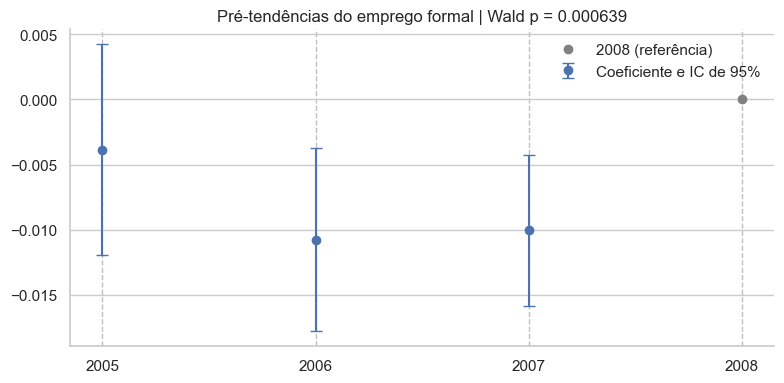

In [100]:
coef_pre = resultado_pre.params.loc[termos_pre]
ic_pre = resultado_pre.conf_int().loc[termos_pre]
assert np.isfinite(ic_pre).all().all()

fig, ax = plt.subplots(figsize=(8, 4))

# Ativa apenas as linhas verticais de fundo (baseadas nos ticks do eixo X)
ax.grid(axis="x", linestyle="--", alpha=0.5, color="gray")

ax.errorbar(
    anos_pre[:-1],
    coef_pre,
    yerr=[coef_pre - ic_pre["lower"], ic_pre["upper"] - coef_pre],
    fmt="o",
    capsize=4,
    label="Coeficiente e IC de 95%",
)

ax.plot(2008, 0, "o", color="gray", label="2008 (referência)")

ax.set(
    xticks=anos_pre,
    # xlabel="Ano", ylabel="Diferença no log do emprego por 1 DP de exposição",
    title=f"Pré-tendências do emprego formal | Wald p = {teste_pre.pval:.3g}",
)

# Remove as bordas superior e direita para manter o mesmo padrão limpo
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False)
fig.tight_layout()
plt.show()

##### Pré-tendências da massa salarial real sem controles

A proxy da massa salarial de dezembro é o estoque de vínculos ativos em 31 de dezembro multiplicado pela remuneração média de dezembro da RAIS. Aplicamos o fator de IPCA de dezembro de cada ano para expressar essa proxy em reais de dezembro de 2008. A medida representa a folha mensal aproximada em dezembro.

Seguimos a especificação do emprego formal. Usamos o log da proxy, efeitos fixos de município e ano, erros-padrão agrupados por município e 2008 como referência. A amostra inclui municípios com exposição vinculada e com estoque e remuneração positivos nos quatro anos de 2005 a 2008.

In [101]:
anos_pre_massa = [2005, 2006, 2007, 2008]
ipca_dezembro_pre = df_ipca.loc[
    df_ipca["ano"].isin(anos_pre_massa) & df_ipca["mes"].eq(12),
    ["ano", "fator_deflacao_dez_2008"],
].copy()

In [102]:
assert set(ipca_dezembro_pre["ano"]) == set(anos_pre_massa)
assert ipca_dezembro_pre["ano"].is_unique
fatores_dezembro_pre = ipca_dezembro_pre["fator_deflacao_dez_2008"]
assert np.isfinite(fatores_dezembro_pre).all() and fatores_dezembro_pre.gt(0).all()
assert np.isclose(ipca_dezembro_pre.loc[
    ipca_dezembro_pre["ano"].eq(2008), "fator_deflacao_dez_2008"
].item(), 1)

In [103]:
amostra_pre_massa = (
    painel_2005_2013["ano"].isin(anos_pre_massa)
    & painel_2005_2013["merge_exposicao"].eq("both")
    & painel_2005_2013["estoque_emprego"].gt(0)
    & painel_2005_2013["valor_remuneracao_dezembro"].gt(0)
)
pre_massa = painel_2005_2013.loc[amostra_pre_massa].merge(
    ipca_dezembro_pre, on="ano", how="left", validate="many_to_one"
)
anos_validos_massa = pre_massa.groupby("id_municipio")["ano"].transform("nunique")
pre_massa = pre_massa.loc[anos_validos_massa.eq(len(anos_pre_massa))].copy()

In [104]:
pre_massa["massa_salarial_proxy_real"] = (
    pre_massa["estoque_emprego"]
    * pre_massa["valor_remuneracao_dezembro"]
    * pre_massa["fator_deflacao_dez_2008"]
)
pre_massa["ln_massa_salarial"] = np.log(pre_massa["massa_salarial_proxy_real"])

In [105]:
assert set(pre_massa["ano"]) == set(anos_pre_massa)
assert not pre_massa.duplicated(["id_municipio", "ano"]).any()
assert np.isfinite(pre_massa[["ln_massa_salarial", "expo_padroniz_Z_i"]]).all().all()
assert pre_massa["expo_padroniz_Z_i"].nunique() > 1
print("Municípios nos quatro anos:", pre_massa["id_municipio"].nunique())

Municípios nos quatro anos: 5550


In [106]:
termos_pre_massa = []
for ano in anos_pre_massa[:-1]:
    termo = f"expo_{ano}"
    pre_massa[termo] = pre_massa["expo_padroniz_Z_i"] * pre_massa["ano"].eq(ano)
    termos_pre_massa.append(termo)

pre_massa_indexado = pre_massa.set_index(["id_municipio", "ano"])
modelo_pre_massa = PanelOLS(
    pre_massa_indexado["ln_massa_salarial"], pre_massa_indexado[termos_pre_massa],
    entity_effects=True, time_effects=True,
)
resultado_pre_massa = modelo_pre_massa.fit(cov_type="clustered", cluster_entity=True)

**Teste de Wald das pré-tendências.** O teste de Wald avalia conjuntamente se os coeficientes de exposição de 2005 a 2007 são iguais a zero, tomando 2008 como referência. Sob H₀, a variação da massa salarial real nesses anos, em relação a 2008, não difere conforme a exposição histórica do município ao Finame, medida por `Z_i`.

Ao nível de 5%, rejeita-se H₀ se o valor-p for menor ou igual a 0,05. Um valor-p maior indica que os dados não fornecem evidência suficiente para rejeitar H₀.

In [107]:
teste_pre_massa = resultado_pre_massa.wald_test(
    formula=[f"{termo} = 0" for termo in termos_pre_massa]
)
print(teste_pre_massa)

Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 18.6415
P-value: 0.0003
Distributed: chi2(3)


In [108]:
alpha_pre_massa = 0.05

if teste_pre_massa.pval >= alpha_pre_massa:
    print("Ao nível de 5%, o teste de Wald não rejeitou H₀. "
          "Os coeficientes pré-PSI são conjuntamente compatíveis com zero.")
elif teste_pre_massa.pval < alpha_pre_massa:
    print("Ao nível de 5%, o teste de Wald rejeitou H₀. "
          "Há evidência de que a trajetória da proxy de massa salarial real "
          "já diferia conforme a exposição ao Finame antes do PSI.")

Ao nível de 5%, o teste de Wald rejeitou H₀. Há evidência de que a trajetória da proxy de massa salarial real já diferia conforme a exposição ao Finame antes do PSI.


Cada ponto estima a diferença na variação do log da proxy de massa salarial real, em relação a 2008, associada a um desvio-padrão a mais de exposição. As barras mostram intervalos de confiança de 95%.

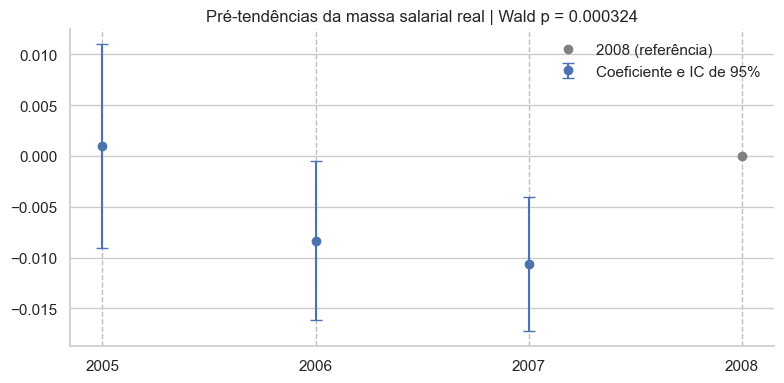

In [109]:
coef_pre_massa = resultado_pre_massa.params.loc[termos_pre_massa]
ic_pre_massa = resultado_pre_massa.conf_int().loc[termos_pre_massa]
assert np.isfinite(ic_pre_massa).all().all()

fig_massa, ax_massa = plt.subplots(figsize=(8, 4))

# Adiciona apenas linhas de grade verticais (baseadas nos ticks do eixo X)
ax_massa.grid(axis="x", linestyle="--", alpha=0.5, color="gray")

ax_massa.errorbar(
    anos_pre_massa[:-1],
    coef_pre_massa,
    yerr=[coef_pre_massa - ic_pre_massa["lower"], ic_pre_massa["upper"] - coef_pre_massa],
    fmt="o",
    capsize=4,
    label="Coeficiente e IC de 95%",
)

ax_massa.plot(2008, 0, "o", color="gray", label="2008 (referência)")
ax_massa.set_xticks(anos_pre_massa)

# Remove as bordas superior e direita para um visual mais limpo (opcional)
ax_massa.spines["top"].set_visible(False)
ax_massa.spines["right"].set_visible(False)

# ax_massa.set_ylabel("Diferença no log da massa salarial por 1 DP de exposição")
ax_massa.set_title(f"Pré-tendências da massa salarial real | Wald p = {teste_pre_massa.pval:.3g}")
ax_massa.legend(frameon=False)

fig_massa.tight_layout()
plt.show()


##### Pré-tendências do emprego formal com controles

Este diagnóstico usa apenas 2005–2008, com 2008 como referência. Para comparar as especificações com e sem controles, usamos os mesmos municípios do DiD contínuo. Os controles são os logs do PIB per capita e da população e a participação industrial, todos medidos em 2005, interagidos com os indicadores de 2005, 2006 e 2007. As especificações com UF × ano incluem efeitos fixos de município e de UF × ano, que absorvem os efeitos de ano e permitem choques distintos por UF em cada ano. As duas primeiras especificações incluem efeitos fixos de município e ano. Os erros-padrão são agrupados por município em todas as especificações.

A participação industrial é o valor adicionado bruto da indústria dividido pelo PIB municipal, ambos de 2005 e a preços correntes, na base do PIB dos Municípios já carregada no notebook.

In [110]:
especificacao_uf_ano = "Com PIB per capita, população, indústria e UF × ano"

especificacao_tendencia = "Com PIB per capita, população, indústria, UF × ano e tendência linear"
termo_tendencia = "expo_tendencia_linear"

def regressores_evento(termos, controles, nome):
    if nome == especificacao_tendencia:
        return [termo for termo in termos if termo != "expo_2007"] + controles
    return termos + controles

def wald_pre_exposicao(resultado, termos_pre):
    restricoes = [f"{termo} = 0" for termo in termos_pre if termo in resultado.params.index]
    return resultado.wald_test(formula=restricoes)

def coeficientes_evento(resultado, termos):
    # Em 2007, a especificação com tendência fixa o desvio em zero.
    coef = resultado.params.reindex(termos, fill_value=0)
    ic = resultado.conf_int().reindex(termos, fill_value=0)
    return coef, ic

def efeitos_fixos_did(painel_indexado, especificacao):
    if especificacao not in (especificacao_uf_ano, especificacao_tendencia):
        return {"entity_effects": True, "time_effects": True}

    uf = painel_indexado["uf"]
    assert uf.notna().all()
    assert uf.groupby(level="id_municipio").nunique().eq(1).all()
    ano = painel_indexado.index.get_level_values("ano").astype(str)
    uf_ano = uf.astype(str).str.cat(ano, sep="_").rename("uf_ano")
    return {"entity_effects": True, "other_effects": uf_ano}

controles_2005 = populacao_painel.loc[populacao_painel["ano"].eq(2005), [
    "id_municipio", "pib_per_capita", "populacao_ibge_implicita"
]].copy()
assert controles_2005["id_municipio"].is_unique
controles_2005 = controles_2005.loc[
    controles_2005["pib_per_capita"].gt(0)
    & controles_2005["populacao_ibge_implicita"].gt(0)
].copy()
controles_2005["ln_pib_pc_2005"] = np.log(controles_2005["pib_per_capita"])
controles_2005["ln_pop_2005"] = np.log(controles_2005["populacao_ibge_implicita"])
# Participação da indústria no PIB municipal em 2005, em proporção.
base_industria = df_pib_munic_2002_2009
coluna_vab_industria = next(c for c in base_industria if c.startswith("Valor adicionado bruto da Indústria,"))
coluna_pib_2005 = next(c for c in base_industria if c.startswith("Produto Interno Bruto,"))
industria_2005 = base_industria.loc[base_industria["Ano"].eq(2005), [
    "Código do Município", coluna_vab_industria, coluna_pib_2005,
]].rename(columns={"Código do Município": "id_municipio"})
vab_industria = pd.to_numeric(industria_2005[coluna_vab_industria], errors="coerce")
pib_nominal = pd.to_numeric(industria_2005[coluna_pib_2005], errors="coerce")
industria_2005["participacao_industrial_2005"] = vab_industria.div(pib_nominal.where(pib_nominal.gt(0)))
participacao_industrial = industria_2005["participacao_industrial_2005"]
assert participacao_industrial.dropna().between(0, 1).all()
controles_2005 = controles_2005.merge(
    industria_2005[["id_municipio", "participacao_industrial_2005"]],
    on="id_municipio", how="left", validate="one_to_one",
)
print("Municípios sem participação industrial de 2005:",
      controles_2005["participacao_industrial_2005"].isna().sum())
controles_2005 = controles_2005.dropna(subset=["participacao_industrial_2005"])
variaveis_controle_emp = ["ln_pib_pc_2005", "ln_pop_2005", "participacao_industrial_2005"]
assert np.isfinite(controles_2005[variaveis_controle_emp]).all().all()

Municípios sem participação industrial de 2005: 0


In [111]:
anos_did_emp = list(range(2005, 2014))
linhas_validas_emp = (
    painel_2005_2013["ano"].isin(anos_did_emp)
    & painel_2005_2013["merge_exposicao"].eq("both")
    & painel_2005_2013["estoque_emprego"].gt(0)
)
did_emp = painel_2005_2013.loc[linhas_validas_emp, [
    "id_municipio", "ano", "uf", "estoque_emprego", "expo_padroniz_Z_i"
]].merge(controles_2005[["id_municipio"] + variaveis_controle_emp],
         on="id_municipio", how="left", validate="many_to_one")
print("Municípios elegíveis sem controles de 2005:",
      did_emp.loc[did_emp["ln_pib_pc_2005"].isna(), "id_municipio"].nunique())
did_emp = did_emp.dropna(subset=variaveis_controle_emp).copy()
anos_validos_did_emp = did_emp.groupby("id_municipio")["ano"].transform("nunique")
did_emp = did_emp.loc[anos_validos_did_emp.eq(len(anos_did_emp))].copy()
did_emp["ln_emprego"] = np.log(did_emp["estoque_emprego"])

Municípios elegíveis sem controles de 2005: 0


In [112]:
assert set(did_emp["ano"]) == set(anos_did_emp)
assert not did_emp.duplicated(["id_municipio", "ano"]).any()
assert np.isfinite(did_emp[["ln_emprego", "expo_padroniz_Z_i"] + variaveis_controle_emp]).all().all()
assert did_emp.groupby("id_municipio")["expo_padroniz_Z_i"].nunique().eq(1).all()
print("Municípios na amostra comum:", did_emp["id_municipio"].nunique())
print("Observações município-ano:", len(did_emp))

Municípios na amostra comum: 5549
Observações município-ano: 49941


In [113]:
anos_evento_emp = [ano for ano in anos_did_emp if ano != 2008]
termos_evento_emp = []
termos_controle_emp = []

for ano in anos_evento_emp:
    indicador_ano = did_emp["ano"].eq(ano)
    termo_expo = f"expo_{ano}"
    did_emp[termo_expo] = did_emp["expo_padroniz_Z_i"] * indicador_ano
    termos_evento_emp.append(termo_expo)
    for controle in variaveis_controle_emp:
        termo_controle = f"{controle}_x_{ano}"
        did_emp[termo_controle] = did_emp[controle] * indicador_ano
        termos_controle_emp.append(termo_controle)

did_emp["expo_pos"] = did_emp["expo_padroniz_Z_i"] * did_emp["ano"].ge(2010)
did_emp[termo_tendencia] = did_emp["expo_padroniz_Z_i"] * (did_emp["ano"] - 2008)
did_emp_indexado = did_emp.set_index(["id_municipio", "ano"])

In [114]:
anos_pre_controles_emp = [2005, 2006, 2007, 2008]
pre_controles_emp = did_emp.loc[did_emp["ano"].isin(anos_pre_controles_emp)].copy()
termos_pre_controles_emp = [f"expo_{ano}" for ano in anos_pre_controles_emp[:-1]]
controles_pre_emp = [
    f"{controle}_x_{ano}"
    for ano in anos_pre_controles_emp[:-1]
    for controle in variaveis_controle_emp
]

In [115]:
assert not pre_controles_emp.duplicated(["id_municipio", "ano"]).any()
assert pre_controles_emp.groupby("id_municipio")["ano"].nunique().eq(4).all()
assert pre_controles_emp["id_municipio"].nunique() == did_emp["id_municipio"].nunique()
assert np.isfinite(pre_controles_emp[
    ["ln_emprego"] + termos_pre_controles_emp + controles_pre_emp
]).all().all()
print("Municípios nos quatro anos:", pre_controles_emp["id_municipio"].nunique())
print("Observações município-ano:", len(pre_controles_emp))

Municípios nos quatro anos: 5549
Observações município-ano: 22196


In [116]:
pre_controles_emp_indexado = pre_controles_emp.set_index(["id_municipio", "ano"])
modelos_pre_controles_emp = {}
for nome, controles in {
    "Sem controles": [],
    "Com PIB per capita, população e indústria": controles_pre_emp,
    especificacao_uf_ano: controles_pre_emp,
    especificacao_tendencia: controles_pre_emp + [termo_tendencia],
}.items():
    modelo = PanelOLS(
        pre_controles_emp_indexado["ln_emprego"],
        pre_controles_emp_indexado[regressores_evento(termos_pre_controles_emp, controles, nome)],
        **efeitos_fixos_did(pre_controles_emp_indexado, nome),
    )
    modelos_pre_controles_emp[nome] = modelo.fit(
        cov_type="clustered", cluster_entity=True
    )

**Teste de Wald das pré-tendências.** O teste de Wald avalia conjuntamente se os coeficientes de exposição de 2005 a 2007 são iguais a zero, tomando 2008 como referência. Sob H₀, a variação do emprego formal nesses anos, em relação a 2008, não difere conforme a exposição histórica do município ao Finame, medida por `Z_i`. Na especificação com tendência linear, 2007 e 2008 ancoram a reta. Nessa especificação, H₀ é que os desvios de 2005 e 2006 em relação à reta sejam conjuntamente iguais a zero.

Ao nível de 5%, rejeita-se H₀ se o valor-p for menor ou igual a 0,05. Um valor-p maior indica que os dados não fornecem evidência suficiente para rejeitar H₀.

In [117]:
wald_pre_controles_emp = {}
for nome, resultado in modelos_pre_controles_emp.items():
    teste = wald_pre_exposicao(resultado, termos_pre_controles_emp)
    wald_pre_controles_emp[nome] = {"Wald": teste.stat, "p_valor": teste.pval}
tabela_wald_pre_controles_emp = pd.DataFrame(wald_pre_controles_emp).T.rename(index={
    especificacao_tendencia: "Com PIB per capita, população, participação industrial de 2005, UF × ano e tendência linear",
})
print(tabela_wald_pre_controles_emp.to_string())

                                                                                               Wald  p_valor
Sem controles                                                                               17.2486   0.0006
Com PIB per capita, população e indústria                                                    8.9705   0.0297
Com PIB per capita, população, indústria e UF × ano                                          5.2656   0.1534
Com PIB per capita, população, participação industrial de 2005, UF × ano e tendência linear  2.2665   0.3220


In [118]:
p_pre_tendencia_emp = wald_pre_controles_emp[especificacao_tendencia]["p_valor"]
print(f"Wald dos desvios de 2005 e 2006 em relação à tendência linear: p = {p_pre_tendencia_emp:.4g}")

Wald dos desvios de 2005 e 2006 em relação à tendência linear: p = 0.322


Os pontos comparam o diferencial no log do emprego por desvio-padrão de exposição em relação a 2008. As barras são intervalos de confiança de 95%. Na especificação com tendência, 2007 e 2008 têm desvio zero por construção. O teste de Wald avalia os coeficientes pré-PSI estimados em cada modelo.

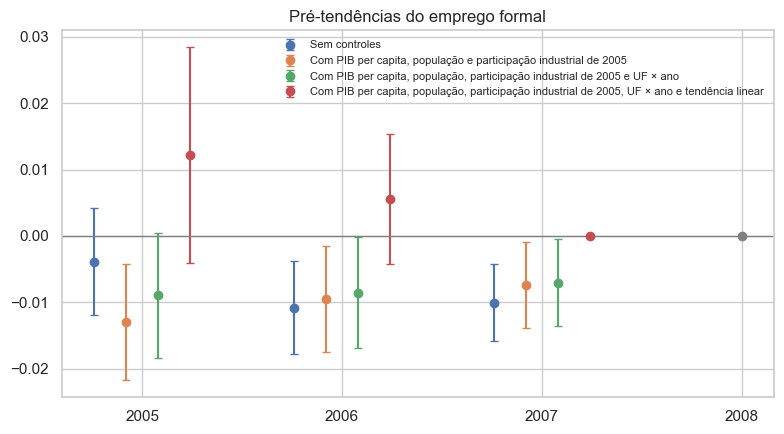

In [119]:
fig_pre_controles_emp, ax_pre_controles_emp = plt.subplots(figsize=(8, 4.5))
for deslocamento, (nome, resultado) in zip([-0.24, -0.08, 0.08, 0.24], modelos_pre_controles_emp.items()):
    coef, ic = coeficientes_evento(resultado, termos_pre_controles_emp)
    ax_pre_controles_emp.errorbar(
        np.array(anos_pre_controles_emp[:-1]) + deslocamento, coef,
        yerr=[coef - ic["lower"], ic["upper"] - coef],
        fmt="o", capsize=3, label=nome.replace("indústria", "participação industrial de 2005"),
    )
ax_pre_controles_emp.axhline(0, color="gray", linewidth=1)
ax_pre_controles_emp.plot(2008, 0, "o", color="gray")
ax_pre_controles_emp.set_xticks(anos_pre_controles_emp)
# ax_pre_controles_emp.set_ylabel("Diferença no log do emprego por 1 DP de exposição")
ax_pre_controles_emp.set_title("Pré-tendências do emprego formal")
ax_pre_controles_emp.legend(frameon=False, fontsize=8)
fig_pre_controles_emp.tight_layout()
plt.show()

##### Pré-tendências da massa salarial real com controles

Usamos o log da mesma proxy de massa salarial real, de 2005 a 2008, com 2008 como referência. Os controles são os logs do PIB per capita e da população e a participação industrial, todos medidos em 2005, interagidos com os indicadores de 2005, 2006 e 2007.

Para comparar as especificações, restringimos a amostra aos municípios com controles válidos. As duas últimas especificações usam efeitos fixos de município e UF × ano. A última acrescenta a tendência linear de exposição. As duas primeiras usam efeitos fixos de município e ano. Todos os modelos agrupam os erros-padrão por município. O teste de Wald avalia os três coeficientes pré-PSI nas especificações usuais e os desvios de 2005 e 2006 no modelo com tendência.

**Teste de Wald das pré-tendências.** A célula estima os modelos da massa salarial real, gera o gráfico e aplica o teste a cada especificação. O teste de Wald avalia conjuntamente se os coeficientes de exposição de 2005 a 2007 são iguais a zero, tomando 2008 como referência. Sob H₀, a variação da massa salarial real nesses anos, em relação a 2008, não difere conforme a exposição histórica do município ao Finame, medida por `Z_i`. Na especificação com tendência linear, 2007 e 2008 ancoram a reta. Nessa especificação, H₀ é que os desvios de 2005 e 2006 em relação à reta sejam conjuntamente iguais a zero.

Ao nível de 5%, rejeita-se H₀ se o valor-p for menor ou igual a 0,05. Um valor-p maior indica que os dados não fornecem evidência suficiente para rejeitar H₀.

Municípios na amostra comum: 5550
                                                                                               Wald  p_valor
Sem controles                                                                               18.6415   0.0003
Com PIB per capita, população e indústria                                                   12.0571   0.0072
Com PIB per capita, população, indústria e UF × ano                                          3.6173   0.3059
Com PIB per capita, população, participação industrial de 2005, UF × ano e tendência linear  0.9736   0.6146


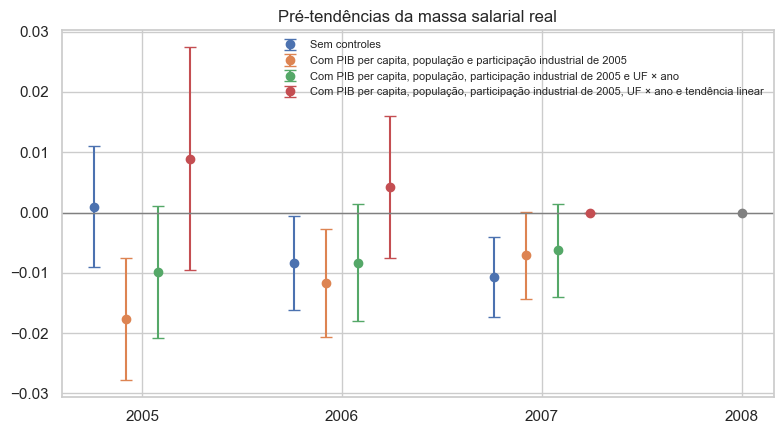

In [120]:
pre_massa_controles = pre_massa.merge(
    controles_2005[["id_municipio"] + variaveis_controle_emp],
    on="id_municipio", how="inner", validate="many_to_one",
)
assert pre_massa_controles.groupby("id_municipio")["ano"].nunique().eq(4).all()
print("Municípios na amostra comum:", pre_massa_controles["id_municipio"].nunique())

termos_controle_massa = []
for ano in anos_pre_massa[:-1]:
    for controle in variaveis_controle_emp:
        termo = f"{controle}_x_{ano}"
        pre_massa_controles[termo] = pre_massa_controles[controle] * pre_massa_controles["ano"].eq(ano)
        termos_controle_massa.append(termo)

pre_massa_controles[termo_tendencia] = (
    pre_massa_controles["expo_padroniz_Z_i"] * (pre_massa_controles["ano"] - 2008)
)
pre_massa_controles_indexado = pre_massa_controles.set_index(["id_municipio", "ano"])
modelos_pre_controles_massa = {}
wald_massa_controles = {}
fig_massa_controles, ax_massa_controles = plt.subplots(figsize=(8, 4.5))

for deslocamento, (nome, controles) in zip([-0.24, -0.08, 0.08, 0.24], {
    "Sem controles": [],
    "Com PIB per capita, população e indústria": termos_controle_massa,
    especificacao_uf_ano: termos_controle_massa,
    especificacao_tendencia: termos_controle_massa + [termo_tendencia],
}.items()):
    ajuste_massa = PanelOLS(
        pre_massa_controles_indexado["ln_massa_salarial"],
        pre_massa_controles_indexado[regressores_evento(termos_pre_massa, controles, nome)],
        **efeitos_fixos_did(pre_massa_controles_indexado, nome),
    ).fit(cov_type="clustered", cluster_entity=True)
    modelos_pre_controles_massa[nome] = ajuste_massa
    teste_massa = wald_pre_exposicao(ajuste_massa, termos_pre_massa)
    wald_massa_controles[nome] = {"Wald": teste_massa.stat, "p_valor": teste_massa.pval}

    coef, ic = coeficientes_evento(ajuste_massa, termos_pre_massa)
    ax_massa_controles.errorbar(
        np.array(anos_pre_massa[:-1]) + deslocamento, coef,
        yerr=[coef - ic["lower"], ic["upper"] - coef], fmt="o", capsize=4, label=nome.replace("indústria", "participação industrial de 2005"),
    )

tabela_wald_massa_controles = pd.DataFrame(wald_massa_controles).T.rename(index={
    especificacao_tendencia: "Com PIB per capita, população, participação industrial de 2005, UF × ano e tendência linear",
})
print(tabela_wald_massa_controles.to_string())
ax_massa_controles.axhline(0, color="gray", linewidth=1)
ax_massa_controles.plot(2008, 0, "o", color="gray")
ax_massa_controles.set_xticks(anos_pre_massa)
ax_massa_controles.set_title("Pré-tendências da massa salarial real")
# ax_massa_controles.set_ylabel("Diferença no log da massa salarial por 1 DP de exposição")
ax_massa_controles.legend(frameon=False, fontsize=8)
fig_massa_controles.tight_layout()
plt.show()

##### Comparação das pré-tendências de emprego e massa salarial

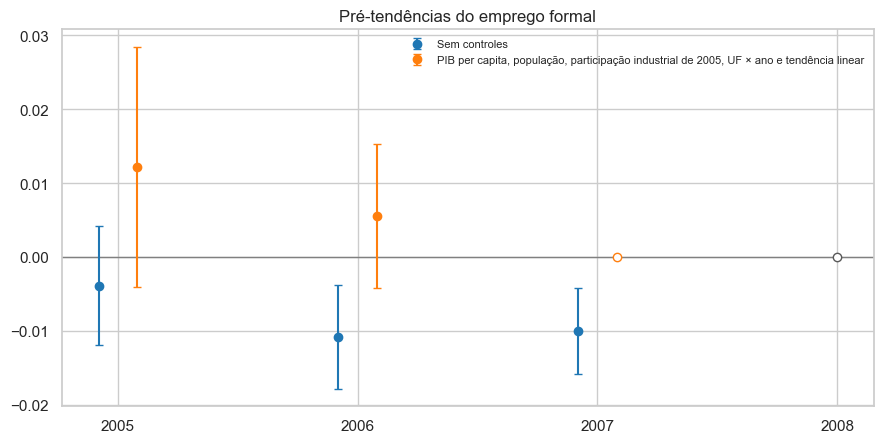

In [121]:
def plotar_especificacoes_exposicao(titulo, anos, modelos, destacar_transicao=False, mostrar_legenda=True):
    fig, eixo = plt.subplots(figsize=(9, 4.6))
    especificacoes = [
        ("Sem controles", "Sem controles", "tab:blue", -0.08),
        (especificacao_tendencia, "PIB per capita, população, participação industrial de 2005, UF × ano e tendência linear", "tab:orange", 0.08),
    ]
    eixo.axhline(0, color="0.5", linewidth=1)
    if destacar_transicao:
        eixo.axvspan(2008.5, 2009.5, color="0.5", alpha=0.12)
    for nome, rotulo, cor, deslocamento in especificacoes:
        resultado = modelos[nome]
        anos_estimados = [ano for ano in anos if f"expo_{ano}" in resultado.params.index]
        termos = [f"expo_{ano}" for ano in anos_estimados]
        coef = resultado.params.loc[termos]
        ic = resultado.conf_int().loc[termos]
        eixo.errorbar(
            np.array(anos_estimados) + deslocamento, coef,
            yerr=[coef - ic["lower"], ic["upper"] - coef],
            fmt="o", capsize=3, color=cor, label=rotulo,
        )
        if nome == especificacao_tendencia:
            eixo.plot(2007 + deslocamento, 0, "o", mfc="white", mec=cor)
    eixo.plot(2008, 0, "o", mfc="white", mec="0.35")
    eixo.set_title(titulo)
    eixo.set_xticks(anos)
    if mostrar_legenda:
        eixo.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    plt.show()


plotar_especificacoes_exposicao(
    "Pré-tendências do emprego formal", anos_pre_controles_emp, modelos_pre_controles_emp,
)

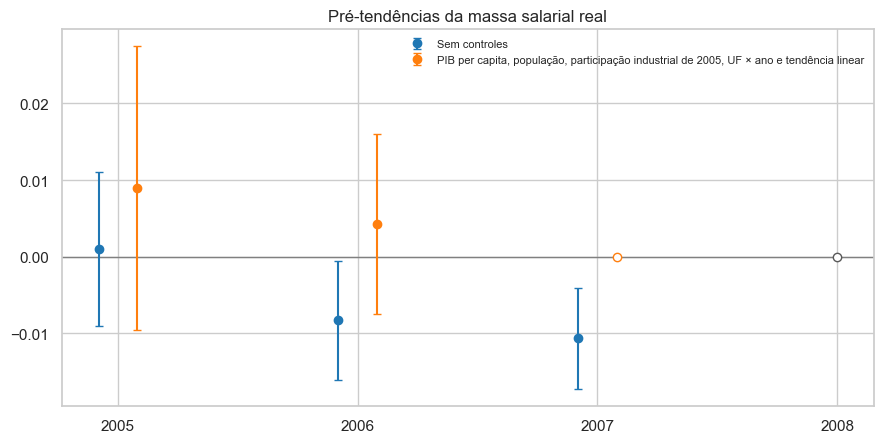

In [122]:
plotar_especificacoes_exposicao(
    "Pré-tendências da massa salarial real", anos_pre_massa, modelos_pre_controles_massa,
)

**Pré-tendências sem legenda**

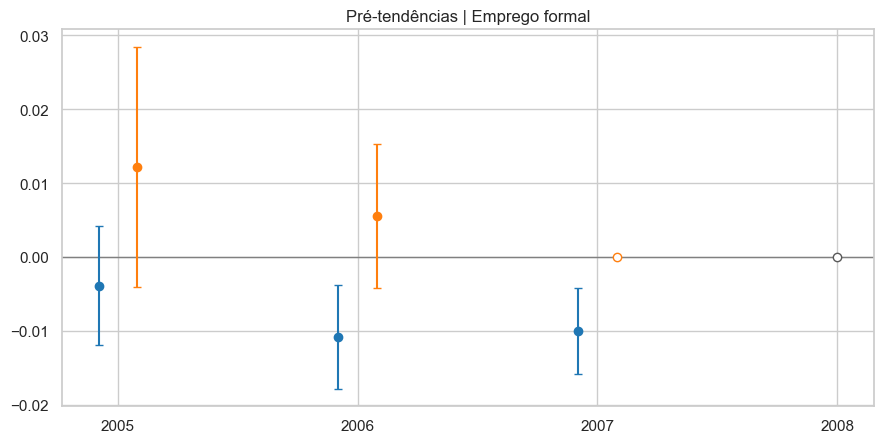

In [123]:
plotar_especificacoes_exposicao(
    "Pré-tendências | Emprego formal", anos_pre_controles_emp, modelos_pre_controles_emp,
    mostrar_legenda=False,
)

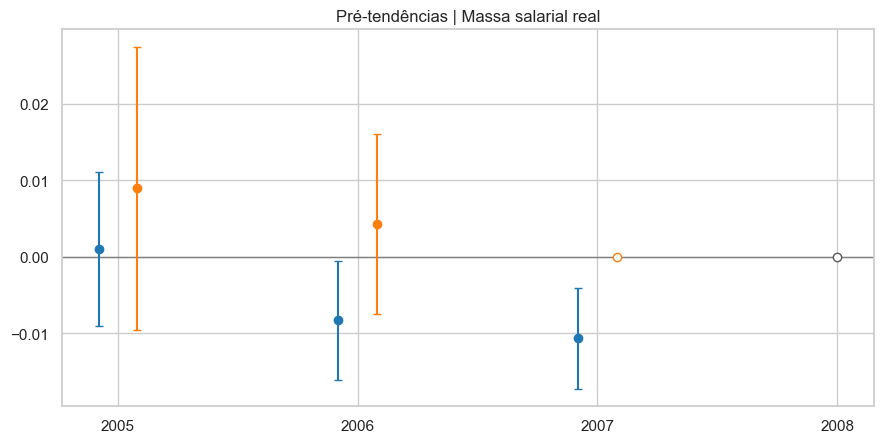

In [124]:
plotar_especificacoes_exposicao(
    "Pré-tendências | Massa salarial real", anos_pre_massa, modelos_pre_controles_massa,
    mostrar_legenda=False,
)

**Teste de Wald das pré-tendências.** O teste usa o modelo de emprego formal com PIB per capita, população, participação industrial, efeitos fixos de UF × ano e tendência linear da exposição histórica ao Finame. Na especificação com tendência linear, 2007 e 2008 ancoram a reta. Nessa especificação, H₀ é que os desvios de 2005 e 2006 em relação à reta sejam conjuntamente iguais a zero.

Ao nível de 5%, rejeita-se H₀ se o valor-p for menor ou igual a 0,05. Um valor-p maior indica que os dados não fornecem evidência suficiente para rejeitar H₀.

In [125]:
resultado_wald = wald_pre_exposicao(modelos_pre_controles_emp[especificacao_tendencia], termos_pre_controles_emp)
print("Wald — emprego formal com todos os controles (desvios de 2005 e 2006)")
print(resultado_wald)

Wald — emprego formal com todos os controles (desvios de 2005 e 2006)
Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 2.2665
P-value: 0.3220
Distributed: chi2(2)


##### Estudo de eventos do emprego formal

As covariáveis de 2005 incluem os logs do PIB per capita e da população implícita e a participação industrial no PIB. Interagimos essas covariáveis com os indicadores de ano para permitir trajetórias distintas conforme essas características. As duas últimas especificações absorvem efeitos fixos de UF × ano, que capturam choques comuns aos municípios da mesma UF em cada ano. A comparação entre os modelos usa os mesmos municípios, com emprego positivo e exposição vinculada nos nove anos e controles válidos em 2005. A cobertura da amostra é informada antes da estimação.

**diferencial médio**
 de 2010–2013, com 2009 como transição. Uma mudança no diagnóstico indica o quanto o ajuste por essas covariáveis altera a associação observada. Identificar sua causa exigiria evidência adicional.

In [126]:
especificacoes_emp = {
    "Sem controles": [],
    "Com PIB per capita, população e indústria": termos_controle_emp,
    especificacao_uf_ano: termos_controle_emp,
    especificacao_tendencia: termos_controle_emp + [termo_tendencia],
}
eventos_emp = {}
for nome, termos_controle in especificacoes_emp.items():
    modelo = PanelOLS(
        did_emp_indexado["ln_emprego"],
        did_emp_indexado[regressores_evento(termos_evento_emp, termos_controle, nome)],
        **efeitos_fixos_did(did_emp_indexado, nome),
    )
    eventos_emp[nome] = modelo.fit(cov_type="clustered", cluster_entity=True)

**Teste de Wald das pré-tendências.** O teste de Wald avalia conjuntamente se os coeficientes de exposição de 2005 a 2007 são iguais a zero, tomando 2008 como referência. Sob H₀, a variação do emprego formal nesses anos, em relação a 2008, não difere conforme a exposição histórica do município ao Finame, medida por `Z_i`. Na especificação com tendência linear, 2007 e 2008 ancoram a reta. Nessa especificação, H₀ é que os desvios de 2005 e 2006 em relação à reta sejam conjuntamente iguais a zero.

Ao nível de 5%, rejeita-se H₀ se o valor-p for menor ou igual a 0,05. Um valor-p maior indica que os dados não fornecem evidência suficiente para rejeitar H₀.

In [127]:
termos_wald_evento = [f"expo_{ano}" for ano in [2005, 2006, 2007]]
testes_pre_did_emp = {}
for nome, resultado in eventos_emp.items():
    wald = wald_pre_exposicao(resultado, termos_wald_evento)
    testes_pre_did_emp[nome] = {"Wald": wald.stat, "p_valor": wald.pval}
print(pd.DataFrame(testes_pre_did_emp).T.to_string())

                                                                         Wald  p_valor
Sem controles                                                         20.4428   0.0001
Com PIB per capita, população e indústria                             10.6317   0.0139
Com PIB per capita, população, indústria e UF × ano                    6.2468   0.1002
Com PIB per capita, população, indústria, UF × ano e tendência linear  2.6889   0.2607


O gráfico compara os coeficientes e seus intervalos de 95% nas quatro especificações. O ponto de 2008 é zero por definição. Os coeficientes de 2005–2007 servem para o diagnóstico de pré-tendências e 2009 aparece como ano de transição.

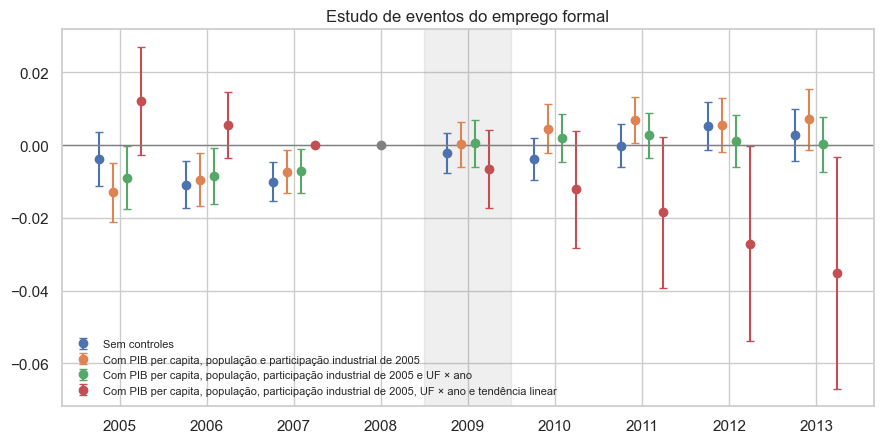

In [128]:
fig_did_emp, ax_did_emp = plt.subplots(figsize=(9, 4.6))
for deslocamento, (nome, resultado) in zip([-0.24, -0.08, 0.08, 0.24], eventos_emp.items()):
    coef, ic = coeficientes_evento(resultado, termos_evento_emp)
    ax_did_emp.errorbar(
        np.array(anos_evento_emp) + deslocamento, coef,
        yerr=[coef - ic["lower"], ic["upper"] - coef],
        fmt="o", capsize=3, label=nome.replace("indústria", "participação industrial de 2005"),
    )

ax_did_emp.axhline(0, color="gray", linewidth=1)
ax_did_emp.plot(2008, 0, "o", color="gray")
ax_did_emp.axvspan(2008.5, 2009.5, color="gray", alpha=0.12)
ax_did_emp.set_xticks(anos_did_emp)
# ax_did_emp.set_ylabel("Diferença no log do emprego por 1 DP de exposição")
ax_did_emp.set_title("Estudo de eventos do emprego formal")
ax_did_emp.legend(frameon=False, fontsize=8)
fig_did_emp.tight_layout()
plt.show()

**Diferencial médio pós-PSI.** O coeficiente de `expo_pos` compara 2010–2013 com 2005–2008. A interação `expo_2009` separa a transição. A leitura do coeficiente deve levar em conta o teste de pré-tendências.

In [129]:
resultados_pos_emp = {}
modelos_pos_emp = {}
for nome, termos_controle in especificacoes_emp.items():
    modelo = PanelOLS(
        did_emp_indexado["ln_emprego"],
        did_emp_indexado[["expo_pos", "expo_2009"] + termos_controle],
        **efeitos_fixos_did(did_emp_indexado, nome),
    )
    ajuste = modelo.fit(cov_type="clustered", cluster_entity=True)
    modelos_pos_emp[nome] = ajuste
    intervalo = ajuste.conf_int().loc["expo_pos"]
    resultados_pos_emp[nome] = {
        "coeficiente": ajuste.params["expo_pos"],
        "ic_95_inf": intervalo["lower"],
        "ic_95_sup": intervalo["upper"],
        "p_valor": ajuste.pvalues["expo_pos"],
    }
print(pd.DataFrame(resultados_pos_emp).T.to_string())

                                                                       coeficiente  ic_95_inf  ic_95_sup  p_valor
Sem controles                                                               0.0072     0.0007     0.0137   0.0293
Com PIB per capita, população e indústria                                   0.0135     0.0065     0.0206   0.0002
Com PIB per capita, população, indústria e UF × ano                         0.0077     0.0009     0.0144   0.0262
Com PIB per capita, população, indústria, UF × ano e tendência linear       0.0023    -0.0057     0.0104   0.5726


##### Estudo de eventos da massa salarial real

Usamos o log da massa salarial real de dezembro de 2005 a 2013. A medida multiplica o estoque de vínculos pela remuneração média de dezembro da RAIS e aplica o IPCA para expressar os valores em reais de dezembro de 2008. As quatro especificações usam os mesmos municípios, com exposição vinculada, componentes positivos em todos os anos e controles válidos em 2005.

Assim como no estudo de emprego formal, todos os modelos incluem efeitos fixos de município e erros-padrão agrupados por município. As especificações ajustadas interagem os logs do PIB per capita e da população e a participação industrial, todos medidos em 2005, com os indicadores de ano. As duas últimas especificações usam efeitos fixos de UF × ano no lugar dos efeitos de ano. A última também inclui a tendência linear da exposição. O gráfico usa 2008 como referência, destaca 2009 como transição e apresenta intervalos de confiança de 95%. O teste de Wald avalia os coeficientes de exposição de 2005 a 2007 ou, na especificação com tendência, os desvios de 2005 e 2006.

**Diferencial médio pós-PSI.** Uma regressão separada compara 2010–2013 com 2005–2008 e estima um coeficiente próprio para 2009. O coeficiente pós-PSI mede a diferença na variação do log da massa salarial real por desvio-padrão adicional de exposição. O diagnóstico de pré-tendências orienta a interpretação desse diferencial.

Amostra comum: 5549 municípios, 49941 observações


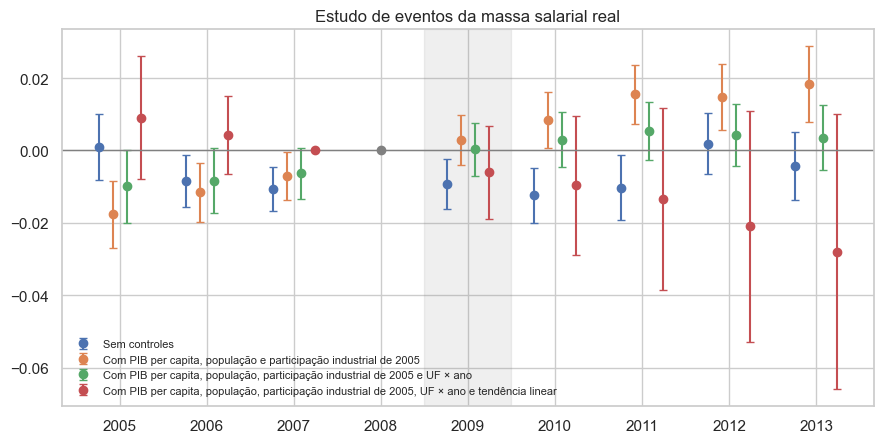

In [130]:
# Reaproveita os regressores e os critérios de elegibilidade do DiD do emprego.
chave_did_massa = ["id_municipio", "ano"]
ipca_evento_massa = df_ipca.loc[
    df_ipca["ano"].isin(anos_did_emp) & df_ipca["mes"].eq(12),
    ["ano", "fator_deflacao_dez_2008"],
]
assert set(ipca_evento_massa["ano"]) == set(anos_did_emp)
assert ipca_evento_massa["ano"].is_unique
fatores_evento_massa = ipca_evento_massa["fator_deflacao_dez_2008"]
assert np.isfinite(fatores_evento_massa).all() and fatores_evento_massa.gt(0).all()

did_massa = did_emp_indexado.reset_index().merge(
    painel_2005_2013[chave_did_massa + ["valor_remuneracao_dezembro"]],
    on=chave_did_massa, how="left", validate="one_to_one",
)
did_massa = did_massa.loc[did_massa["valor_remuneracao_dezembro"].gt(0)].merge(
    ipca_evento_massa, on="ano", how="left", validate="many_to_one",
)
observacoes_massa = did_massa.groupby("id_municipio")["ano"].transform("nunique")
did_massa = did_massa.loc[observacoes_massa.eq(len(anos_did_emp))].copy()
did_massa["ln_massa_salarial"] = np.log(
    did_massa["estoque_emprego"] * did_massa["valor_remuneracao_dezembro"]
    * did_massa["fator_deflacao_dez_2008"]
)
assert set(did_massa["ano"]) == set(anos_did_emp)
assert np.isfinite(did_massa["ln_massa_salarial"]).all()
did_massa_indexado = did_massa.set_index(chave_did_massa)
print(f"Amostra comum: {did_massa['id_municipio'].nunique()} municípios, {len(did_massa)} observações")

eventos_massa = {}
fig_did_massa, ax_did_massa = plt.subplots(figsize=(9, 4.6))
for deslocamento, (nome, controles) in zip([-0.24, -0.08, 0.08, 0.24], especificacoes_emp.items()):
    evento_massa = PanelOLS(
        did_massa_indexado["ln_massa_salarial"],
        did_massa_indexado[regressores_evento(termos_evento_emp, controles, nome)],
        **efeitos_fixos_did(did_massa_indexado, nome),
    ).fit(cov_type="clustered", cluster_entity=True)
    eventos_massa[nome] = evento_massa

    coef, ic = coeficientes_evento(evento_massa, termos_evento_emp)
    ax_did_massa.errorbar(
        np.array(anos_evento_emp) + deslocamento, coef,
        yerr=[coef - ic["lower"], ic["upper"] - coef], fmt="o", capsize=3, label=nome.replace("indústria", "participação industrial de 2005"),
    )

ax_did_massa.axhline(0, color="gray", linewidth=1)
ax_did_massa.plot(2008, 0, "o", color="gray")
ax_did_massa.axvspan(2008.5, 2009.5, color="gray", alpha=0.12)
ax_did_massa.set_xticks(anos_did_emp)
# ax_did_massa.set_ylabel("Diferença no log da massa salarial por 1 DP de exposição")
ax_did_massa.set_title("Estudo de eventos da massa salarial real")
ax_did_massa.legend(frameon=False, fontsize=8)
fig_did_massa.tight_layout()
plt.show()

**Teste de Wald das pré-tendências.** O teste de Wald avalia conjuntamente se os coeficientes de exposição de 2005 a 2007 são iguais a zero, tomando 2008 como referência. Sob H₀, a variação da massa salarial real nesses anos, em relação a 2008, não difere conforme a exposição histórica do município ao Finame, medida por `Z_i`. Na especificação com tendência linear, 2007 e 2008 ancoram a reta. Nessa especificação, H₀ é que os desvios de 2005 e 2006 em relação à reta sejam conjuntamente iguais a zero.

Ao nível de 5%, rejeita-se H₀ se o valor-p for menor ou igual a 0,05. Um valor-p maior indica que os dados não fornecem evidência suficiente para rejeitar H₀.

In [131]:
testes_pre_did_massa = {}
for nome, resultado in eventos_massa.items():
    teste = wald_pre_exposicao(resultado, termos_wald_evento)
    testes_pre_did_massa[nome] = {"Wald": teste.stat, "p_valor": teste.pval}

print("Teste de Wald das pré-tendências da massa salarial real (2005–2007)")
print(pd.DataFrame(testes_pre_did_massa).T.to_string(float_format="{:.6g}".format))

Teste de Wald das pré-tendências da massa salarial real (2005–2007)
                                                                         Wald     p_valor
Sem controles                                                         22.1105 6.18672e-05
Com PIB per capita, população e indústria                             14.2924  0.00253299
Com PIB per capita, população, indústria e UF × ano                   4.28722    0.232074
Com PIB per capita, população, indústria, UF × ano e tendência linear  1.1572    0.560684


##### Comparação dos estudos de eventos de emprego e massa salarial

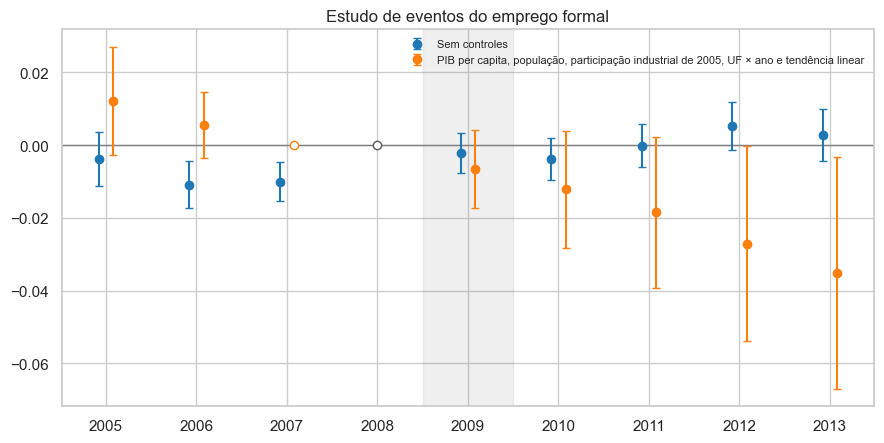

In [132]:
plotar_especificacoes_exposicao(
    "Estudo de eventos do emprego formal", anos_did_emp, eventos_emp, destacar_transicao=True,
)

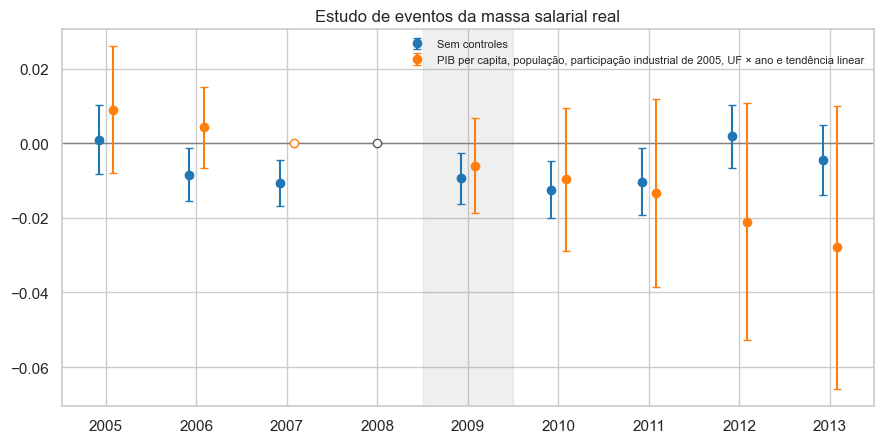

In [133]:
plotar_especificacoes_exposicao(
    "Estudo de eventos da massa salarial real", anos_did_emp, eventos_massa, destacar_transicao=True,
)

**Estudo de eventos sem legenda**

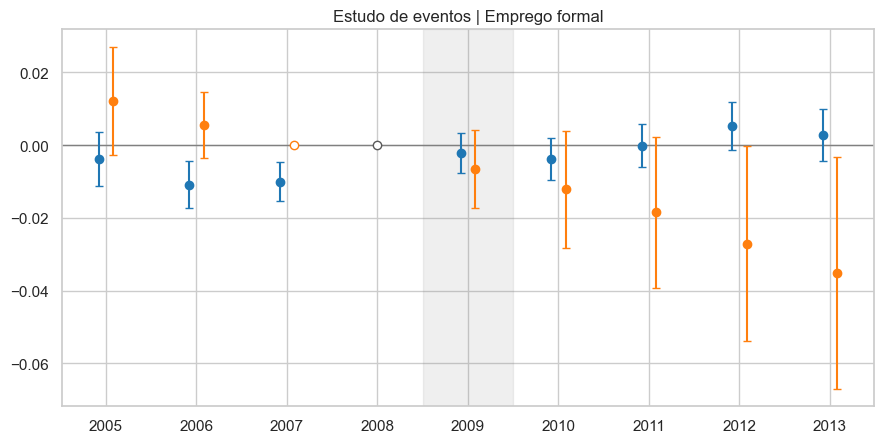

In [134]:
plotar_especificacoes_exposicao(
    "Estudo de eventos | Emprego formal", anos_did_emp, eventos_emp,
    destacar_transicao=True, mostrar_legenda=False,
)

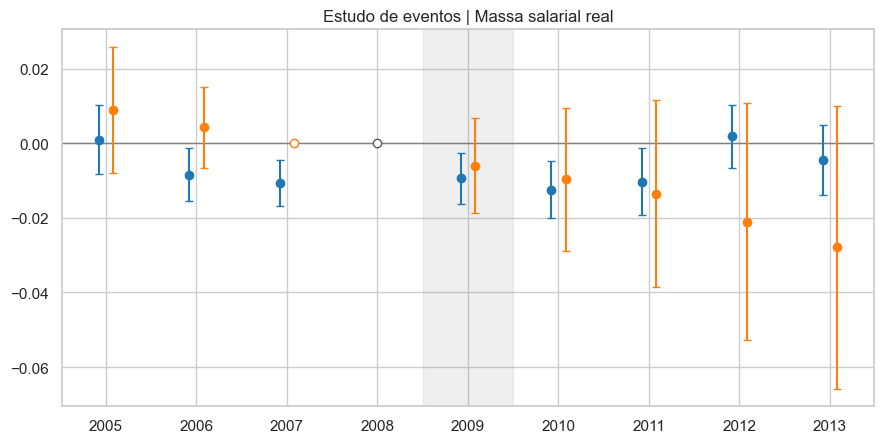

In [135]:
plotar_especificacoes_exposicao(
    "Estudo de eventos | Massa salarial real", anos_did_emp, eventos_massa,
    destacar_transicao=True, mostrar_legenda=False,
)

**Teste de Wald das pré-tendências** - massa salarial real

 O teste usa o modelo de massa salarial real com PIB per capita, população, participação industrial, efeitos fixos de UF × ano e tendência linear da exposição histórica ao Finame. Na especificação com tendência linear, 2007 e 2008 ancoram a reta. Nessa especificação, H₀ é que os desvios de 2005 e 2006 em relação à reta sejam conjuntamente iguais a zero.

Ao nível de 5%, rejeita-se H₀ se o valor-p for menor ou igual a 0,05. Um valor-p maior indica que os dados não fornecem evidência suficiente para rejeitar H₀.

In [136]:
resultado_wald = wald_pre_exposicao(eventos_massa[especificacao_tendencia], termos_wald_evento)
print("Wald — massa salarial real com todos os controles (desvios de 2005 e 2006)")
print(resultado_wald)

Wald — massa salarial real com todos os controles (desvios de 2005 e 2006)
Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 1.1572
P-value: 0.5607
Distributed: chi2(2)


**Diferencial médio pós-PSI** - massa salarial real

In [137]:
resultados_pos_massa = {}
modelos_pos_massa = {}
for nome, controles in especificacoes_emp.items():
    ajuste_pos_massa = PanelOLS(
        did_massa_indexado["ln_massa_salarial"],
        did_massa_indexado[["expo_pos", "expo_2009"] + controles],
        **efeitos_fixos_did(did_massa_indexado, nome),
    ).fit(cov_type="clustered", cluster_entity=True)
    modelos_pos_massa[nome] = ajuste_pos_massa
    ic_pos = ajuste_pos_massa.conf_int().loc["expo_pos"]
    resultados_pos_massa[nome] = {
        "coeficiente": ajuste_pos_massa.params["expo_pos"],
        "ic_95_inf": ic_pos["lower"],
        "ic_95_sup": ic_pos["upper"],
        "p_valor": ajuste_pos_massa.pvalues["expo_pos"],
    }

print("Diferencial médio pós-PSI (2010–2013 versus 2005–2008)")
print(pd.DataFrame(resultados_pos_massa).T.to_string(float_format="{:.6g}".format))

Diferencial médio pós-PSI (2010–2013 versus 2005–2008)
                                                                       coeficiente   ic_95_inf  ic_95_sup     p_valor
Sem controles                                                          -0.00179073  -0.0108658 0.00728435    0.698936
Com PIB per capita, população e indústria                                0.0233426   0.0143382  0.0323469 3.76819e-07
Com PIB per capita, população, indústria e UF × ano                      0.0101603  0.00235199  0.0179686   0.0107631
Com PIB per capita, população, indústria, UF × ano e tendência linear   0.00213599 -0.00697766  0.0112496    0.645968


##### DiD por faixas de exposição

O grupo de referência reúne os municípios com exposição original `E_i = 0`. Os três grupos expostos usam os percentis de 1/3 e 2/3 de `E_i` entre os municípios com exposição positiva vinculada no painel. Os cortes são calculados uma vez por município e usados nos dois desfechos. Municípios com valores iguais ao corte ficam na mesma faixa.

Os modelos incluem efeitos fixos de município e UF × ano, controles de PIB per capita, população e participação industrial de 2005 interagidos com ano e erros-padrão agrupados por município. Nesta análise, as interações de faixa substituem a exposição contínua e sua tendência linear. Cada estimativa compara a mudança de uma faixa com a do grupo de exposição zero.

O estudo de eventos usa 2008 como referência. O teste de Wald avalia conjuntamente os nove coeficientes de 2005–2007. A regressão do diferencial médio compara 2010–2013 com 2005–2008 e estima a transição de 2009 separadamente para cada faixa.

In [138]:
faixas_positivas = {1: "Tercil 1 (baixo)", 2: "Tercil 2 (médio)", 3: "Tercil 3 (alto)"}
exposicao_faixas = painel_2005_2013.loc[
    painel_2005_2013["merge_exposicao"].eq("both"), ["id_municipio", "pre_expo_E_i"]
].drop_duplicates().set_index("id_municipio")["pre_expo_E_i"]
assert exposicao_faixas.index.is_unique
assert np.isfinite(exposicao_faixas).all() and exposicao_faixas.ge(0).all()
positivos_faixas = exposicao_faixas[exposicao_faixas.gt(0)]
corte_baixo, corte_alto = positivos_faixas.quantile([1/3, 2/3])
assert 0 < corte_baixo < corte_alto, "A exposição positiva não permite três faixas distintas."
faixa_municipio = pd.Series(0, index=exposicao_faixas.index, name="faixa_exposicao")
faixa_municipio.loc[positivos_faixas.index] = pd.cut(
    positivos_faixas, bins=[0, corte_baixo, corte_alto, np.inf], labels=[1, 2, 3],
).astype(int)
print(f"Cortes da exposição positiva: {corte_baixo:.6g} e {corte_alto:.6g}")

painel_faixas = {}
for desfecho, painel in [
    ("Emprego formal", did_emp_indexado),
    ("Massa salarial real", did_massa_indexado),
]:
    dados = painel.join(faixa_municipio, on="id_municipio", validate="many_to_one")
    assert set(dados["faixa_exposicao"]) == {0, 1, 2, 3}
    ano = dados.index.get_level_values("ano")
    for faixa in faixas_positivas:
        grupo = dados["faixa_exposicao"].eq(faixa)
        for t in anos_evento_emp:
            dados[f"faixa_{faixa}_{t}"] = (grupo & (ano == t)).astype(int)
        dados[f"faixa_{faixa}_pos"] = (grupo & (ano >= 2010)).astype(int)
    painel_faixas[desfecho] = dados

contagens_faixas = pd.DataFrame({
    desfecho: dados["faixa_exposicao"].groupby(level="id_municipio").first().value_counts()
    for desfecho, dados in painel_faixas.items()
}).sort_index().rename(index={0: "Exposição zero", **faixas_positivas})
print(contagens_faixas.to_string())

Cortes da exposição positiva: 22.5334 e 79.6005
                  Emprego formal  Massa salarial real
faixa_exposicao                                      
Exposição zero              3457                 3457
Tercil 1 (baixo)             697                  697
Tercil 2 (médio)             698                  698
Tercil 3 (alto)              697                  697


**Teste de Wald das pré-tendências.** O teste avalia, separadamente para emprego formal e massa salarial real, se os nove coeficientes de pré-tendências são conjuntamente iguais a zero. Sob H₀, em 2005, 2006 e 2007, a variação de cada tercil de exposição positiva em relação a 2008 é igual à variação do grupo de exposição zero.

Ao nível de 5%, rejeita-se H₀ se o valor-p for menor ou igual a 0,05. Um valor-p maior indica que os dados não fornecem evidência suficiente para rejeitar H₀.

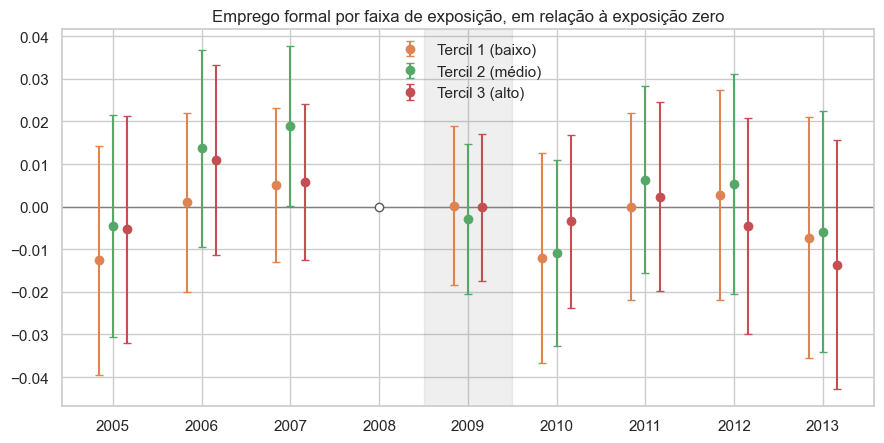

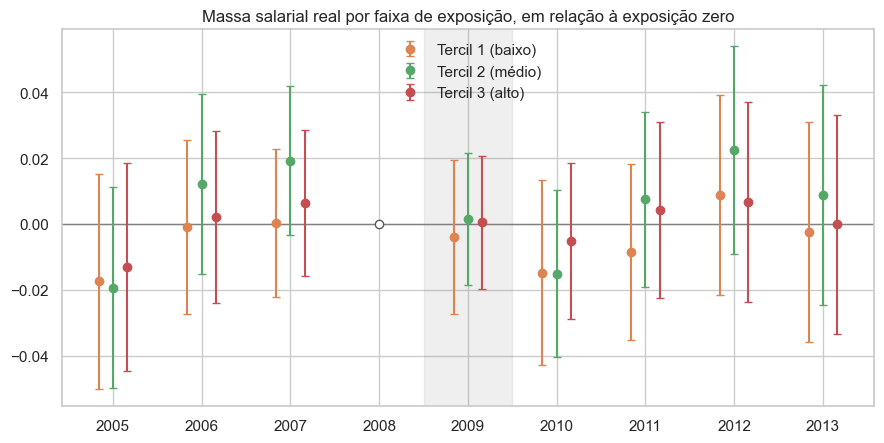

In [139]:
termos_eventos_faixas = [f"faixa_{faixa}_{ano}" for faixa in faixas_positivas for ano in anos_evento_emp]
restricoes_faixas = [f"faixa_{faixa}_{ano} = 0" for faixa in faixas_positivas for ano in anos_pre_massa[:-1]]
variaveis_desfecho_faixas = {"Emprego formal": "ln_emprego", "Massa salarial real": "ln_massa_salarial"}
wald_faixas = {}
testes_wald_faixas = {}
for desfecho, dependente in variaveis_desfecho_faixas.items():
    dados = painel_faixas[desfecho]
    resultado = PanelOLS(
        dados[dependente], dados[termos_eventos_faixas + termos_controle_emp],
        **efeitos_fixos_did(dados, especificacao_uf_ano),
    ).fit(cov_type="clustered", cluster_entity=True)
    teste = resultado.wald_test(formula=restricoes_faixas)
    testes_wald_faixas[desfecho] = teste
    wald_faixas[desfecho] = {"Wald": teste.stat, "p_valor": teste.pval}

    fig, eixo = plt.subplots(figsize=(9, 4.6))
    eixo.axhline(0, color="0.5", linewidth=1)
    eixo.axvspan(2008.5, 2009.5, color="0.5", alpha=0.12)
    eixo.plot(2008, 0, "o", mfc="white", mec="0.35")
    for deslocamento, (faixa, rotulo) in zip([-0.16, 0, 0.16], faixas_positivas.items()):
        termos = [f"faixa_{faixa}_{ano}" for ano in anos_evento_emp]
        coef = resultado.params.loc[termos]
        ic = resultado.conf_int().loc[termos]
        eixo.errorbar(
            np.array(anos_evento_emp) + deslocamento, coef,
            yerr=[coef - ic["lower"], ic["upper"] - coef], fmt="o", capsize=3, label=rotulo,
        )
    eixo.set_title(f"{desfecho} por faixa de exposição, em relação à exposição zero")
    eixo.set_xticks(anos_did_emp)
    eixo.legend(frameon=False)
    fig.tight_layout()
    plt.show()

In [140]:
print("Teste de Wald conjunto das pré-tendências por faixa")
print(pd.DataFrame(wald_faixas).T.to_string(float_format="{:.6g}".format))

Teste de Wald conjunto das pré-tendências por faixa
                       Wald  p_valor
Emprego formal      9.77685 0.368851
Massa salarial real 12.2284 0.200735


In [141]:
alpha_faixas = 0.005

for desfecho, resultado in wald_faixas.items():
    p_valor = resultado["p_valor"]

    if p_valor < alpha_faixas:
        conclusao = "rejeitamos H₀: há evidência de pré-tendências diferenciais por faixa."
    else:
        conclusao = (
            "não rejeitamos H₀: o teste não encontrou evidência suficiente "
            "de pré-tendências diferenciais por faixa."
        )

    print(f"{desfecho}: p = {p_valor:.4f}; {conclusao}")

Emprego formal: p = 0.3689; não rejeitamos H₀: o teste não encontrou evidência suficiente de pré-tendências diferenciais por faixa.
Massa salarial real: p = 0.2007; não rejeitamos H₀: o teste não encontrou evidência suficiente de pré-tendências diferenciais por faixa.


In [142]:
termos_pos_faixas = [f"faixa_{faixa}_pos" for faixa in faixas_positivas]
termos_transicao_faixas = [f"faixa_{faixa}_2009" for faixa in faixas_positivas]
resultados_pos_faixas = []
modelos_pos_faixas = {}
for desfecho, dependente in variaveis_desfecho_faixas.items():
    dados = painel_faixas[desfecho]
    ajuste = PanelOLS(
        dados[dependente], dados[termos_pos_faixas + termos_transicao_faixas + termos_controle_emp],
        **efeitos_fixos_did(dados, especificacao_uf_ano),
    ).fit(cov_type="clustered", cluster_entity=True)
    modelos_pos_faixas[desfecho] = ajuste
    ic = ajuste.conf_int()
    for faixa, termo in zip(faixas_positivas, termos_pos_faixas):
        resultados_pos_faixas.append({
            "Desfecho": desfecho, "Faixa": faixas_positivas[faixa],
            "coeficiente": ajuste.params[termo],
            "ic_95_inf": ic.loc[termo, "lower"], "ic_95_sup": ic.loc[termo, "upper"],
            "p_valor": ajuste.pvalues[termo],
        })
print("Diferencial médio pós-PSI por faixa, em relação à exposição zero")
print(pd.DataFrame(resultados_pos_faixas).set_index(["Desfecho", "Faixa"]).to_string(float_format="{:.6g}".format))

Diferencial médio pós-PSI por faixa, em relação à exposição zero
                                      coeficiente  ic_95_inf  ic_95_sup  p_valor
Desfecho            Faixa                                                       
Emprego formal      Tercil 1 (baixo)  -0.00253675 -0.0234105   0.018337  0.81173
                    Tercil 2 (médio)   -0.0082822 -0.0306704   0.014106 0.468406
                    Tercil 3 (alto)   -0.00766197 -0.0297936  0.0144696 0.497421
Massa salarial real Tercil 1 (baixo)  0.000201287 -0.0246569  0.0250594 0.987337
                    Tercil 2 (médio)   0.00286336 -0.0234602  0.0291869  0.83117
                    Tercil 3 (alto)    0.00255964 -0.0226079  0.0277272 0.841997


In [143]:
alpha_faixas = 0.05
for linha in resultados_pos_faixas:
    desfecho, faixa = linha["Desfecho"], linha["Faixa"]
    coeficiente, p_valor = linha["coeficiente"], linha["p_valor"]
    print(f"{desfecho} | {faixa} | p = {p_valor:.6g}")
    if not np.isfinite(p_valor):
        print("Valor-p indisponível para este contraste.")
    elif p_valor <= alpha_faixas:
        direcao = "maior" if coeficiente > 0 else "menor"
        print(
            "Rejeita-se H₀ de que o diferencial médio pós-PSI desta faixa "
            "em relação ao grupo de exposição zero é igual a zero. "
            f"A variação estimada do desfecho foi {direcao} nesta faixa."
        )
    else:
        print(
            "Não se rejeita H₀ a 5%. Os dados não fornecem evidência estatística "
            "de que a variação média pós-PSI desta faixa difira da observada "
            "no grupo de exposição zero."
        )
    print()

Emprego formal | Tercil 1 (baixo) | p = 0.81173
Não se rejeita H₀ a 5%. Os dados não fornecem evidência estatística de que a variação média pós-PSI desta faixa difira da observada no grupo de exposição zero.

Emprego formal | Tercil 2 (médio) | p = 0.468406
Não se rejeita H₀ a 5%. Os dados não fornecem evidência estatística de que a variação média pós-PSI desta faixa difira da observada no grupo de exposição zero.

Emprego formal | Tercil 3 (alto) | p = 0.497421
Não se rejeita H₀ a 5%. Os dados não fornecem evidência estatística de que a variação média pós-PSI desta faixa difira da observada no grupo de exposição zero.

Massa salarial real | Tercil 1 (baixo) | p = 0.987337
Não se rejeita H₀ a 5%. Os dados não fornecem evidência estatística de que a variação média pós-PSI desta faixa difira da observada no grupo de exposição zero.

Massa salarial real | Tercil 2 (médio) | p = 0.83117
Não se rejeita H₀ a 5%. Os dados não fornecem evidência estatística de que a variação média pós-PSI dest

##### Robustez com troca do ano-base dos controles municipais de 2005 para 2008.


A análise de sensibilidade verifica se o diferencial de emprego formal e massa salarial real se sustenta quando mudam a amostra, a forma funcional ou a janela de tempo. Parte das especificações anteriores rejeita a hipótese conjunta de pré-tendências nulas no teste de Wald, o que enfraquece uma leitura causal direta. A pergunta é **quais mecanismos são compatíveis com as pré-tendências observadas e com o diferencial pós-PSI?** Uma rejeição indica evidência de diferenças prévias sob a especificação testada. A ausência de rejeição, por si só, é insuficiente para estabelecer tendências paralelas ou identificar um efeito causal.

Em DiD contínuo, comparar respostas entre doses exige atenção à seleção entre níveis de exposição. A hipótese usual de tendências paralelas pode ser insuficiente para interpretar diferenças entre doses como efeitos causais marginais. Os quatro mecanismos abaixo são hipóteses para este estudo. [Callaway, Goodman-Bacon e Sant’Anna (2024), *Difference-in-Differences with a Continuous Treatment*](https://www.nber.org/papers/w32117).

1. **Seleção em trajetórias dinâmicas.** Municípios com maior exposição histórica ao Finame podem já ter crescido a ritmos diferentes antes do PSI. A tendência $Z_i \times (t-2008)$ permite descontar uma inclinação diferencial. A redução dos coeficientes pós-PSI nas regressões anteriores é compatível com essa hipótese, mas também pode refletir sensibilidade à forma funcional e ao modo de extrapolar a inclinação.
2. **Choques regionais e setoriais assimétricos em 2008–2009.** A crise pode ter afetado UFs e estruturas produtivas de forma desigual. Os efeitos fixos de UF × ano absorvem choques comuns dentro de cada UF em cada ano. A participação industrial interagida com ano permite trajetórias distintas conforme a composição produtiva. Reestimar sem 2009 é uma checagem de janela. Medir as covariáveis em 2008 testa a sensibilidade a características mais próximas do PSI, embora essas medidas também possam refletir a crise ou a própria exposição histórica.
3. **Valores extremos e não linearidade.** A cauda superior pode influenciar a inclinação do DiD contínuo. Excluir exposições acima dos percentis 99 e 95 e usar $\ln(1+E_i)$ são checagens complementares. A análise por tercis acima já relaxa a linearidade. Seus intervalos de confiança incluem zero, deixando espaço para diferenças de magnitude entre as faixas.
4. **Acesso ao PSI e substituição de crédito.** Exposição histórica zero ao Finame não implica ausência de acesso posterior ao PSI. Comparar a amostra total com a de exposição positiva ajuda a medir a dependência em relação ao grupo zero. Para verificar se esse grupo também recebeu o choque de crédito, é preciso cruzar a exposição histórica com os desembolsos posteriores do PSI. A restrição de amostra, isoladamente, não identifica substituição de crédito nem efeitos indiretos.

Na discussão do artigo, apresente lado a lado os coeficientes, intervalos de confiança e testes de Wald. A sensibilidade à tendência linear e a UF × ano é compatível com seleção em trajetórias e choques regionais. A hipótese de ampliação do acesso ao PSI entre municípios com exposição histórica zero precisa ser confrontada com seus desembolsos observados. Essa leitura evita atribuir o diferencial a um mecanismo único.

**Controles ancorados em 2008.** As células abaixo comparam 2005 e 2008 numa amostra comum aos dois anos-base e aos dois desfechos. O ano-base define quando medimos o log do PIB per capita, o log da população e a participação da indústria no PIB. As covariáveis são fixadas nesse ano e interagidas com indicadores anuais. As regressões mantêm 2008 como referência, 2009 como transição, efeitos fixos de município e UF × ano e erros-padrão agrupados por município. Cada ano-base é estimado com e sem tendência linear. O Wald reportado vem do estudo de eventos de 2005–2013 e testa 2005–2007 sem tendência ou os desvios de 2005–2006 com tendência, pois 2007 e 2008 ancoram a reta. Os demais recortes e formas funcionais acima descrevem checagens complementares.

In [144]:
covariaveis_ancora = ["ln_pib_pc", "ln_pop", "participacao_industrial"]
base_2008 = df_pib_munic_2002_2009.loc[df_pib_munic_2002_2009["Ano"].eq(2008), [
    "Código do Município", coluna_vab_industria, coluna_pib_2005,
]].rename(columns={"Código do Município": "id_municipio"})
pib_2008 = pd.to_numeric(base_2008[coluna_pib_2005], errors="coerce")
vab_industrial_2008 = pd.to_numeric(base_2008[coluna_vab_industria], errors="coerce")
base_2008["participacao_industrial"] = vab_industrial_2008.div(pib_2008.where(pib_2008.gt(0)))
assert base_2008["participacao_industrial"].dropna().between(0, 1).all()

controles_2008 = populacao_painel.loc[populacao_painel["ano"].eq(2008), [
    "id_municipio", "pib_per_capita", "populacao_ibge_implicita",
]].merge(
    base_2008[["id_municipio", "participacao_industrial"]],
    on="id_municipio", how="left", validate="one_to_one",
).set_index("id_municipio")
controles_2008["ln_pib_pc"] = np.log(controles_2008["pib_per_capita"].where(controles_2008["pib_per_capita"].gt(0)))
controles_2008["ln_pop"] = np.log(controles_2008["populacao_ibge_implicita"].where(controles_2008["populacao_ibge_implicita"].gt(0)))
controles_por_ancora = {
    2005: controles_2005.set_index("id_municipio")[variaveis_controle_emp].set_axis(covariaveis_ancora, axis=1),
    2008: controles_2008[covariaveis_ancora],
}
paineis_robustez = {
    "Emprego formal": (did_emp_indexado, "ln_emprego"),
    "Massa salarial real": (did_massa_indexado, "ln_massa_salarial"),
}
municipios_robustez = controles_por_ancora[2005].dropna().index.intersection(
    controles_por_ancora[2008].dropna().index
)
for painel, _ in paineis_robustez.values():
    municipios_robustez = municipios_robustez.intersection(painel.index.get_level_values("id_municipio"))
assert len(municipios_robustez) > 0
print("Municípios na amostra comum:", len(municipios_robustez))

Municípios na amostra comum: 5549


In [145]:
resultados_ancoras = []
modelos_ancoras = {}
for desfecho, (painel, dependente) in paineis_robustez.items():
    painel_comum = painel.loc[painel.index.get_level_values("id_municipio").isin(municipios_robustez)]
    assert len(painel_comum) == len(municipios_robustez) * len(anos_did_emp)
    for ano_base, controles_base in controles_por_ancora.items():
        dados = painel_comum.join(controles_base, on="id_municipio", validate="many_to_one")
        ano = dados.index.get_level_values("ano")
        termos_ancora = []
        for t in anos_evento_emp:
            for controle in covariaveis_ancora:
                termo = f"{controle}_ancora_x_{t}"
                dados[termo] = dados[controle] * (ano == t)
                termos_ancora.append(termo)
        assert np.isfinite(dados[termos_ancora]).all().all()

        efeitos = efeitos_fixos_did(dados, especificacao_uf_ano)
        for com_tendencia in [False, True]:
            nome = especificacao_tendencia if com_tendencia else especificacao_uf_ano
            termos = termos_ancora + ([termo_tendencia] if com_tendencia else [])
            eventos_ancora = PanelOLS(
                dados[dependente], dados[regressores_evento(termos_evento_emp, termos, nome)],
                **efeitos,
            ).fit(cov_type="clustered", cluster_entity=True)
            teste = wald_pre_exposicao(eventos_ancora, termos_wald_evento)
            ajuste = PanelOLS(
                dados[dependente], dados[["expo_pos", "expo_2009"] + termos],
                **efeitos,
            ).fit(cov_type="clustered", cluster_entity=True)
            modelos_ancoras[desfecho, ano_base, com_tendencia] = (ajuste, teste)
            ic = ajuste.conf_int().loc["expo_pos"]
            resultados_ancoras.append({
                "Desfecho": desfecho, "Ano-base": ano_base, "Tendência": "Sim" if com_tendencia else "Não",
                "Wald": teste.stat, "p_Wald": teste.pval, "Diferencial": ajuste.params["expo_pos"],
                "IC 95% inf.": ic["lower"], "IC 95% sup.": ic["upper"], "p_DiD": ajuste.pvalues["expo_pos"],
            })

tabela_ancoras = pd.DataFrame(resultados_ancoras).set_index(["Desfecho", "Ano-base", "Tendência"])
print(tabela_ancoras.to_string(float_format="{:.4f}".format))

                                         Wald  p_Wald  Diferencial  IC 95% inf.  IC 95% sup.  p_DiD
Desfecho            Ano-base Tendência                                                             
Emprego formal      2005     Não       6.2468  0.1002       0.0077       0.0009       0.0144 0.0262
                             Sim       2.6889  0.2607       0.0023      -0.0057       0.0104 0.5726
                    2008     Não       3.7922  0.2848       0.0025      -0.0045       0.0094 0.4877
                             Sim       2.6470  0.2662       0.0009      -0.0073       0.0091 0.8276
Massa salarial real 2005     Não       4.2872  0.2321       0.0102       0.0024       0.0180 0.0108
                             Sim       1.1572  0.5607       0.0021      -0.0070       0.0112 0.6460
                    2008     Não       2.3331  0.5062       0.0041      -0.0041       0.0122 0.3258
                             Sim       1.4744  0.4784       0.0002      -0.0091       0.0094 0.9703


**Robustez à troca do ano-base dos controles de 2005 para 2008**

A referência sem controles usa a mesma amostra comum e efeitos fixos de município e ano. Seu coeficiente e seu intervalo de confiança de 95% são constantes entre 2005 e 2008, pois a regressão de referência independe do ano-base.

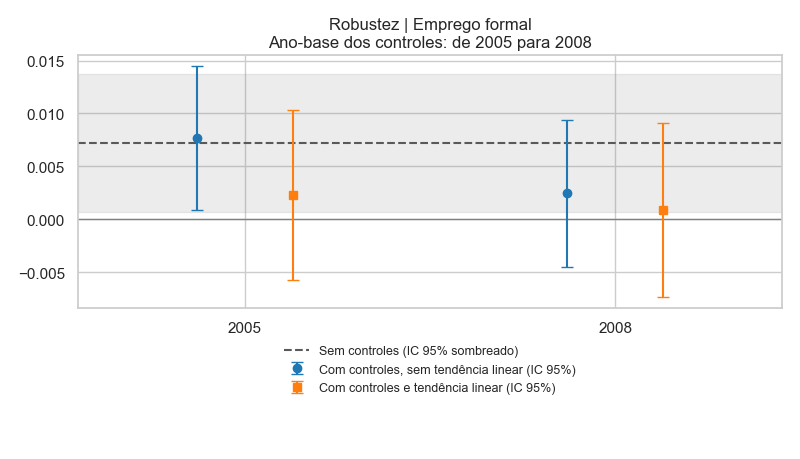

In [146]:
referencias_sem_controles = {}
for desfecho, (painel, dependente) in paineis_robustez.items():
    dados = painel.loc[painel.index.get_level_values("id_municipio").isin(municipios_robustez)]
    ajuste = PanelOLS(
        dados[dependente], dados[["expo_pos", "expo_2009"]],
        entity_effects=True, time_effects=True,
    ).fit(cov_type="clustered", cluster_entity=True)
    referencias_sem_controles[desfecho] = (
        ajuste.params["expo_pos"], ajuste.conf_int().loc["expo_pos"],
    )


def plotar_diferencial_ancoras(desfecho, mostrar_legenda):
    fig, eixo = plt.subplots(figsize=(8, 4.6))
    anos_base = list(controles_por_ancora)
    posicoes = np.arange(len(anos_base))
    eixo.axhline(0, color="0.5", linewidth=1)

    coef_ref, ic_ref = referencias_sem_controles[desfecho]
    eixo.axhspan(ic_ref["lower"], ic_ref["upper"], color="0.5", alpha=0.15)
    eixo.axhline(coef_ref, color="0.35", linestyle="--", label="Sem controles (IC 95% sombreado)")

    estilos = [
        ("Não", "Com controles, sem tendência linear", "tab:blue", "o", -0.13),
        ("Sim", "Com controles e tendência linear", "tab:orange", "s", 0.13),
    ]
    for tendencia, rotulo, cor, marcador, deslocamento in estilos:
        resultados = tabela_ancoras.xs(
            (desfecho, tendencia), level=("Desfecho", "Tendência"),
        ).reindex(anos_base)
        coef = resultados["Diferencial"]
        eixo.errorbar(
            posicoes + deslocamento, coef,
            yerr=[coef - resultados["IC 95% inf."], resultados["IC 95% sup."] - coef],
            fmt=marcador, color=cor, capsize=4, label=f"{rotulo} (IC 95%)",
        )
    eixo.set_title(f"Robustez | {desfecho}\nAno-base dos controles: de 2005 para 2008")
    eixo.set_xticks(posicoes, [str(ano) for ano in anos_base])
    eixo.set_xlim(-0.45, len(posicoes) - 0.55)
    fig.tight_layout(rect=(0, 0.23, 1, 1))
    if mostrar_legenda:
        eixo.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.10))
    with BytesIO() as imagem:
        fig.savefig(imagem, format="png", bbox_inches=fig.bbox_inches)
        display(Image(data=imagem.getvalue()))
    plt.close(fig)


plotar_diferencial_ancoras("Emprego formal", mostrar_legenda=True)

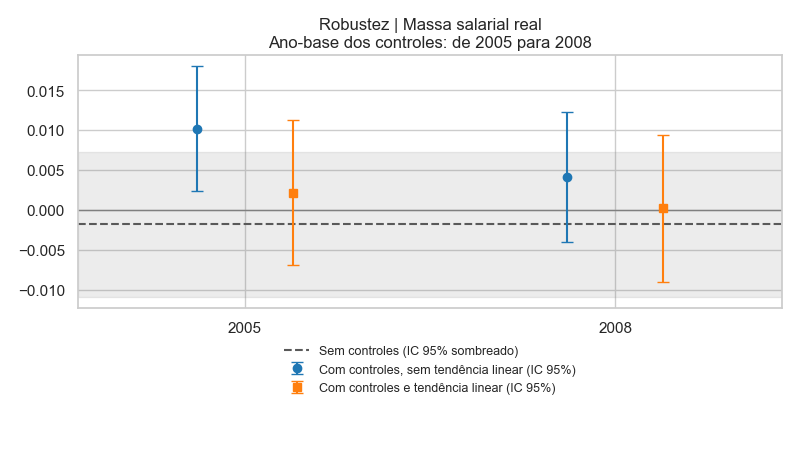

In [147]:
plotar_diferencial_ancoras("Massa salarial real", mostrar_legenda=True)

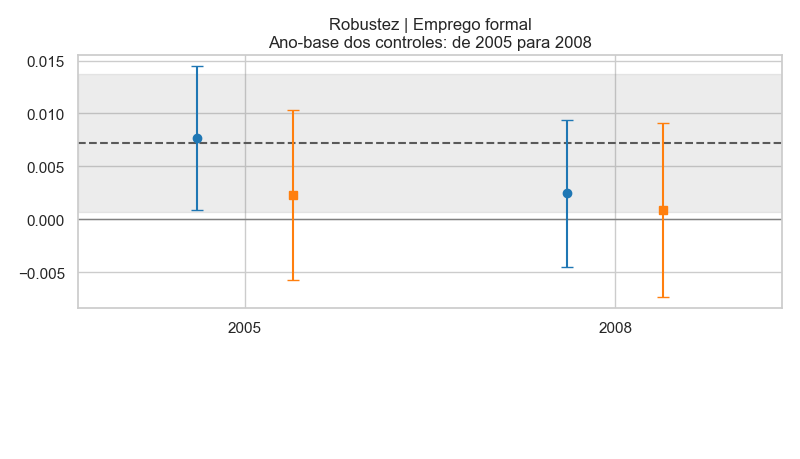

In [148]:
plotar_diferencial_ancoras("Emprego formal", mostrar_legenda=False)

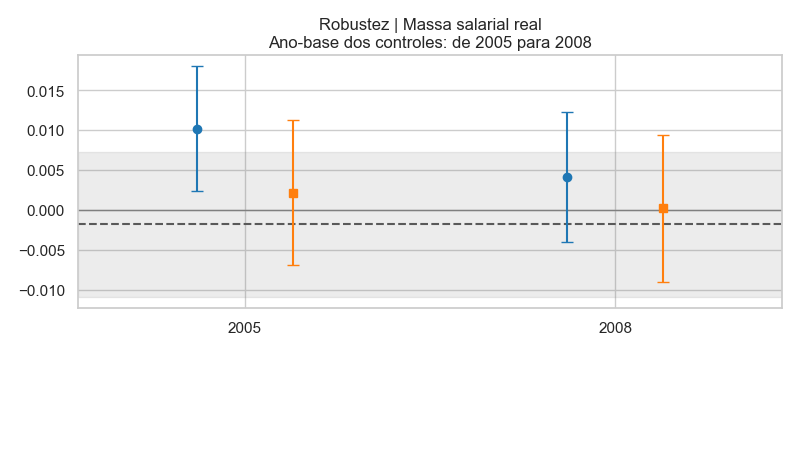

In [149]:
plotar_diferencial_ancoras("Massa salarial real", mostrar_legenda=False)

##### Robustez à transformação logarítmica da exposição

Esta checagem compara a exposição histórica original $E_i$ com $\ln(1+E_i)$. A transformação preserva os municípios com exposição zero e comprime a cauda superior. Para comparar os coeficientes, padronizamos separadamente as duas medidas na mesma amostra municipal, com uma observação por município. Cada coeficiente representa o diferencial associado a um desvio-padrão da respectiva medida.

Estimamos dois modelos por medida e desfecho. O modelo sem controles inclui efeitos fixos de município e ano. O modelo completo usa PIB per capita, população e participação industrial de 2005 interagidos com ano, efeitos fixos de município e UF × ano e uma tendência linear construída com a exposição de cada modelo. Mantemos 2008 como referência, 2009 como transição e 2010–2013 como período pós-PSI. Os erros-padrão são agrupados por município.

A tabela apresenta o Wald conjunto do estudo de eventos e o diferencial médio pós-PSI. Sem tendência, o Wald testa os coeficientes de 2005–2007. Com tendência, 2007 e 2008 ancoram a reta e o Wald testa os desvios de 2005 e 2006. Mudanças nos resultados indicam sensibilidade à forma funcional da exposição. A transformação, por si só, não identifica o peso de municípios específicos nem resolve a seleção entre níveis de exposição.

In [150]:
exposicao_amostra_log = exposicao_faixas.reindex(municipios_robustez)
assert np.isfinite(exposicao_amostra_log).all() and exposicao_amostra_log.ge(0).all()
medidas_exposicao_log = pd.DataFrame({
    "Exposição original": exposicao_amostra_log,
    "ln(1 + Eᵢ)": np.log1p(exposicao_amostra_log),
})
desvios_exposicao_log = medidas_exposicao_log.std()
assert desvios_exposicao_log.gt(0).all()
medidas_exposicao_log = (medidas_exposicao_log - medidas_exposicao_log.mean()) / desvios_exposicao_log

resultados_robustez_log = []
modelos_robustez_log = {}
for desfecho, (painel, dependente) in paineis_robustez.items():
    dados = painel.loc[painel.index.get_level_values("id_municipio").isin(municipios_robustez)].copy()
    assert len(dados) == len(municipios_robustez) * len(anos_did_emp)
    ano = dados.index.get_level_values("ano")
    ids_municipais = dados.index.get_level_values("id_municipio")
    for medida, exposicao in medidas_exposicao_log.items():
        z = ids_municipais.map(exposicao).to_numpy()
        for t in anos_evento_emp:
            dados[f"expo_{t}"] = z * (ano == t)
        dados["expo_pos"] = z * (ano >= 2010)
        dados[termo_tendencia] = z * (ano - 2008)

        for rotulo, nome, termos in [
            ("Sem controles", "Sem controles", []),
            ("Com todos os controles", especificacao_tendencia, termos_controle_emp + [termo_tendencia]),
        ]:
            efeitos = efeitos_fixos_did(dados, nome)
            evento = PanelOLS(
                dados[dependente], dados[regressores_evento(termos_evento_emp, termos, nome)], **efeitos,
            ).fit(cov_type="clustered", cluster_entity=True)
            teste = wald_pre_exposicao(evento, termos_wald_evento)
            ajuste = PanelOLS(
                dados[dependente], dados[["expo_pos", "expo_2009"] + termos], **efeitos,
            ).fit(cov_type="clustered", cluster_entity=True)
            modelos_robustez_log[desfecho, medida, rotulo] = (ajuste, teste)
            ic = ajuste.conf_int().loc["expo_pos"]
            resultados_robustez_log.append({
                "Desfecho": desfecho, "Medida": medida, "Modelo": rotulo,
                "Wald": teste.stat, "p_Wald": teste.pval, "Diferencial": ajuste.params["expo_pos"],
                "IC 95% inf.": ic["lower"], "IC 95% sup.": ic["upper"], "p_DiD": ajuste.pvalues["expo_pos"],
            })

tabela_robustez_log = pd.DataFrame(resultados_robustez_log).set_index(["Desfecho", "Medida", "Modelo"])
print(f"Municípios na amostra comum: {len(municipios_robustez)}")
print(tabela_robustez_log.to_string(float_format="{:.4f}".format))

Municípios na amostra comum: 5549
                                                                 Wald  p_Wald  Diferencial  IC 95% inf.  IC 95% sup.  p_DiD
Desfecho            Medida             Modelo                                                                              
Emprego formal      Exposição original Sem controles          20.4428  0.0001       0.0072       0.0007       0.0137 0.0293
                                       Com todos os controles  2.6889  0.2607       0.0023      -0.0057       0.0104 0.5726
                    ln(1 + Eᵢ)         Sem controles          25.6157  0.0000      -0.0083      -0.0154      -0.0012 0.0212
                                       Com todos os controles  3.5269  0.1714      -0.0036      -0.0140       0.0068 0.4931
Massa salarial real Exposição original Sem controles          22.1105  0.0001      -0.0018      -0.0109       0.0073 0.6989
                                       Com todos os controles  1.1572  0.5607       0.0021      -0

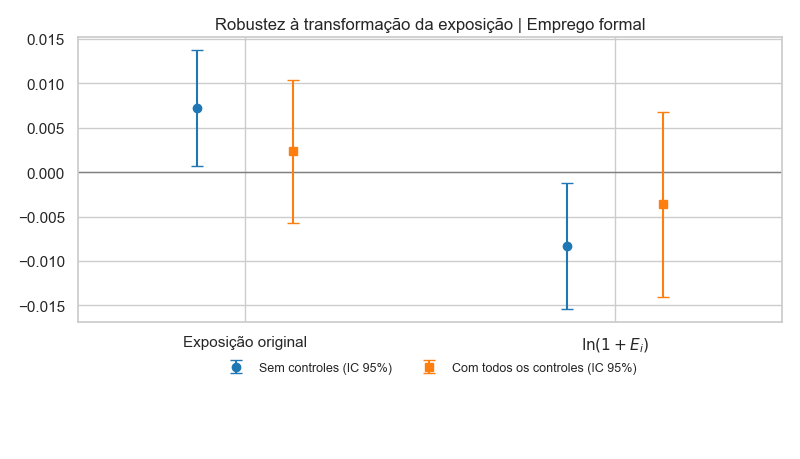

In [151]:
def plotar_robustez_log(desfecho, mostrar_legenda):
    fig, eixo = plt.subplots(figsize=(8, 4.6))
    medidas = list(medidas_exposicao_log)
    posicoes = np.arange(len(medidas))
    eixo.axhline(0, color="0.5", linewidth=1)
    for modelo, cor, marcador, deslocamento in [
        ("Sem controles", "tab:blue", "o", -0.13),
        ("Com todos os controles", "tab:orange", "s", 0.13),
    ]:
        resultados = tabela_robustez_log.xs((desfecho, modelo), level=("Desfecho", "Modelo")).reindex(medidas)
        coef = resultados["Diferencial"]
        eixo.errorbar(
            posicoes + deslocamento, coef,
            yerr=[coef - resultados["IC 95% inf."], resultados["IC 95% sup."] - coef],
            fmt=marcador, color=cor, capsize=4, label=f"{modelo} (IC 95%)",
        )
    eixo.set_title(f"Robustez à transformação da exposição | {desfecho}")
    eixo.set_xticks(posicoes, ["Exposição original", r"$\ln(1 + E_i)$"])
    eixo.set_xlim(-0.45, len(posicoes) - 0.55)
    fig.tight_layout(rect=(0, 0.19, 1, 1))
    if mostrar_legenda:
        eixo.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=2)
    with BytesIO() as imagem:
        fig.savefig(imagem, format="png", bbox_inches=fig.bbox_inches)
        display(Image(data=imagem.getvalue()))
    plt.close(fig)


plotar_robustez_log("Emprego formal", mostrar_legenda=True)

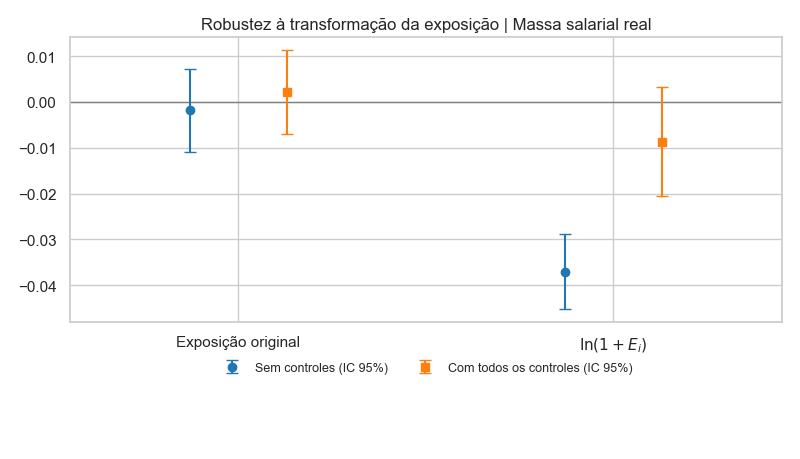

In [152]:
plotar_robustez_log("Massa salarial real", mostrar_legenda=True)

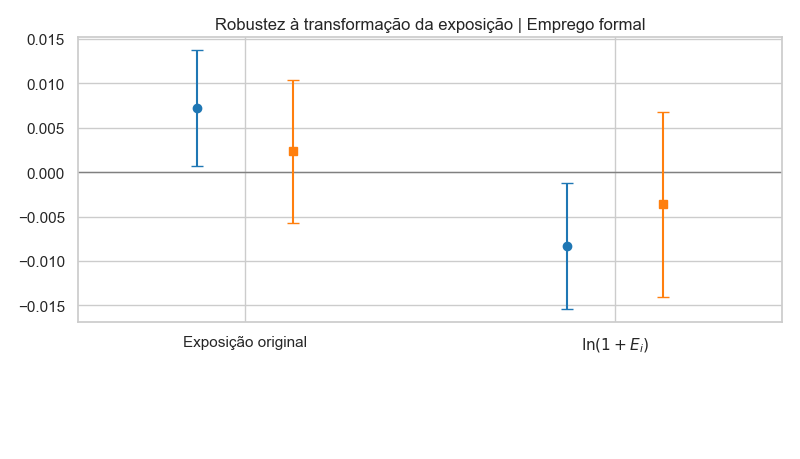

In [153]:
plotar_robustez_log("Emprego formal", mostrar_legenda=False)

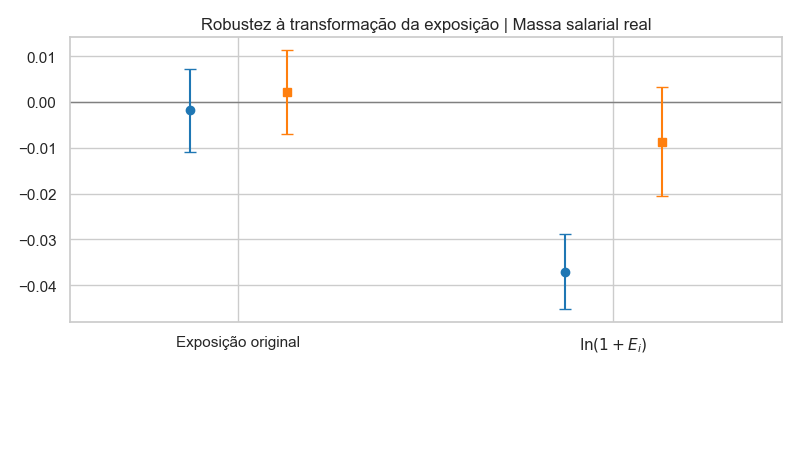

In [154]:
plotar_robustez_log("Massa salarial real", mostrar_legenda=False)

##### Robustez à exclusão da cauda superior da exposição

Esta checagem avalia quanto o diferencial pós-PSI depende dos municípios com maior exposição histórica ao Finame. Comparamos a amostra completa com dois recortes que excluem exposições acima dos percentis 99 e 95. Os cortes são calculados entre os municípios com exposição positiva na amostra comum aos dois desfechos, uma vez por município. Municípios com exposição zero e municípios exatamente no ponto de corte permanecem na amostra.

A exposição original é padronizada uma única vez na amostra completa de robustez, conforme a checagem logarítmica acima. Mantemos essa mesma escala nos recortes, assim como os controles, os efeitos fixos, o agrupamento dos erros-padrão por município e a janela de 2005 a 2013. O pós-PSI é 2010–2013 e 2009 é tratado como transição. Os modelos com todos os controles incluem a tendência linear e as covariáveis municipais de 2005.

A tabela reporta os limites de exposição, o número de municípios, o diferencial pós-PSI, o IC de 95% e o teste de Wald do estudo de eventos. O Wald testa os coeficientes de 2005–2007 no modelo sem controles e os desvios de 2005–2006 no modelo com tendência linear, cuja inclinação é ancorada em 2007 e 2008. Mudanças entre recortes indicam sensibilidade à composição da amostra.

In [155]:
exposicao_cauda = exposicao_faixas.reindex(municipios_robustez)
assert np.isfinite(exposicao_cauda).all() and exposicao_cauda.ge(0).all()
cortes_cauda = exposicao_cauda[exposicao_cauda.gt(0)].quantile([0.99, 0.95])
assert np.isfinite(cortes_cauda).all()
recortes_cauda = {
    "Amostra completa": np.inf,
    "Até o P99": cortes_cauda.loc[0.99],
    "Até o P95": cortes_cauda.loc[0.95],
}
exposicao_escala_fixa = medidas_exposicao_log["Exposição original"]
prespecificacoes_cauda = [
    ("Sem controles", "Sem controles", []),
    ("Com todos os controles", especificacao_tendencia, termos_controle_emp + [termo_tendencia]),
]
resultados_cauda = []
modelos_cauda = {}
for recorte, corte in recortes_cauda.items():
    ids_recorte = exposicao_cauda[exposicao_cauda.le(corte)].index
    for desfecho, (painel, dependente) in paineis_robustez.items():
        dados = painel.loc[painel.index.get_level_values("id_municipio").isin(ids_recorte)].copy()
        assert len(dados) == len(ids_recorte) * len(anos_did_emp)
        ano = dados.index.get_level_values("ano")
        z = dados.index.get_level_values("id_municipio").map(exposicao_escala_fixa).to_numpy()
        for t in anos_evento_emp:
            dados[f"expo_{t}"] = z * (ano == t)
        dados["expo_pos"] = z * (ano >= 2010)
        dados[termo_tendencia] = z * (ano - 2008)

        for rotulo, nome, termos in prespecificacoes_cauda:
            efeitos = efeitos_fixos_did(dados, nome)
            evento = PanelOLS(
                dados[dependente], dados[regressores_evento(termos_evento_emp, termos, nome)], **efeitos,
            ).fit(cov_type="clustered", cluster_entity=True)
            teste = wald_pre_exposicao(evento, termos_wald_evento)
            ajuste = PanelOLS(
                dados[dependente], dados[["expo_pos", "expo_2009"] + termos], **efeitos,
            ).fit(cov_type="clustered", cluster_entity=True)
            modelos_cauda[desfecho, recorte, rotulo] = (ajuste, teste)
            ic = ajuste.conf_int().loc["expo_pos"]
            resultados_cauda.append({
                "Desfecho": desfecho, "Amostra": recorte, "Modelo": rotulo,
                "Municípios": len(ids_recorte), "Limite Eᵢ": corte,
                "Wald": teste.stat, "p_Wald": teste.pval, "Diferencial": ajuste.params["expo_pos"],
                "IC 95% inf.": ic["lower"], "IC 95% sup.": ic["upper"], "p_DiD": ajuste.pvalues["expo_pos"],
            })

tabela_cauda = pd.DataFrame(resultados_cauda).set_index(["Desfecho", "Amostra", "Modelo"]).sort_index(level=0, sort_remaining=False)
print(tabela_cauda.to_string(float_format="{:.4f}".format))

                                                             Municípios  Limite Eᵢ    Wald  p_Wald  Diferencial  IC 95% inf.  IC 95% sup.  p_DiD
Desfecho            Amostra          Modelo                                                                                                     
Emprego formal      Amostra completa Sem controles                 5549        inf 20.4428  0.0001       0.0072       0.0007       0.0137 0.0293
                                     Com todos os controles        5549        inf  2.6889  0.2607       0.0023      -0.0057       0.0104 0.5726
                    Até o P99        Sem controles                 5528  1234.9317 36.0660  0.0000      -0.0064      -0.0175       0.0046 0.2555
                                     Com todos os controles        5528  1234.9317  3.4459  0.1785       0.0045      -0.0089       0.0178 0.5103
                    Até o P95        Sem controles                 5444   437.9661 19.8927  0.0002      -0.0186      -0.0344      

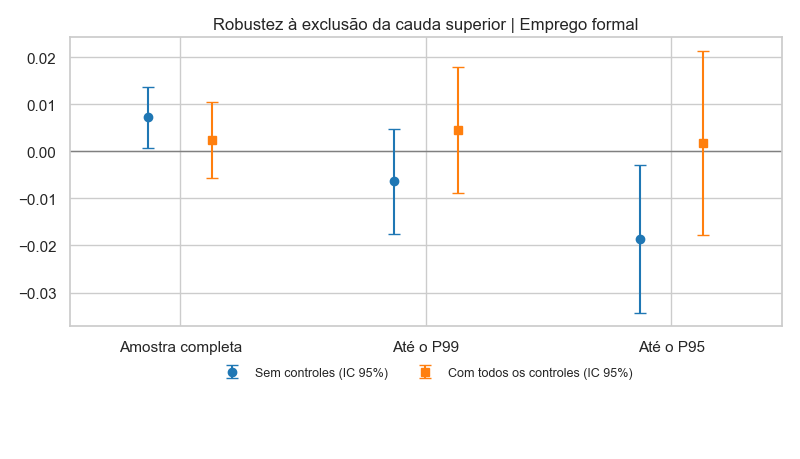

In [156]:
def plotar_robustez_cauda(desfecho, mostrar_legenda):
    fig, eixo = plt.subplots(figsize=(8, 4.6))
    recortes = list(recortes_cauda)
    posicoes = np.arange(len(recortes))
    eixo.axhline(0, color="0.5", linewidth=1)
    for modelo, cor, marcador, deslocamento in [
        ("Sem controles", "tab:blue", "o", -0.13),
        ("Com todos os controles", "tab:orange", "s", 0.13),
    ]:
        resultados = tabela_cauda.xs((desfecho, modelo), level=("Desfecho", "Modelo")).reindex(recortes)
        coef = resultados["Diferencial"]
        eixo.errorbar(
            posicoes + deslocamento, coef,
            yerr=[coef - resultados["IC 95% inf."], resultados["IC 95% sup."] - coef],
            fmt=marcador, color=cor, capsize=4, label=f"{modelo} (IC 95%)",
        )
    eixo.set_title(f"Robustez à exclusão da cauda superior | {desfecho}")
    eixo.set_xticks(posicoes, recortes)
    eixo.set_xlim(-0.45, len(posicoes) - 0.55)
    fig.tight_layout(rect=(0, 0.19, 1, 1))
    if mostrar_legenda:
        eixo.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=2)
    with BytesIO() as imagem:
        fig.savefig(imagem, format="png", bbox_inches=fig.bbox_inches)
        display(Image(data=imagem.getvalue()))
    plt.close(fig)


plotar_robustez_cauda("Emprego formal", mostrar_legenda=True)

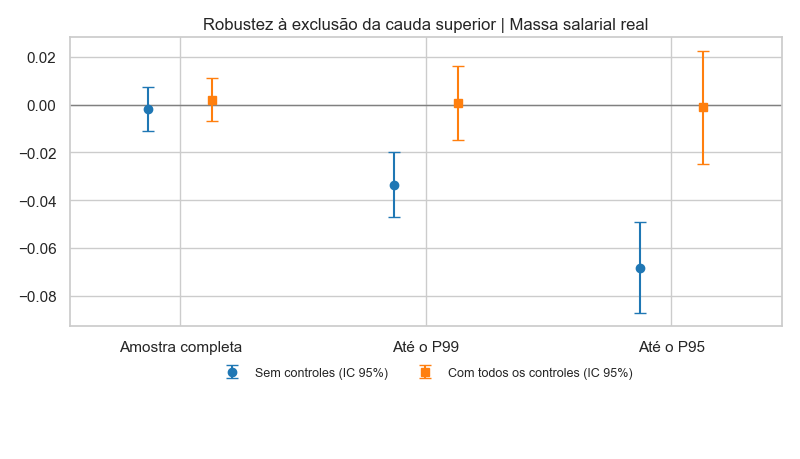

In [157]:
plotar_robustez_cauda("Massa salarial real", mostrar_legenda=True)

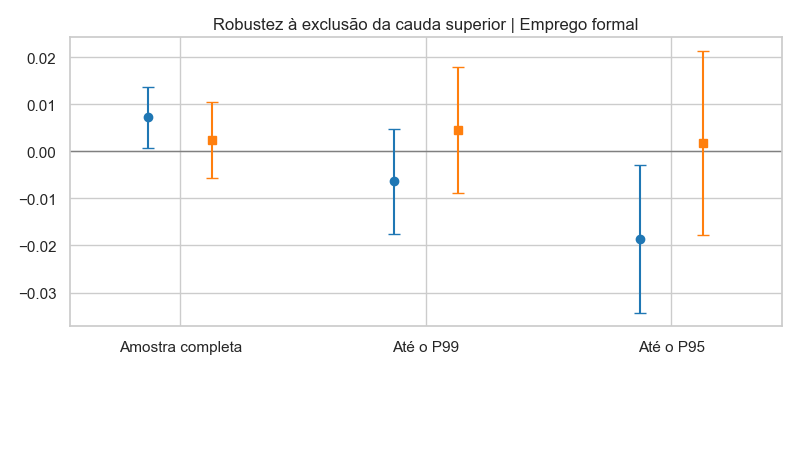

In [158]:
plotar_robustez_cauda("Emprego formal", mostrar_legenda=False)

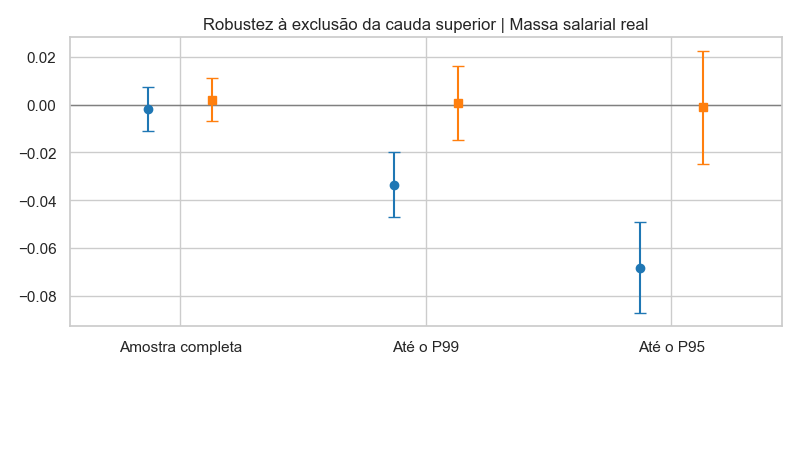

In [159]:
plotar_robustez_cauda("Massa salarial real", mostrar_legenda=False)

##### Tabelas de regressão

A tabela principal compara as quatro especificações do diferencial médio pós-PSI. O apêndice apresenta os coeficientes anuais do estudo de eventos e os diferenciais por tercis. As tabelas de robustez comparam o ano-base dos controles, a transformação logarítmica e a exclusão da cauda superior.

Cada célula de resultado mostra o coeficiente e, na linha abaixo, seu intervalo de confiança de 95%. Os erros-padrão são agrupados por município. Os asteriscos usam o valor-p bilateral sem arredondamento ($^{*}p<0{,}10$, $^{**}p<0{,}05$, $^{***}p<0{,}01$). A tabela informa R² within e F robusto do modelo de cada coluna. O Wald de pré-tendências vem do estudo de eventos correspondente e é reportado como χ², graus de liberdade e valor-p. O símbolo — indica um termo ausente da especificação. O Wald testa 2005–2007 nos modelos sem tendência e os desvios de 2005 e 2006 nos modelos com tendência. No DiD por tercis, o Wald testa conjuntamente os nove coeficientes pré-PSI.

Os coeficientes contínuos são expressos em log do desfecho por desvio-padrão de exposição. Na análise por tercis, cada coeficiente compara a mudança na faixa à do grupo de exposição zero. Os efeitos fixos e as interações das covariáveis com ano são indicados em cada tabela.

In [160]:
tabelas_exportacao_psi = {}

def formatar_coeficiente_artigo(coef, inferior, superior, p):
    estrelas = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""
    return f"{coef:.4f}{estrelas}\n[{inferior:.4f}, {superior:.4f}]"


def mostrar_tabela_artigo(tabela, titulo):
    tabelas_exportacao_psi[titulo] = tabela.copy()
    display(
        tabela.style.set_caption(titulo)
        .set_table_styles([
            {"selector": "td", "props": [("white-space", "pre-line"), ("text-align", "center"), ("padding", "5px 10px")]},
            {"selector": "caption", "props": [("caption-side", "top"), ("font-weight", "bold"), ("text-align", "left")]},
            {"selector": "thead", "props": [("border-top", "2px solid"), ("border-bottom", "1px solid")]},
            {"selector": "tbody", "props": [("border-bottom", "2px solid")]},
        ])
    )



def coeficiente_artigo(resultado, termo):
    if termo not in resultado.params.index:
        return "—"
    inferior, superior = resultado.conf_int().loc[termo]
    return formatar_coeficiente_artigo(
        resultado.params[termo], inferior, superior, resultado.pvalues[termo],
    )


def diagnosticos_artigo(resultado, teste_wald, ano_base=2005):
    f_robusto = resultado.f_statistic_robust
    efeitos_uf = resultado.model.other_effects
    tem_covariaveis = any("_x_" in termo for termo in resultado.params.index)
    return {
        "R² within": f"{resultado.rsquared_within:.4f}",
        "F robusto": f"{f_robusto.stat:.4g}",
        "F robusto (valor-p)": f"{f_robusto.pval:.4g}",
        "Wald de pré-tendências (χ²)": f"{teste_wald.stat:.4g}",
        "Wald (graus de liberdade)": int(teste_wald.df),
        "Wald (valor-p)": f"{teste_wald.pval:.4g}",
        "Observações": resultado.nobs,
        "Municípios": int(resultado.entity_info["total"]),
        "Efeitos fixos de município": "Sim" if resultado.model.entity_effects else "Não",
        "Efeitos fixos de ano": "Absorvidos por UF × ano" if efeitos_uf else "Sim",
        "Efeitos fixos de UF × ano": "Sim" if efeitos_uf else "Não",
        "PIB per capita, população e indústria × ano": f"Base {ano_base}" if tem_covariaveis else "Não",
    }


def coluna_did_artigo(resultado, teste_wald, ano_base=2005):
    return {
        "Pós-PSI, 2010–2013 (β)": coeficiente_artigo(resultado, "expo_pos"),
        "Transição, 2009 (θ)": coeficiente_artigo(resultado, "expo_2009"),
        "Tendência linear da exposição (ρ)": coeficiente_artigo(resultado, termo_tendencia),
        **diagnosticos_artigo(resultado, teste_wald, ano_base),
    }


rotulos_modelos_artigo = [
    "(1) Sem controles", "(2) Covariáveis de 2005",
    "(3) Covariáveis + UF × ano", "(4) Covariáveis + UF × ano + tendência",
]
desfechos_artigo = {
    "Emprego formal": (modelos_pos_emp, eventos_emp),
    "Massa salarial real": (modelos_pos_massa, eventos_massa),
}
for desfecho, (modelos, eventos) in desfechos_artigo.items():
    colunas = {}
    for rotulo, (nome, resultado) in zip(rotulos_modelos_artigo, modelos.items()):
        teste = wald_pre_exposicao(eventos[nome], termos_wald_evento)
        colunas[rotulo] = coluna_did_artigo(resultado, teste)
    mostrar_tabela_artigo(pd.DataFrame(colunas), f"DiD contínuo | {desfecho}")

,(1) Sem controles,(2) Covariáveis de 2005,(3) Covariáveis + UF × ano,(4) Covariáveis + UF × ano + tendência
"Pós-PSI, 2010–2013 (β)","0.0072** [0.0007, 0.0137]","0.0135*** [0.0065, 0.0206]","0.0077** [0.0009, 0.0144]","0.0023 [-0.0057, 0.0104]"
"Transição, 2009 (θ)","0.0041 [-0.0015, 0.0096]","0.0077** [0.0013, 0.0141]","0.0066* [-0.0001, 0.0134]","0.0040 [-0.0033, 0.0112]"
Tendência linear da exposição (ρ),—,—,—,"0.0011 [-0.0009, 0.0030]"
R² within,0.0002,-0.3715,-0.0630,-0.0655
F robusto,2.386,6.484,3.877,3.739
F robusto (valor-p),0.092,8.702e-23,9.778e-11,1.86e-10
Wald de pré-tendências (χ²),20.44,10.63,6.247,2.689
Wald (graus de liberdade),3,3,3,2
Wald (valor-p),0.0001374,0.01389,0.1002,0.2607
Observações,49941,49941,49941,49941


,(1) Sem controles,(2) Covariáveis de 2005,(3) Covariáveis + UF × ano,(4) Covariáveis + UF × ano + tendência
"Pós-PSI, 2010–2013 (β)","-0.0018 [-0.0109, 0.0073]","0.0233*** [0.0143, 0.0323]","0.0102** [0.0024, 0.0180]","0.0021 [-0.0070, 0.0112]"
"Transição, 2009 (θ)","-0.0049 [-0.0121, 0.0024]","0.0120*** [0.0049, 0.0191]","0.0064* [-0.0008, 0.0137]","0.0024 [-0.0053, 0.0102]"
Tendência linear da exposição (ρ),—,—,—,"0.0016 [-0.0006, 0.0038]"
R² within,0.0000,-2.5434,-0.4798,-0.4926
F robusto,1.459,14.7,7.853,7.605
F robusto (valor-p),0.2325,1.04e-64,1.683e-29,2.874e-29
Wald de pré-tendências (χ²),22.11,14.29,4.287,1.157
Wald (graus de liberdade),3,3,3,2
Wald (valor-p),6.187e-05,0.002533,0.2321,0.5607
Observações,49941,49941,49941,49941


In [161]:
for desfecho, (_, eventos) in desfechos_artigo.items():
    colunas = {}
    for rotulo, (nome, resultado) in zip(rotulos_modelos_artigo, eventos.items()):
        coluna = {}
        for ano in anos_did_emp:
            if ano == 2008:
                coluna[ano] = "Referência"
            elif ano == 2007 and nome == especificacao_tendencia:
                coluna[ano] = "Âncora da tendência"
            else:
                linha = "Transição, 2009 (θ)" if ano == 2009 else ano
                coluna[linha] = coeficiente_artigo(resultado, f"expo_{ano}")
        coluna["Tendência linear da exposição (ρ)"] = coeficiente_artigo(resultado, termo_tendencia)
        teste = wald_pre_exposicao(resultado, termos_wald_evento)
        colunas[rotulo] = {**coluna, **diagnosticos_artigo(resultado, teste)}
    mostrar_tabela_artigo(pd.DataFrame(colunas), f"Estudo de eventos | {desfecho}")

colunas_faixas = {}
for desfecho, resultado in modelos_pos_faixas.items():
    coluna = {}
    for faixa, rotulo in faixas_positivas.items():
        coluna[f"{rotulo} | Pós-PSI (β)"] = coeficiente_artigo(resultado, f"faixa_{faixa}_pos")
        coluna[f"{rotulo} | Transição (θ)"] = coeficiente_artigo(resultado, f"faixa_{faixa}_2009")
    colunas_faixas[desfecho] = {**coluna, **diagnosticos_artigo(resultado, testes_wald_faixas[desfecho])}
mostrar_tabela_artigo(pd.DataFrame(colunas_faixas), "DiD por tercis | Referência: exposição zero")

,(1) Sem controles,(2) Covariáveis de 2005,(3) Covariáveis + UF × ano,(4) Covariáveis + UF × ano + tendência
2005,"-0.0039 [-0.0113, 0.0036]","-0.0130*** [-0.0210, -0.0050]","-0.0090** [-0.0176, -0.0003]","0.0122 [-0.0028, 0.0271]"
2006,"-0.0108*** [-0.0173, -0.0044]","-0.0095** [-0.0168, -0.0022]","-0.0086** [-0.0163, -0.0008]","0.0056 [-0.0034, 0.0145]"
2007,"-0.0101*** [-0.0154, -0.0047]","-0.0073** [-0.0133, -0.0014]","-0.0071** [-0.0131, -0.0011]",Âncora da tendência
2008,Referência,Referência,Referência,Referência
"Transição, 2009 (θ)","-0.0021 [-0.0075, 0.0033]","0.0003 [-0.0060, 0.0065]","0.0005 [-0.0060, 0.0070]","-0.0065 [-0.0173, 0.0042]"
2010,"-0.0038 [-0.0097, 0.0021]","0.0045 [-0.0022, 0.0113]","0.0020 [-0.0046, 0.0087]","-0.0121 [-0.0282, 0.0040]"
2011,"-0.0001 [-0.0060, 0.0057]","0.0069** [0.0005, 0.0134]","0.0027 [-0.0035, 0.0090]","-0.0184* [-0.0392, 0.0023]"
2012,"0.0052 [-0.0014, 0.0119]","0.0056 [-0.0018, 0.0130]","0.0012 [-0.0060, 0.0084]","-0.0270** [-0.0539, -0.0002]"
2013,"0.0028 [-0.0044, 0.0099]","0.0071* [-0.0012, 0.0154]","0.0002 [-0.0073, 0.0078]","-0.0350** [-0.0670, -0.0031]"
Tendência linear da exposição (ρ),—,—,—,"0.0071** [0.0011, 0.0131]"


,(1) Sem controles,(2) Covariáveis de 2005,(3) Covariáveis + UF × ano,(4) Covariáveis + UF × ano + tendência
2005,"0.0010 [-0.0082, 0.0102]","-0.0177*** [-0.0270, -0.0084]","-0.0099* [-0.0200, 0.0002]","0.0090 [-0.0080, 0.0260]"
2006,"-0.0084** [-0.0156, -0.0012]","-0.0116*** [-0.0198, -0.0034]","-0.0083* [-0.0172, 0.0006]","0.0043 [-0.0065, 0.0151]"
2007,"-0.0106*** [-0.0167, -0.0046]","-0.0071** [-0.0138, -0.0005]","-0.0063* [-0.0134, 0.0008]",Âncora da tendência
2008,Referência,Referência,Referência,Referência
"Transição, 2009 (θ)","-0.0094*** [-0.0162, -0.0025]","0.0029 [-0.0040, 0.0098]","0.0003 [-0.0071, 0.0077]","-0.0060 [-0.0188, 0.0069]"
2010,"-0.0124*** [-0.0200, -0.0048]","0.0083** [0.0006, 0.0161]","0.0030 [-0.0047, 0.0107]","-0.0096 [-0.0288, 0.0096]"
2011,"-0.0103** [-0.0193, -0.0013]","0.0155*** [0.0072, 0.0237]","0.0054 [-0.0026, 0.0134]","-0.0135 [-0.0387, 0.0117]"
2012,"0.0019 [-0.0065, 0.0103]","0.0148*** [0.0057, 0.0239]","0.0042 [-0.0043, 0.0127]","-0.0210 [-0.0528, 0.0108]"
2013,"-0.0044 [-0.0138, 0.0050]","0.0184*** [0.0080, 0.0287]","0.0035 [-0.0055, 0.0126]","-0.0279 [-0.0658, 0.0100]"
Tendência linear da exposição (ρ),—,—,—,"0.0063* [-0.0008, 0.0134]"


,Emprego formal,Massa salarial real
Tercil 1 (baixo) | Pós-PSI (β),"-0.0025 [-0.0234, 0.0183]","0.0002 [-0.0247, 0.0251]"
Tercil 1 (baixo) | Transição (θ),"0.0019 [-0.0174, 0.0212]","0.0006 [-0.0230, 0.0241]"
Tercil 2 (médio) | Pós-PSI (β),"-0.0083 [-0.0307, 0.0141]","0.0029 [-0.0235, 0.0292]"
Tercil 2 (médio) | Transição (θ),"-0.0100 [-0.0296, 0.0096]","-0.0015 [-0.0237, 0.0207]"
Tercil 3 (alto) | Pós-PSI (β),"-0.0077 [-0.0298, 0.0145]","0.0026 [-0.0226, 0.0277]"
Tercil 3 (alto) | Transição (θ),"-0.0030 [-0.0217, 0.0157]","0.0016 [-0.0191, 0.0224]"
R² within,0.0233,-0.3372
F robusto,3.223,6.668
F robusto (valor-p),6.342e-09,5.758e-27
Wald de pré-tendências (χ²),9.777,12.23


In [162]:
for titulo, modelos, condicoes in [
    ("Ano-base dos controles", modelos_ancoras, [
        (f"Base {ano} | {'Com' if tendencia else 'Sem'} tendência", ano, tendencia, ano)
        for ano in (2005, 2008) for tendencia in (False, True)
    ]),
    ("Transformação logarítmica", modelos_robustez_log, [
        (f"{medida} | {modelo}", medida, modelo, 2005)
        for medida in medidas_exposicao_log for modelo in ("Sem controles", "Com todos os controles")
    ]),
    ("Exclusão da cauda superior", modelos_cauda, [
        (f"{recorte} | {modelo}", recorte, modelo, 2005)
        for recorte in recortes_cauda for modelo in ("Sem controles", "Com todos os controles")
    ]),
]:
    blocos = []
    for desfecho in desfechos_artigo:
        colunas = {}
        for rotulo, condicao, modelo, ano_base in condicoes:
            resultado, teste = modelos[desfecho, condicao, modelo]
            colunas[rotulo] = coluna_did_artigo(resultado, teste, ano_base)
        bloco = pd.DataFrame(colunas)
        bloco = pd.concat([pd.DataFrame("", index=[desfecho], columns=bloco.columns),
                           bloco])
        blocos.append(bloco)
    mostrar_tabela_artigo(pd.concat(blocos), titulo)

,Base 2005 | Sem tendência,Base 2005 | Com tendência,Base 2008 | Sem tendência,Base 2008 | Com tendência
Emprego formal,,,,
"Pós-PSI, 2010–2013 (β)","0.0077** [0.0009, 0.0144]","0.0023 [-0.0057, 0.0104]","0.0025 [-0.0045, 0.0094]","0.0009 [-0.0073, 0.0091]"
"Transição, 2009 (θ)","0.0066* [-0.0001, 0.0134]","0.0040 [-0.0033, 0.0112]","0.0042 [-0.0026, 0.0110]","0.0034 [-0.0037, 0.0105]"
Tendência linear da exposição (ρ),—,"0.0011 [-0.0009, 0.0030]",—,"0.0003 [-0.0017, 0.0023]"
R² within,-0.0630,-0.0655,0.0233,0.0246
F robusto,3.877,3.739,3.886,3.746
F robusto (valor-p),9.778e-11,1.86e-10,8.894e-11,1.73e-10
Wald de pré-tendências (χ²),6.247,2.689,3.792,2.647
Wald (graus de liberdade),3,2,3,2
Wald (valor-p),0.1002,0.2607,0.2848,0.2662


,Exposição original | Sem controles,Exposição original | Com todos os controles,ln(1 + Eᵢ) | Sem controles,ln(1 + Eᵢ) | Com todos os controles
Emprego formal,,,,
"Pós-PSI, 2010–2013 (β)","0.0072** [0.0007, 0.0137]","0.0023 [-0.0057, 0.0104]","-0.0083** [-0.0154, -0.0012]","-0.0036 [-0.0140, 0.0068]"
"Transição, 2009 (θ)","0.0041 [-0.0015, 0.0096]","0.0040 [-0.0033, 0.0112]","-0.0097*** [-0.0165, -0.0029]","-0.0016 [-0.0096, 0.0064]"
Tendência linear da exposição (ρ),—,"0.0011 [-0.0009, 0.0030]",—,"0.0002 [-0.0021, 0.0026]"
R² within,0.0001,-0.0655,0.0002,0.0194
F robusto,2.386,3.739,4.337,3.528
F robusto (valor-p),0.092,1.86e-10,0.01308,1.569e-09
Wald de pré-tendências (χ²),20.44,2.689,25.62,3.527
Wald (graus de liberdade),3,2,3,2
Wald (valor-p),0.0001374,0.2607,1.148e-05,0.1714


,Amostra completa | Sem controles,Amostra completa | Com todos os controles,Até o P99 | Sem controles,Até o P99 | Com todos os controles,Até o P95 | Sem controles,Até o P95 | Com todos os controles
Emprego formal,,,,,,
"Pós-PSI, 2010–2013 (β)","0.0072** [0.0007, 0.0137]","0.0023 [-0.0057, 0.0104]","-0.0064 [-0.0175, 0.0046]","0.0045 [-0.0089, 0.0178]","-0.0186** [-0.0344, -0.0029]","0.0019 [-0.0177, 0.0214]"
"Transição, 2009 (θ)","0.0041 [-0.0015, 0.0096]","0.0040 [-0.0033, 0.0112]","-0.0079* [-0.0166, 0.0008]","0.0032 [-0.0077, 0.0141]","-0.0205*** [-0.0339, -0.0071]","0.0007 [-0.0137, 0.0150]"
Tendência linear da exposição (ρ),—,"0.0011 [-0.0009, 0.0030]",—,"-0.0013 [-0.0046, 0.0020]",—,"-0.0010 [-0.0056, 0.0035]"
R² within,0.0001,-0.0655,0.0005,-0.0438,0.0030,-0.0335
F robusto,2.386,3.739,1.576,3.448,4.701,3.327
F robusto (valor-p),0.092,1.86e-10,0.2067,3.5e-09,0.009092,1.151e-08
Wald de pré-tendências (χ²),20.44,2.689,36.07,3.446,19.89,3.28
Wald (graus de liberdade),3,2,3,2,3,2
Wald (valor-p),0.0001374,0.2607,7.251e-08,0.1785,0.0001787,0.194


##### Exportação das tabelas de regressão

Execute as células de **Tabelas de regressão** acima para atualizar as oito tabelas em memória. A primeira célula abaixo exporta um PNG por tabela, a 300 dpi, e reúne as imagens em um ZIP. A segunda exporta um arquivo Excel com uma aba por tabela. Os caminhos dos arquivos aparecem ao fim de cada execução.

In [163]:
pasta_tabelas_psi = raiz_projeto / "outputs" / "tabelas_psi"
pasta_tabelas_psi.mkdir(parents=True, exist_ok=True)
nomes_tabelas_psi = [
    "DiD emprego", "DiD massa salarial", "Eventos emprego", "Eventos massa salarial",
    "DiD por tercis", "Robustez ano-base", "Robustez log exposição", "Robustez cauda superior",
]
assert len(tabelas_exportacao_psi) == len(nomes_tabelas_psi), "Execute as três células de tabelas de regressão."
nota_tabelas_psi = (
    "IC de 95% abaixo dos coeficientes. Erros-padrão agrupados por município. "
    "* p < 0,10 | ** p < 0,05 | *** p < 0,01. Wald (χ²) do estudo de eventos correspondente. — indica termo ausente da especificação."
)


def exportar_tabela_png_psi(tabela, titulo, arquivo):

    pesos = [1.7] + [1] * len(tabela.columns)
    larguras = np.array(pesos) / sum(pesos)
    largura_figura = max(7, 2.2 + 1.75 * len(tabela.columns))
    limites_pt = larguras * largura_figura * 0.93 * 72 * 0.76

    def quebrar(valor, limite_pt, negrito=False):
        fonte = FontProperties(family="serif", size=9, weight="bold" if negrito else "normal")
        linhas = []
        for parte in str(valor).splitlines():
            atual = ""
            for palavra in parte.split():
                candidata = f"{atual} {palavra}".strip()
                if atual and TextPath((0, 0), candidata, prop=fonte).get_extents().width > limite_pt:
                    linhas.append(atual)
                    atual = palavra
                else:
                    atual = candidata
            linhas.append(atual)
        return "\n".join(linhas)

    matriz = [[""] + [quebrar(nome, limite, True) for nome, limite in zip(tabela.columns, limites_pt[1:])]]
    matriz += [
        [quebrar(valor, limite) for valor, limite in zip([indice, *linha], limites_pt)]
        for indice, linha in tabela.iterrows()
    ]
    alturas = [max(texto.count("\n") + 1 for texto in linha) for linha in matriz]
    fig = plt.figure(figsize=(largura_figura, 1.4 + 0.24 * sum(alturas)), facecolor="white")
    eixo = fig.add_axes([0.035, 0.16, 0.93, 0.72])
    eixo.set_axis_off()
    grade = eixo.table(cellText=matriz, cellLoc="center", colWidths=larguras, bbox=[0, 0, 1, 1])
    grade.auto_set_font_size(False)
    grade.set_fontsize(9)
    for (i, j), celula in grade.get_celld().items():
        celula.set_height(alturas[i] / sum(alturas))
        celula.set_facecolor("white")
        celula.set_edgecolor("#303030")
        celula.visible_edges = "TB" if i == 0 else "B" if i == len(matriz) - 1 else ""
        celula.set_text_props(
            color="#161616", fontfamily="serif", fontweight="bold" if i == 0 else "normal",
            ha="left" if j == 0 else "center",
        )
    fig.text(0.035, 0.94, titulo, fontfamily="serif", fontsize=13, fontweight="bold", color="#161616", va="top")
    fig.text(0.035, 0.025, "\n".join(wrap(nota_tabelas_psi, 110)),
             fontfamily="serif", fontsize=8, color="#161616", va="bottom")
    fig.savefig(arquivo, dpi=300, facecolor="white")
    plt.close(fig)

zip_tabelas_psi = pasta_tabelas_psi / "Tabelas de regressão PSI - PNG.zip"
with ZipFile(zip_tabelas_psi, "w", compression=ZIP_DEFLATED) as pacote:
    for numero, (titulo, tabela) in enumerate(tabelas_exportacao_psi.items(), start=1):
        imagem = pasta_tabelas_psi / f"{numero:02d} - {nomes_tabelas_psi[numero - 1]}.png"
        exportar_tabela_png_psi(tabela, titulo, imagem)
        pacote.write(imagem, imagem.name)
print(zip_tabelas_psi.resolve())

C:\Users\DESKTOP\Desktop\Script -  Avaliação de impacto\outputs\tabelas_psi\Tabelas de regressão PSI - PNG.zip


In [164]:
pasta_tabelas_psi = raiz_projeto / "outputs" / "tabelas_psi"
pasta_tabelas_psi.mkdir(parents=True, exist_ok=True)
nomes_tabelas_psi = [
    "DiD emprego", "DiD massa salarial", "Eventos emprego", "Eventos massa salarial",
    "DiD por tercis", "Robustez ano-base", "Robustez log exposição", "Robustez cauda superior",
]
assert len(tabelas_exportacao_psi) == len(nomes_tabelas_psi), "Execute as três células de tabelas de regressão."
nota_tabelas_psi = (
    "IC de 95% abaixo dos coeficientes. Erros-padrão agrupados por município. "
    "* p < 0,10 | ** p < 0,05 | *** p < 0,01. Wald (χ²) do estudo de eventos correspondente. — indica termo ausente da especificação."
)


excel_tabelas_psi = pasta_tabelas_psi / "Tabelas de regressão PSI.xlsx"
with pd.ExcelWriter(excel_tabelas_psi, engine="openpyxl") as escritor:
    for aba, (titulo, tabela) in zip(nomes_tabelas_psi, tabelas_exportacao_psi.items()):
        tabela.to_excel(escritor, sheet_name=aba, startrow=2)
        planilha = escritor.sheets[aba]
        ultima_coluna = len(tabela.columns) + 1
        planilha.merge_cells(start_row=1, start_column=1, end_row=1, end_column=ultima_coluna)
        planilha["A1"] = titulo
        planilha["A1"].font = Font(name="Calibri", bold=True, size=13)
        planilha.freeze_panes = "B4"
        planilha.sheet_view.showGridLines = False

        for celula in planilha[3]:
            celula.font = Font(name="Calibri", bold=True, color="FFFFFF")
            celula.fill = PatternFill("solid", fgColor="24364B")
            celula.alignment = Alignment(wrap_text=True, vertical="center", horizontal="center")
        planilha.row_dimensions[3].height = 34
        planilha.column_dimensions["A"].width = 57
        for coluna in range(2, ultima_coluna + 1):
            planilha.column_dimensions[get_column_letter(coluna)].width = 31

        for linha in planilha.iter_rows(min_row=4, max_row=3 + len(tabela), max_col=ultima_coluna):
            altura = max(str(celula.value).count("\n") + 1 for celula in linha) * 15 + 6
            planilha.row_dimensions[linha[0].row].height = altura
            for celula in linha:
                celula.alignment = Alignment(wrap_text=True, vertical="center",
                                             horizontal="left" if celula.column == 1 else "center")
                if celula.row % 2 == 0:
                    celula.fill = PatternFill("solid", fgColor="F0F3F6")
                if celula.row == 3 + len(tabela):
                    celula.border = Border(bottom=Side(style="thin", color="24364B"))

        linha_nota = 5 + len(tabela)
        planilha.merge_cells(start_row=linha_nota, start_column=1, end_row=linha_nota, end_column=ultima_coluna)
        nota = planilha.cell(linha_nota, 1, nota_tabelas_psi)
        nota.alignment = Alignment(wrap_text=True, vertical="center")
        nota.font = Font(name="Calibri", italic=True, size=10)
        planilha.row_dimensions[linha_nota].height = 32
print(excel_tabelas_psi.resolve())

C:\Users\DESKTOP\Desktop\Script -  Avaliação de impacto\outputs\tabelas_psi\Tabelas de regressão PSI.xlsx
